# 06 — Peak Forecasting and Uncertainty

**Context.** Previous stages cleaned and validated 2019–2025 ERCOT system and eight-weather-zone load, examined demand patterns and peak events, integrated weather data, and evaluated hourly forecasts. The selected regional Ridge model (α = 100) achieved a 2025 system WAPE of approximately **3.258%** against **4.519%** for the Lag-24 baseline, but underestimated the observed annual peak by about **1.12 GW**. All observed top-1% load hours were underestimated, even though peak timing was off by only about one hour.

**Objective.** Translate hourly predictions into calibrated high-load and peak-demand scenarios for capacity planning. Stage 05 addresses hourly load; Stage 06 addresses peak demand and uncertainty; Stage 07 compares those peak-demand scenarios with capacity availability.

**Evaluation boundary.** Use time-ordered out-of-sample 2023–2024 errors for calibration and reserve 2025 for subsequent evaluation. This is a historical evaluation using realized weather and historical lag features, not a genuinely advance-issued full-year operational forecast.

## 06.01 — Environment and input audit

Locate the project, load 2025 system and regional hourly forecasts, verify expected record counts, and inspect historical-validation files. Paths printed in notebook outputs are shown relative to the project root.

In [ ]:
# Input checks:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", context="notebook")

# ------------------------------------------------------------
# ------------------------------------------------------------
cwd = Path.cwd().resolve()

root_candidates = [
    cwd,
    cwd.parent,
    cwd.parent.parent,
]

PROJECT_ROOT = next(
    (
        path for path in root_candidates
        if (path / "report" / "tables" / "forecasting").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the project root. Make sure the notebook is inside the project, "
        "or explicitly set PROJECT_ROOT."
    )


# Display-only redaction; analysis inputs and actual file paths stay unchanged.
import builtins as _builtins
from IPython.display import display as _ipython_display

def _safe_text_for_display(value):
    return str(value).replace(str(PROJECT_ROOT), "<PROJECT_ROOT>")

def print(*args, **kwargs):
    cleaned = [
        _safe_text_for_display(a)
        if isinstance(a, (str, Path)) and str(PROJECT_ROOT) in str(a)
        else a
        for a in args
    ]
    return _builtins.print(*cleaned, **kwargs)

def display(*objects, **kwargs):
    clean_objects = []
    for obj in objects:
        if isinstance(obj, pd.DataFrame) and "path" in obj.columns:
            shown = obj.copy()
            shown["path"] = shown["path"].map(_safe_text_for_display)
            clean_objects.append(shown)
        elif isinstance(obj, pd.Series) and obj.name == "path":
            clean_objects.append(obj.map(_safe_text_for_display))
        else:
            clean_objects.append(obj)
    return _ipython_display(*clean_objects, **kwargs)

FORECAST_DIR = PROJECT_ROOT / "report" / "tables" / "forecasting"

SYSTEM_2025_PATH = (
    FORECAST_DIR / "test_2025_system_hourly_predictions.csv"
)
REGIONAL_2025_PATH = (
    FORECAST_DIR / "test_2025_regional_hourly_predictions.csv"
)

print("PROJECT_ROOT : <project root>")
print("FORECAST_DIR : report/tables/forecasting")

# ------------------------------------------------------------
# ------------------------------------------------------------
core_files = pd.DataFrame(
    [
        {
            "dataset": "2025 system hourly predictions",
            "path": SYSTEM_2025_PATH,
            "expected_rows": 8760,
        },
        {
            "dataset": "2025 regional hourly predictions",
            "path": REGIONAL_2025_PATH,
            "expected_rows": 70080,
        },
    ]
)

core_files["exists"] = core_files["path"].map(Path.exists)
core_files["size_bytes"] = core_files["path"].map(
    lambda p: p.stat().st_size if p.exists() else np.nan
)

display(core_files)

missing_files = core_files.loc[~core_files["exists"], "path"].tolist()

if missing_files:
    raise FileNotFoundError(
        "The following required inputs are missing:\n"
        + "\n".join(_safe_text_for_display(path) for path in missing_files)
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
system_2025 = pd.read_csv(SYSTEM_2025_PATH)
regional_2025 = pd.read_csv(REGIONAL_2025_PATH)

input_summary = pd.DataFrame(
    [
        {
            "dataset": "system_2025",
            "rows": len(system_2025),
            "expected_rows": 8760,
            "row_count_ok": len(system_2025) == 8760,
            "columns": system_2025.shape[1],
            "duplicate_full_rows": system_2025.duplicated().sum(),
            "total_missing_values": system_2025.isna().sum().sum(),
        },
        {
            "dataset": "regional_2025",
            "rows": len(regional_2025),
            "expected_rows": 70080,
            "row_count_ok": len(regional_2025) == 70080,
            "columns": regional_2025.shape[1],
            "duplicate_full_rows": regional_2025.duplicated().sum(),
            "total_missing_values": regional_2025.isna().sum().sum(),
        },
    ]
)

print("\nCore input quality summary:")
display(input_summary)

print("\nSystem forecast columns:")
print(system_2025.columns.tolist())

print("\nRegional forecast columns:")
print(regional_2025.columns.tolist())

print("\nFirst three system forecast rows:")
display(system_2025.head(3))

print("\nFirst three regional forecast rows:")
display(regional_2025.head(3))

# ------------------------------------------------------------
# ------------------------------------------------------------
forecast_inventory = pd.DataFrame(
    [
        {
            "filename": path.name,
            "size_bytes": path.stat().st_size,
        }
        for path in sorted(FORECAST_DIR.glob("*"))
        if path.is_file()
    ]
)

history_keywords = (
    "validation",
    "rolling",
    "backtest",
    "residual",
    "2023",
    "2024",
)

history_candidates = forecast_inventory[
    forecast_inventory["filename"].str.lower().apply(
        lambda name: any(keyword in name for keyword in history_keywords)
    )
].reset_index(drop=True)

print("\nForecasting directory inventory:")
display(forecast_inventory)

print("\nPossible 2023–2024 validation forecasts or residual files:")
if history_candidates.empty:
    print("No filename matches found; inspect whether saved evaluations contain sufficient hourly data.")
else:
    display(history_candidates)

PROJECT_ROOT : <PROJECT_ROOT>
FORECAST_DIR : <PROJECT_ROOT>/report/tables/forecasting


,dataset,path,expected_rows,exists,size_bytes
0,2025 system hourly predictions,/report/tables/forecasting/test_2025_system_hourly_predictions.csv,8760,True,931062
1,2025 regional hourly predictions,/report/tables/forecasting/test_2025_regional_hourly_predictions.csv,70080,True,6079342



Core input quality summary:


,dataset,rows,expected_rows,row_count_ok,columns,duplicate_full_rows,total_missing_values
0,system_2025,8760,8760,True,7,0,0
1,regional_2025,70080,70080,True,6,0,0



System forecast columns:
['HourEnding_utc', 'HourEnding_local', 'local_month', 'season', 'actual_system_load_mw', 'ridge_system_prediction_mw', 'lag_24_system_prediction_mw']

Regional forecast columns:
['HourEnding_utc', 'zone', 'load_mw', 'final_ridge_prediction_mw', 'lag_24', 'lag_168']

First three system forecast rows:


...

,HourEnding_utc,zone,load_mw,final_ridge_prediction_mw,lag_24,lag_168
0,2025-01-01 07:00:00+00:00,COAST,10538.553193,11558.885406,11087.471473,10805.668513
1,2025-01-01 08:00:00+00:00,COAST,10477.912860,11260.874519,10741.699556,10494.022745
2,2025-01-01 09:00:00+00:00,COAST,10363.015361,11036.333076,10513.359806,10176.946115



Forecasting directory inventory:


,filename,size_bytes
0,final_ridge_model_configuration.csv,173
1,test_2025_annual_peak_comparison.csv,891
2,test_2025_daily_peak_predictions.csv,20711
3,test_2025_high_load_comparison.csv,1077
4,test_2025_monthly_system_comparison.csv,2538
5,test_2025_regional_hourly_predictions.csv,6079342
6,test_2025_regional_model_comparison.csv,2013
7,test_2025_seasonal_system_comparison.csv,966
8,test_2025_system_hourly_predictions.csv,931062
9,test_2025_system_model_comparison.csv,267



Possible 2023–2024 validation forecasts or residual files:


,filename,size_bytes
0,validation_2023_2024_model_stability_summary.csv,507
1,validation_2023_2024_multiyear_system_comparison.csv,689
2,validation_2023_rolling_regional_comparison.csv,3018
3,validation_2023_rolling_system_comparison.csv,382
4,validation_2024_best_ridge_regional_metrics.csv,997
5,validation_2024_final_system_model_comparison.csv,330
6,validation_2024_hgb_final_system_comparison.csv,557
7,validation_2024_hgb_v1_regional_metrics.csv,1071
8,validation_2024_hgb_v2_regional_metrics.csv,1199
9,validation_2024_regional_baseline_metrics.csv,1790


**Input finding.** Files labelled `validation` in the forecasting folder appear to contain summary metrics rather than the 2023–2024 hourly prediction records needed to estimate the residual tail. Aggregate WAPE or bias cannot reconstruct a conditional residual distribution. The next steps verify the 2025 time/zone structure and locate stored historical hourly predictions.

## 06.02 — Standardize 2025 inputs

Standardize timestamp and load columns; validate UTC continuity, zone completeness, and the reconciliation between system and regional demand. Search for historical hourly prediction files.

In [ ]:

# ============================================================
# ============================================================
# ------------------------------------------------------------
# ------------------------------------------------------------
system_2025_std = system_2025.rename(
    columns={
        "HourEnding_utc": "timestamp_utc",
        "HourEnding_local": "timestamp_local",
        "actual_system_load_mw": "actual_mw",
        "ridge_system_prediction_mw": "forecast_mw",
        "lag_24_system_prediction_mw": "lag24_forecast_mw",
    }
).copy()

system_utc_index = pd.DatetimeIndex(
    pd.to_datetime(
        system_2025_std["timestamp_utc"].astype(str).tolist(),
        format="mixed",
        utc=True,
        errors="raise",
    )
)

system_2025_std["timestamp_utc"] = system_utc_index
system_2025_std["timestamp_local"] = system_utc_index.tz_convert(
    "America/Chicago"
)

print("System UTC dtype:", system_2025_std["timestamp_utc"].dtype)
print("System local time dtype:", system_2025_std["timestamp_local"].dtype)
print(
    system_2025_std[
        ["timestamp_utc", "timestamp_local"]
    ].head(3)
)

system_2025_std = (
    system_2025_std
    .sort_values("timestamp_utc")
    .reset_index(drop=True)
)

system_2025_std["residual_mw"] = (
    system_2025_std["actual_mw"]
    - system_2025_std["forecast_mw"]
)

system_2025_std["absolute_error_mw"] = (
    system_2025_std["residual_mw"].abs()
)

system_2025_std["forecast_error_pct"] = (
    100
    * system_2025_std["residual_mw"]
    / system_2025_std["actual_mw"]
)

system_2025_std["is_underforecast"] = (
    system_2025_std["residual_mw"] > 0
)

# ------------------------------------------------------------
# ------------------------------------------------------------
regional_2025_std = regional_2025.rename(
    columns={
        "HourEnding_utc": "timestamp_utc",
        "load_mw": "actual_mw",
        "final_ridge_prediction_mw": "forecast_mw",
        "lag_24": "lag24_forecast_mw",
        "lag_168": "lag168_forecast_mw",
    }
).copy()

regional_utc_index = pd.DatetimeIndex(
    pd.to_datetime(
        regional_2025_std["timestamp_utc"].astype(str).tolist(),
        format="mixed",
        utc=True,
        errors="raise",
    )
)

regional_2025_std["timestamp_utc"] = regional_utc_index

regional_2025_std["zone"] = (
    regional_2025_std["zone"]
    .astype(str)
    .str.strip()
    .str.upper()
)

regional_2025_std = (
    regional_2025_std
    .sort_values(["timestamp_utc", "zone"])
    .reset_index(drop=True)
)

regional_2025_std["residual_mw"] = (
    regional_2025_std["actual_mw"]
    - regional_2025_std["forecast_mw"]
)

regional_2025_std["absolute_error_mw"] = (
    regional_2025_std["residual_mw"].abs()
)

regional_2025_std["is_underforecast"] = (
    regional_2025_std["residual_mw"] > 0
)

# ------------------------------------------------------------
# ------------------------------------------------------------
expected_utc = pd.date_range(
    start=system_2025_std["timestamp_utc"].min(),
    end=system_2025_std["timestamp_utc"].max(),
    freq="h",
)

system_time_check = pd.DataFrame(
    {
        "check": [
            "Unique system UTC timestamps",
            "Continuous hourly system UTC timestamps",
            "System has 8,760 hours",
            "Eight regional zones",
            "Eight zones per UTC hour",
            "Unique region/timestamp combinations",
        ],
        "passed": [
            system_2025_std["timestamp_utc"].is_unique,
            (
                len(expected_utc) == len(system_2025_std)
                and system_2025_std["timestamp_utc"].reset_index(drop=True)
                    .equals(pd.Series(expected_utc))
            ),
            len(system_2025_std) == 8760,
            regional_2025_std["zone"].nunique() == 8,
            regional_2025_std.groupby("timestamp_utc")["zone"]
                .nunique().eq(8).all(),
            not regional_2025_std.duplicated(
                ["timestamp_utc", "zone"]
            ).any(),
        ],
    }
)

print("2025 standardization and integrity checks:")
display(system_time_check)

print("Region names:")
print(sorted(regional_2025_std["zone"].unique()))

print("\nSystem timestamp range:")
print(
    system_2025_std["timestamp_utc"].min(),
    "→",
    system_2025_std["timestamp_utc"].max(),
)

# ------------------------------------------------------------
# ------------------------------------------------------------
regional_sum = (
    regional_2025_std
    .groupby("timestamp_utc", as_index=False)
    .agg(
        regional_actual_sum_mw=("actual_mw", "sum"),
        regional_forecast_sum_mw=("forecast_mw", "sum"),
    )
)

system_reconciliation = system_2025_std[
    ["timestamp_utc", "actual_mw", "forecast_mw"]
].merge(
    regional_sum,
    on="timestamp_utc",
    how="left",
    validate="one_to_one",
)

system_reconciliation["actual_difference_mw"] = (
    system_reconciliation["actual_mw"]
    - system_reconciliation["regional_actual_sum_mw"]
)

system_reconciliation["forecast_difference_mw"] = (
    system_reconciliation["forecast_mw"]
    - system_reconciliation["regional_forecast_sum_mw"]
)

reconciliation_summary = pd.DataFrame(
    {
        "comparison": [
            "System actual minus summed regional actual",
            "System forecast minus summed regional forecast",
        ],
        "max_abs_difference_mw": [
            system_reconciliation["actual_difference_mw"].abs().max(),
            system_reconciliation["forecast_difference_mw"].abs().max(),
        ],
        "mean_abs_difference_mw": [
            system_reconciliation["actual_difference_mw"].abs().mean(),
            system_reconciliation["forecast_difference_mw"].abs().mean(),
        ],
    }
)

print("\nSystem versus eight-zone sum reconciliation:")
display(reconciliation_summary)

# ------------------------------------------------------------
# ------------------------------------------------------------
candidate_records = []

name_keywords = (
    "validation",
    "backtest",
    "rolling",
    "prediction",
    "forecast",
    "residual",
)

excluded_parts = {
    ".git",
    ".ipynb_checkpoints",
    "__pycache__",
}

for path in PROJECT_ROOT.rglob("*.csv"):
    if any(part in excluded_parts for part in path.parts):
        continue

    filename_lower = path.name.lower()

    if not any(keyword in filename_lower for keyword in name_keywords):
        continue

    try:
        header = pd.read_csv(path, nrows=0).columns.tolist()

        with path.open("r", encoding="utf-8", errors="ignore") as file:
            row_count = max(sum(1 for _ in file) - 1, 0)

        header_lower = [str(col).lower() for col in header]

        has_time_column = any(
            any(token in col for token in ("time", "date", "hour"))
            for col in header_lower
        )
        has_actual_like = any(
            any(token in col for token in ("actual", "load_mw", "y_true"))
            for col in header_lower
        )
        has_prediction_like = any(
            any(token in col for token in ("prediction", "forecast", "y_pred"))
            for col in header_lower
        )

        candidate_records.append(
            {
                "path": str(path.relative_to(PROJECT_ROOT)),
                "rows": row_count,
                "columns": len(header),
                "has_time_column": has_time_column,
                "has_actual_like": has_actual_like,
                "has_prediction_like": has_prediction_like,
                "column_names": header,
            }
        )

    except Exception as exc:
        candidate_records.append(
            {
                "path": str(path.relative_to(PROJECT_ROOT)),
                "rows": np.nan,
                "columns": np.nan,
                "has_time_column": False,
                "has_actual_like": False,
                "has_prediction_like": False,
                "column_names": f"READ ERROR: {exc}",
            }
        )

historical_file_search = pd.DataFrame(candidate_records)

if not historical_file_search.empty:
    historical_file_search["hourly_candidate"] = (
        historical_file_search["has_time_column"]
        & historical_file_search["has_actual_like"]
        & historical_file_search["has_prediction_like"]
        & historical_file_search["rows"].fillna(0).ge(8000)
    )

    historical_file_search = historical_file_search.sort_values(
        ["hourly_candidate", "rows"],
        ascending=[False, False],
    ).reset_index(drop=True)

print("\nLikely historical hourly-forecast files:")

if historical_file_search.empty:
    print("No CSV filenames matched the search terms.")
else:
    likely_hourly = historical_file_search[
        historical_file_search["hourly_candidate"]
    ]

    if likely_hourly.empty:
        print("No candidate file had timestamps, actuals, predictions, and at least 8,000 rows.")
        print("Showing the 20 largest files found in the scan:")
        display(historical_file_search.head(20))
    else:
        display(likely_hourly)

System UTC dtype: datetime64[us, UTC]
System local time dtype: datetime64[us, America/Chicago]
              timestamp_utc           timestamp_local
0 2025-01-01 07:00:00+00:00 2025-01-01 01:00:00-06:00
1 2025-01-01 08:00:00+00:00 2025-01-01 02:00:00-06:00
2 2025-01-01 09:00:00+00:00 2025-01-01 03:00:00-06:00
2025 standardization and integrity checks:


,check,passed
0,Unique system UTC timestamps,True
1,Continuous hourly system UTC timestamps,True
2,"System has 8,760 hours",True
3,Eight regional zones,True
4,Eight zones per UTC hour,True
5,Unique region/timestamp combinations,True


Region names:
['COAST', 'EAST', 'FWEST', 'NCENT', 'NORTH', 'SCENT', 'SOUTH', 'WEST']

System timestamp range:
2025-01-01 07:00:00+00:00 → 2026-01-01 06:00:00+00:00

System versus eight-zone sum reconciliation:


,comparison,max_abs_difference_mw,mean_abs_difference_mw
0,System actual minus summed regional actual,1.455192e-11,4.966921e-13
1,System forecast minus summed regional forecast,1.455192e-11,1.153688e-12



Likely historical hourly-forecast files:


,path,rows,columns,has_time_column,has_actual_like,has_prediction_like,column_names,hourly_candidate
0,report/tables/forecasting/test_2025_regional_hourly_predictions.csv,70080,6,True,True,True,"[HourEnding_utc, zone, load_mw, final_ridge_prediction_mw, lag_24, lag_168]",True
1,report/tables/forecasting/test_2025_system_hourly_predictions.csv,8760,7,True,True,True,"[HourEnding_utc, HourEnding_local, local_month, season, actual_system_load_mw, ridge_system_prediction_mw, lag_24_sy...",True


## 06.03 — Locate historical validation records

Inspect available in-memory dataframes and existing notebooks to find the out-of-sample hourly forecasts needed for residual-based uncertainty calibration.

In [ ]:

# ============================================================
# ============================================================

import json

# ------------------------------------------------------------
# ------------------------------------------------------------
memory_records = []

for variable_name, obj in list(globals().items()):
    if not isinstance(obj, pd.DataFrame):
        continue

    columns = [str(col) for col in obj.columns]
    columns_lower = [col.lower() for col in columns]

    has_time = any(
        any(token in col for token in ("time", "date", "hour"))
        for col in columns_lower
    )

    has_actual = any(
        any(token in col for token in ("actual", "load_mw", "y_true"))
        for col in columns_lower
    )

    has_prediction = any(
        any(token in col for token in ("prediction", "forecast", "y_pred"))
        for col in columns_lower
    )

    memory_records.append(
        {
            "variable_name": variable_name,
            "rows": len(obj),
            "columns": obj.shape[1],
            "has_time": has_time,
            "has_actual": has_actual,
            "has_prediction": has_prediction,
            "column_names": columns,
        }
    )

memory_inventory = pd.DataFrame(memory_records)

if not memory_inventory.empty:
    memory_inventory["possible_hourly_predictions"] = (
        memory_inventory["rows"].ge(8000)
        & memory_inventory["has_time"]
        & memory_inventory["has_actual"]
        & memory_inventory["has_prediction"]
    )

    memory_inventory = memory_inventory.sort_values(
        ["possible_hourly_predictions", "rows"],
        ascending=[False, False],
    ).reset_index(drop=True)

print("Possible hourly prediction DataFrames in the active kernel:")

if memory_inventory.empty:
    print("No DataFrames found in the active kernel.")
else:
    possible_memory = memory_inventory[
        memory_inventory["possible_hourly_predictions"]
    ]

    if possible_memory.empty:
        print("No hourly forecast objects matched the checks.")
        display(memory_inventory.head(20))
    else:
        display(possible_memory)

# ------------------------------------------------------------
# ------------------------------------------------------------
notebook_paths = sorted(
    path
    for path in PROJECT_ROOT.rglob("*.ipynb")
    if ".ipynb_checkpoints" not in path.parts
)

print("\nNotebooks found:")
for path in notebook_paths:
    print("-", path.relative_to(PROJECT_ROOT))

# ------------------------------------------------------------
# ------------------------------------------------------------
strong_terms = (
    "validation_2023",
    "validation_2024",
    "rolling_origin",
    "rolling validation",
    "val_2023",
    "val_2024",
)

prediction_terms = (
    "predict(",
    "prediction",
    "forecast",
    "y_pred",
    "residual",
)

notebook_matches = []

for notebook_path in notebook_paths:
    try:
        with notebook_path.open(
            "r",
            encoding="utf-8",
        ) as file:
            notebook = json.load(file)

        for cell_number, cell in enumerate(
            notebook.get("cells", []),
            start=1,
        ):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))
            source_lower = source.lower()

            has_validation_term = any(
                term in source_lower
                for term in strong_terms
            )

            has_prediction_term = any(
                term in source_lower
                for term in prediction_terms
            )

            if has_validation_term and has_prediction_term:
                nonempty_lines = [
                    line.strip()
                    for line in source.splitlines()
                    if line.strip()
                ]

                notebook_matches.append(
                    {
                        "notebook": str(
                            notebook_path.relative_to(PROJECT_ROOT)
                        ),
                        "cell_number": cell_number,
                        "first_line": (
                            nonempty_lines[0]
                            if nonempty_lines
                            else ""
                        ),
                        "source_preview": "\n".join(
                            nonempty_lines[:12]
                        ),
                    }
                )

    except Exception as exc:
        print(
            f"Could not read {notebook_path.name}: "
            f"{type(exc).__name__}: {exc}"
        )

notebook_match_df = pd.DataFrame(notebook_matches)

print("\nNotebook cells potentially producing historical validation forecasts:")

if notebook_match_df.empty:
    print("No notebook cells matched the search terms.")
else:
    display(
        notebook_match_df[
            ["notebook", "cell_number", "first_line"]
        ]
    )

    for row in notebook_match_df.itertuples():
        print("\n" + "=" * 80)
        print(
            f"Notebook: {row.notebook} | "
            f"Cell: {row.cell_number}"
        )
        print("-" * 80)
        print(row.source_preview)

## 06.04 — Review Stage 05 validation code

Inspect the saved forecasting notebook for 2023–2024 rolling-validation and prediction-generating code. The large code-excerpt outputs used during development are omitted from this GitHub copy.

In [ ]:

# ============================================================
# ============================================================

FORECAST_NOTEBOOK = (
    PROJECT_ROOT / "notebooks" / "05_load_forecasting.ipynb"
)

with FORECAST_NOTEBOOK.open("r", encoding="utf-8") as file:
    nb05 = json.load(file)

code_cells_05 = [
    cell
    for cell in nb05.get("cells", [])
    if cell.get("cell_type") == "code"
]

print(f"Total Stage 05 code cells: {len(code_cells_05)}")

target_ranges = [
    (27, 34, "Code relevant to 2024 Ridge validation"),
    (55, 60, "Code relevant to rolling 2023 validation"),
]

extracted_cells = []

for start_cell, end_cell, section_name in target_ranges:
    print("\n" + "=" * 100)
    print(section_name)
    print("=" * 100)

    for cell_number in range(start_cell, end_cell + 1):
        if cell_number > len(code_cells_05):
            continue

        source = "".join(
            code_cells_05[cell_number - 1].get("source", [])
        )

        extracted_cells.append(
            {
                "section": section_name,
                "cell_number": cell_number,
                "source": source,
            }
        )

        print(f"\n--- Code cell {cell_number} ---")
        print(source[:6000])

        if len(source) > 6000:
            print(
                f"\n[This cell contains {len(source):,} characters; "
                "showing only the first 6,000 characters]"
            )

# ------------------------------------------------------------
# ------------------------------------------------------------
important_lines = []

line_keywords = (
    "predict(",
    "validation",
    "val_",
    "ridge",
    "actual",
    "prediction",
    "forecast",
    "residual",
    "2023",
    "2024",
)

for record in extracted_cells:
    for line_number, line in enumerate(
        record["source"].splitlines(),
        start=1,
    ):
        line_lower = line.lower()

        if any(keyword in line_lower for keyword in line_keywords):
            important_lines.append(
                {
                    "section": record["section"],
                    "cell_number": record["cell_number"],
                    "line_number": line_number,
                    "code": line.strip(),
                }
            )

important_lines_df = pd.DataFrame(important_lines)

print("\n" + "=" * 100)
print("Relevant code-line summary")
print("=" * 100)

display(important_lines_df)

## 06.04a — Find prediction calls

Locate model `predict(...)` expressions in the Stage 05 notebook.

In [ ]:
pd.set_option("display.max_colwidth", None)

predict_lines = important_lines_df[
    important_lines_df["code"].str.contains(
        r"\.predict\(",
        regex=True,
        na=False,
    )
].reset_index(drop=True)

print(f"Found {len(predict_lines)} `.predict(...)` calls:")
display(predict_lines)

## 06.04b — Inspect prediction cells

Identify the Stage 05 code cells that contain `predict(...)` calls.

In [ ]:
predict_cell_numbers = sorted(
    predict_lines["cell_number"].unique()
)

print("Code cells containing `.predict(...)`:", predict_cell_numbers)

for cell_number in predict_cell_numbers:
    source = "".join(
        code_cells_05[cell_number - 1].get("source", [])
    )

    print("\n" + "=" * 100)
    print(f"05 Notebook Code cell {cell_number}")
    print("=" * 100)
    print(source)

## 06.04c — Locate validation variables

Search Stage 05 code for identifiers associated with historical validation predictions and residuals.

In [ ]:
# ============================================================
# ============================================================

search_terms = [
    "best_ridge_validation_predictions",
    "ridge_validation_data",
    "rolling_2023",
    "validation_2023",
    "2023_validation",
    "predict",
]

matched_cells = []

for cell_number, cell in enumerate(code_cells_05, start=1):
    source = "".join(cell.get("source", []))
    source_lower = source.lower()

    matched_terms = [
        term
        for term in search_terms
        if term.lower() in source_lower
    ]

    if matched_terms:
        matched_cells.append(
            {
                "cell_number": cell_number,
                "matched_terms": ", ".join(matched_terms),
                "first_line": next(
                    (
                        line.strip()
                        for line in source.splitlines()
                        if line.strip()
                    ),
                    "",
                ),
                "source": source,
            }
        )

match_summary = pd.DataFrame(
    [
        {
            "cell_number": item["cell_number"],
            "matched_terms": item["matched_terms"],
            "first_line": item["first_line"],
        }
        for item in matched_cells
    ]
)

print("Matching cell summary:")
display(match_summary)

print("\nComplete code cells with key historical-validation variables:")

priority_terms = (
    "best_ridge_validation_predictions",
    "ridge_validation_data",
    "rolling_2023",
    "validation_2023",
    "2023_validation",
)

for item in matched_cells:
    source_lower = item["source"].lower()

    if not any(
        term.lower() in source_lower
        for term in priority_terms
    ):
        continue

    print("\n" + "=" * 100)
    print(
        f"05 Notebook Code cell {item['cell_number']} "
        f"| Matches:{item['matched_terms']}"
    )
    print("=" * 100)
    print(item["source"])

## 06.04d — Export code-reference text

Write the matched Stage 05 code excerpts to a local diagnostic text file. This file is a development artifact, not an input to the final peak calculations.

In [ ]:
OUTPUT_PATH = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "forecasting"
    / "06_history_validation_code_extract.txt"
)

text_parts = []

text_parts.append("Stage 05 historical validation code extract\n")
text_parts.append("=" * 100 + "\n\n")

text_parts.append("Matching cell summary\n")
text_parts.append("-" * 100 + "\n")
text_parts.append(match_summary.to_string(index=False))
text_parts.append("\n\n")

for item in matched_cells:
    text_parts.append("=" * 100 + "\n")
    text_parts.append(
        f"Code cell {item['cell_number']}\n"
        f"Matched terms:{item['matched_terms']}\n"
    )
    text_parts.append("-" * 100 + "\n")
    text_parts.append(item["source"])
    text_parts.append("\n\n")

OUTPUT_PATH.write_text(
    "".join(text_parts),
    encoding="utf-8",
)

print("Saved:")
print(OUTPUT_PATH)
print(f"File size:{OUTPUT_PATH.stat().st_size:,} bytes")
print(f"Matched code cells:{len(matched_cells)} items")

## 06.05 — Build historical, leakage-safe residuals

Load the historical hourly system and regional validation predictions and define forecast residuals as actual minus predicted load. Assert that the calibration set ends in 2024, before the 2025 evaluation period.

In [ ]:


HISTORICAL_SYSTEM_PATH = (
    FORECAST_DIR
    / "validation_2023_2024_system_hourly_predictions.csv"
)

HISTORICAL_REGIONAL_PATH = (
    FORECAST_DIR
    / "validation_2023_2024_regional_hourly_predictions.csv"
)

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_system = pd.read_csv(
    HISTORICAL_SYSTEM_PATH
)

historical_regional = pd.read_csv(
    HISTORICAL_REGIONAL_PATH
)

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_system = historical_system.rename(
    columns={
        "HourEnding_utc": "timestamp_utc",
        "ridge_system_prediction_mw": "forecast_mw",
    }
).copy()

historical_system_utc = pd.DatetimeIndex(
    pd.to_datetime(
        historical_system["timestamp_utc"]
        .astype(str)
        .tolist(),
        format="mixed",
        utc=True,
        errors="raise",
    )
)

historical_system["timestamp_utc"] = (
    historical_system_utc
)

historical_system["timestamp_local"] = (
    historical_system_utc.tz_convert(
        "America/Chicago"
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_regional = historical_regional.rename(
    columns={
        "HourEnding_utc": "timestamp_utc",
        "ridge_prediction_mw": "forecast_mw",
    }
).copy()

historical_regional_utc = pd.DatetimeIndex(
    pd.to_datetime(
        historical_regional["timestamp_utc"]
        .astype(str)
        .tolist(),
        format="mixed",
        utc=True,
        errors="raise",
    )
)

historical_regional["timestamp_utc"] = (
    historical_regional_utc
)

historical_regional["timestamp_local"] = (
    historical_regional_utc.tz_convert(
        "America/Chicago"
    )
)

historical_regional["zone"] = (
    historical_regional["zone"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
system_local_index = pd.DatetimeIndex(
    historical_system["timestamp_local"]
)

historical_system["local_year"] = (
    system_local_index.year
)

historical_system["local_month"] = (
    system_local_index.month
)

historical_system["local_hour"] = (
    system_local_index.hour
)

historical_system["season"] = (
    historical_system["local_month"]
    .map(
        {
            12: "Winter",
            1: "Winter",
            2: "Winter",
            3: "Spring",
            4: "Spring",
            5: "Spring",
            6: "Summer",
            7: "Summer",
            8: "Summer",
            9: "Autumn",
            10: "Autumn",
            11: "Autumn",
        }
    )
)

regional_local_index = pd.DatetimeIndex(
    historical_regional["timestamp_local"]
)

historical_regional["local_year"] = (
    regional_local_index.year
)

historical_regional["local_month"] = (
    regional_local_index.month
)

historical_regional["local_hour"] = (
    regional_local_index.hour
)

historical_regional["season"] = (
    historical_regional["local_month"]
    .map(
        {
            12: "Winter",
            1: "Winter",
            2: "Winter",
            3: "Spring",
            4: "Spring",
            5: "Spring",
            6: "Summer",
            7: "Summer",
            8: "Summer",
            9: "Autumn",
            10: "Autumn",
            11: "Autumn",
        }
    )
)

# ------------------------------------------------------------
#
# residual_mw = actual - forecast
#
#
# ------------------------------------------------------------
for frame in (
    historical_system,
    historical_regional,
):
    frame["residual_mw"] = (
        frame["actual_system_load_mw"]
        - frame["forecast_mw"]
        if "actual_system_load_mw" in frame.columns
        else frame["load_mw"]
        - frame["forecast_mw"]
    )

    frame["absolute_error_mw"] = (
        frame["residual_mw"].abs()
    )

    frame["is_underforecast"] = (
        frame["residual_mw"] > 0
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_system = (
    historical_system
    .sort_values("timestamp_utc")
    .reset_index(drop=True)
)

historical_regional = (
    historical_regional
    .sort_values(
        [
            "timestamp_utc",
            "zone",
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
leakage_and_quality_check = pd.Series(
    {
        "historical_min_validation_year":
            int(
                historical_system[
                    "validation_year"
                ].min()
            ),

        "historical_max_validation_year":
            int(
                historical_system[
                    "validation_year"
                ].max()
            ),

        "historical_contains_2025":
            bool(
                historical_system[
                    "validation_year"
                ].eq(2025).any()
            ),

        "historical_system_rows":
            len(historical_system),

        "historical_regional_rows":
            len(historical_regional),

        "system_duplicate_timestamps":
            int(
                historical_system.duplicated(
                    "timestamp_utc"
                ).sum()
            ),

        "regional_duplicate_keys":
            int(
                historical_regional.duplicated(
                    [
                        "timestamp_utc",
                        "zone",
                    ]
                ).sum()
            ),

        "system_missing_required":
            int(
                historical_system[
                    [
                        "actual_system_load_mw",
                        "forecast_mw",
                        "residual_mw",
                    ]
                ].isna().sum().sum()
            ),

        "regional_missing_required":
            int(
                historical_regional[
                    [
                        "load_mw",
                        "forecast_mw",
                        "residual_mw",
                    ]
                ].isna().sum().sum()
            ),
    },
    name="value",
)

print("Temporal leakage boundary and historical-data integrity checks:")
print(leakage_and_quality_check.to_string())

if leakage_and_quality_check[
    "historical_contains_2025"
]:
    raise ValueError(
        "Calibration data unexpectedly include 2025."
    )

if (
    leakage_and_quality_check[
        "historical_max_validation_year"
    ] > 2024
):
    raise ValueError(
        "Calibration data cross the end-of-2024 leakage boundary."
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_system_metrics = (
    historical_system
    .groupby("validation_year")
    .apply(
        lambda group: pd.Series(
            {
                "hours": len(group),

                "wape_pct": (
                    group["absolute_error_mw"].sum()
                    / group[
                        "actual_system_load_mw"
                    ].abs().sum()
                    * 100
                ),

                "model_bias_mw": (
                    group["forecast_mw"]
                    - group[
                        "actual_system_load_mw"
                    ]
                ).mean(),

                "mean_residual_mw": (
                    group["residual_mw"].mean()
                ),

                "underforecast_rate_pct": (
                    group["is_underforecast"].mean()
                    * 100
                ),

                "rmse_mw": np.sqrt(
                    np.mean(
                        group["residual_mw"] ** 2
                    )
                ),
            }
        ),
        include_groups=False,
    )
    .reset_index()
)

two_year_metrics = pd.Series(
    {
        "two_year_wape_pct": (
            historical_system[
                "absolute_error_mw"
            ].sum()
            / historical_system[
                "actual_system_load_mw"
            ].abs().sum()
            * 100
        ),

        "mean_annual_wape_pct": (
            historical_system_metrics[
                "wape_pct"
            ].mean()
        ),

        "overall_model_bias_mw": (
            historical_system["forecast_mw"]
            - historical_system[
                "actual_system_load_mw"
            ]
        ).mean(),

        "overall_mean_residual_mw": (
            historical_system[
                "residual_mw"
            ].mean()
        ),

        "overall_underforecast_rate_pct": (
            historical_system[
                "is_underforecast"
            ].mean()
            * 100
        ),
    },
    name="value",
)

print("\nRecomputed system metrics by validation year:")
display(
    historical_system_metrics.round(3)
)

print("\nPooled 2023–2024 metrics:")
print(
    two_year_metrics.round(3).to_string()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
print("\nHistorical system residual sample:")
display(
    historical_system[
        [
            "validation_year",
            "timestamp_utc",
            "timestamp_local",
            "season",
            "actual_system_load_mw",
            "forecast_mw",
            "residual_mw",
            "is_underforecast",
        ]
    ].head()
)

Temporal leakage boundary and historical-data integrity checks:
historical_min_validation_year      2023
historical_max_validation_year      2024
historical_contains_2025           False
historical_system_rows             17544
historical_regional_rows          140352
system_duplicate_timestamps            0
regional_duplicate_keys                0
system_missing_required                0
regional_missing_required              0

Recomputed system metrics by validation year:


,validation_year,hours,wape_pct,model_bias_mw,mean_residual_mw,underforecast_rate_pct,rmse_mw
0,2023,8760.0,3.208,-343.793,343.793,58.858,2050.805
1,2024,8784.0,3.453,-452.106,452.106,59.836,2373.069



Pooled 2023–2024 metrics:
two_year_wape_pct                   3.333
mean_annual_wape_pct                3.331
overall_model_bias_mw            -398.024
overall_mean_residual_mw          398.024
overall_underforecast_rate_pct     59.348

Historical system residual sample:


,validation_year,timestamp_utc,timestamp_local,season,actual_system_load_mw,forecast_mw,residual_mw,is_underforecast
0,2023,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00,Winter,35609.173885,38367.911253,-2758.737368,False
1,2023,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00,Winter,35012.298856,36943.706051,-1931.407195,False
2,2023,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00,Winter,34369.582296,36664.274064,-2294.691768,False
3,2023,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00,Winter,34000.730337,36451.416983,-2450.686646,False
4,2023,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00,Winter,33865.078669,36985.950245,-3120.871576,False


**Analysis question.** Does the Ridge model underestimate demand more severely at high *predicted* load? Residual strata are defined using predicted demand—not realized demand—because realized demand is unavailable at planning time.

## 06.06 — Residuals by predicted-load decile

Use 2023–2024 forecast-load decile boundaries to evaluate residual bias, underestimation frequency, and high-load residual quantiles.

Historical system residuals by forecast-load decile:


,forecast_load_decile,hours,forecast_min_mw,forecast_mean_mw,forecast_max_mw,actual_mean_mw,mean_residual_mw,median_residual_mw,mae_mw,underforecast_rate_pct,residual_p90_mw,residual_p95_mw,residual_p99_mw
0,D1,1755,32649.5,37789.4,39975.2,38276.5,487.1,535.6,1462.1,62.9,2628.5,3204.8,4126.9
1,D2,1754,39975.3,41311.3,42417.6,41783.0,471.8,583.3,1596.7,62.8,2711.4,3378.6,4403.4
2,D3,1754,42418.8,43402.0,44356.1,43668.1,266.1,401.4,1508.3,58.5,2471.2,3074.5,4444.5
3,D4,1755,44356.4,45290.3,46247.8,45388.9,98.6,164.2,1574.8,53.7,2565.7,3097.5,4474.8
4,D5,1754,46248.0,47232.3,48291.6,47335.1,102.8,164.5,1627.1,53.0,2553.9,3337.1,5197.1
5,D6,1754,48294.5,49551.9,50949.1,49540.8,-11.1,-38.2,1691.8,49.1,2568.6,3291.0,6237.5
6,D7,1755,50949.3,52630.7,54532.1,52878.2,247.4,339.4,1781.2,56.0,2710.8,3327.9,7353.9
7,D8,1754,54532.5,57177.9,60377.9,57466.9,289.0,312.7,2026.4,55.6,3187.5,4197.5,8623.0
8,D9,1754,60379.4,64123.8,68188.6,64660.8,536.9,613.2,1940.6,60.5,3293.1,4037.0,7466.9
9,D10,1755,68190.4,73946.5,84153.9,75437.8,1491.3,1661.7,2004.3,81.4,3469.9,4021.5,5640.1



Year-to-year stability of highest forecast-load decile D10:


,validation_year,hours,forecast_mean_mw,actual_mean_mw,mean_residual_mw,median_residual_mw,underforecast_rate_pct,residual_p90_mw,residual_p95_mw
0,2023,956,74714.3,75880.2,1165.9,1316.0,77.9,3244.5,3758.6
1,2024,799,73027.7,74908.4,1880.6,2206.8,85.5,3652.6,4553.8



Spearman correlation between forecast load and residual:0.089


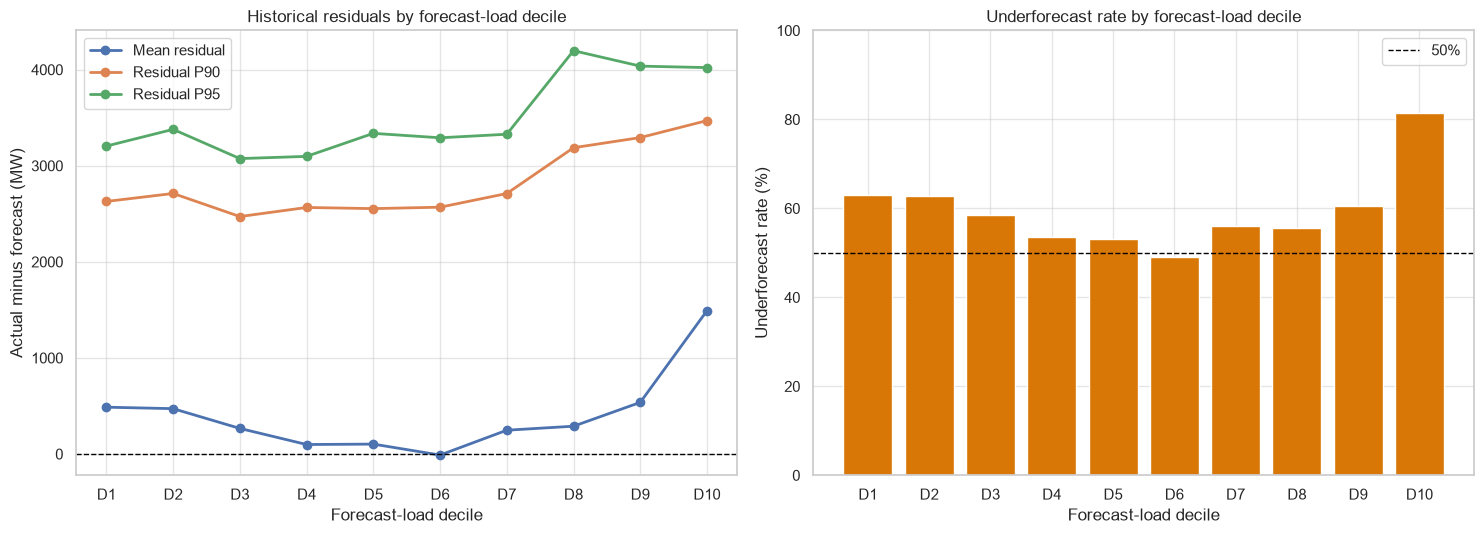

In [ ]:


# ------------------------------------------------------------
forecast_quantile_edges = np.quantile(
    historical_system["forecast_mw"],
    np.linspace(0, 1, 11),
)

forecast_quantile_edges[0] = -np.inf
forecast_quantile_edges[-1] = np.inf

decile_labels = [
    f"D{decile}"
    for decile in range(1, 11)
]

historical_system["forecast_load_decile"] = pd.cut(
    historical_system["forecast_mw"],
    bins=forecast_quantile_edges,
    labels=decile_labels,
    include_lowest=True,
    ordered=True,
)

# ------------------------------------------------------------
# ------------------------------------------------------------
residual_by_forecast_decile = (
    historical_system
    .groupby(
        "forecast_load_decile",
        observed=True,
    )
    .agg(
        hours=("residual_mw", "size"),

        forecast_min_mw=(
            "forecast_mw",
            "min",
        ),

        forecast_mean_mw=(
            "forecast_mw",
            "mean",
        ),

        forecast_max_mw=(
            "forecast_mw",
            "max",
        ),

        actual_mean_mw=(
            "actual_system_load_mw",
            "mean",
        ),

        mean_residual_mw=(
            "residual_mw",
            "mean",
        ),

        median_residual_mw=(
            "residual_mw",
            "median",
        ),

        mae_mw=(
            "absolute_error_mw",
            "mean",
        ),

        underforecast_rate_pct=(
            "is_underforecast",
            lambda values: values.mean() * 100,
        ),

        residual_p90_mw=(
            "residual_mw",
            lambda values: values.quantile(0.90),
        ),

        residual_p95_mw=(
            "residual_mw",
            lambda values: values.quantile(0.95),
        ),

        residual_p99_mw=(
            "residual_mw",
            lambda values: values.quantile(0.99),
        ),
    )
    .reset_index()
)

print("Historical system residuals by forecast-load decile:")
display(
    residual_by_forecast_decile.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
high_load_year_stability = (
    historical_system.loc[
        historical_system[
            "forecast_load_decile"
        ].eq("D10")
    ]
    .groupby("validation_year")
    .agg(
        hours=("residual_mw", "size"),

        forecast_mean_mw=(
            "forecast_mw",
            "mean",
        ),

        actual_mean_mw=(
            "actual_system_load_mw",
            "mean",
        ),

        mean_residual_mw=(
            "residual_mw",
            "mean",
        ),

        median_residual_mw=(
            "residual_mw",
            "median",
        ),

        underforecast_rate_pct=(
            "is_underforecast",
            lambda values: values.mean() * 100,
        ),

        residual_p90_mw=(
            "residual_mw",
            lambda values: values.quantile(0.90),
        ),

        residual_p95_mw=(
            "residual_mw",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

print("\nYear-to-year stability of highest forecast-load decile D10:")
display(
    high_load_year_stability.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
forecast_residual_spearman = (
    historical_system[
        [
            "forecast_mw",
            "residual_mw",
        ]
    ]
    .corr(method="spearman")
    .loc[
        "forecast_mw",
        "residual_mw",
    ]
)

print(
    "\nSpearman correlation between forecast load and residual:"
    f"{forecast_residual_spearman:.3f}"
)

# ------------------------------------------------------------
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5.5),
)

x_positions = np.arange(
    len(residual_by_forecast_decile)
)

axes[0].plot(
    x_positions,
    residual_by_forecast_decile[
        "mean_residual_mw"
    ],
    marker="o",
    linewidth=2,
    label="Mean residual",
)

axes[0].plot(
    x_positions,
    residual_by_forecast_decile[
        "residual_p90_mw"
    ],
    marker="o",
    linewidth=2,
    label="Residual P90",
)

axes[0].plot(
    x_positions,
    residual_by_forecast_decile[
        "residual_p95_mw"
    ],
    marker="o",
    linewidth=2,
    label="Residual P95",
)

axes[0].axhline(
    0,
    color="black",
    linewidth=1,
    linestyle="--",
)

axes[0].set_xticks(
    x_positions,
    residual_by_forecast_decile[
        "forecast_load_decile"
    ].astype(str),
)

axes[0].set_title(
    "Historical residuals by forecast-load decile"
)

axes[0].set_xlabel(
    "Forecast-load decile"
)

axes[0].set_ylabel(
    "Actual minus forecast (MW)"
)

axes[0].legend()

axes[1].bar(
    x_positions,
    residual_by_forecast_decile[
        "underforecast_rate_pct"
    ],
    color="#D97706",
)

axes[1].axhline(
    50,
    color="black",
    linewidth=1,
    linestyle="--",
    label="50%",
)

axes[1].set_xticks(
    x_positions,
    residual_by_forecast_decile[
        "forecast_load_decile"
    ].astype(str),
)

axes[1].set_ylim(0, 100)

axes[1].set_title(
    "Underforecast rate by forecast-load decile"
)

axes[1].set_xlabel(
    "Forecast-load decile"
)

axes[1].set_ylabel(
    "Underforecast rate (%)"
)

axes[1].legend()

plt.tight_layout()
plt.show()

## 06.07 — Upper-tail and seasonal residual diagnostics

Compare residuals in forecast P90/P95/P99 load bands, then examine D10 differences by season and year to assess whether finer conditioning has enough support.

Historical system forecast-load tail thresholds:
P90: 68,189.9 MW
P95: 73,173.3 MW
P99: 79,927.0 MW

Residuals by forecast-load tail band:


,forecast_tail_band,hours,forecast_min_mw,forecast_mean_mw,forecast_max_mw,actual_mean_mw,mean_residual_mw,median_residual_mw,underforecast_rate_pct,residual_p90_mw,residual_p95_mw,residual_p99_mw
0,Below P90,15789,32649.5,48722.6,68188.6,48999.1,276.5,342.3,56.9,2757.3,3470.0,5575.9
1,P90–P95,877,68190.4,70533.2,73169.8,71848.2,1315.0,1520.4,74.9,3676.2,4466.5,6905.2
2,P95–P99,702,73173.9,76290.7,79887.9,77968.5,1677.8,1764.7,85.8,3407.4,3865.7,4740.1
3,Top 1%,176,79956.4,81604.0,84153.9,83229.9,1626.0,1655.6,96.0,2593.7,2751.2,3241.5



D10 residuals by season:


,season,hours,forecast_mean_mw,actual_mean_mw,mean_residual_mw,median_residual_mw,underforecast_rate_pct,residual_p90_mw,residual_p95_mw
0,Winter,17,69546.3,74726.3,5180.0,6236.6,100.0,8283.1,8518.4
1,Spring,27,70245.6,71536.4,1290.7,1635.7,92.6,3495.9,3644.6
2,Summer,1443,74459.2,75893.0,1433.8,1637.6,81.3,3410.0,3916.3
3,Autumn,268,71837.5,73424.9,1587.5,1887.1,79.5,3576.3,3984.3



Year-to-year stability of seasonal D10 residuals:


,season,validation_year,hours,mean_residual_mw,median_residual_mw,underforecast_rate_pct,residual_p90_mw,residual_p95_mw
0,Autumn,2023,170,1452.5,1670.8,77.1,3658.9,3993.9
1,Autumn,2024,98,1821.6,2246.3,83.7,3512.9,3765.6
2,Spring,2024,27,1290.7,1635.7,92.6,3495.9,3644.6
3,Summer,2023,786,1104.0,1275.1,78.1,3040.1,3672.0
4,Summer,2024,657,1828.3,2199.3,85.1,3563.4,4313.4
5,Winter,2024,17,5180.0,6236.6,100.0,8283.1,8518.4


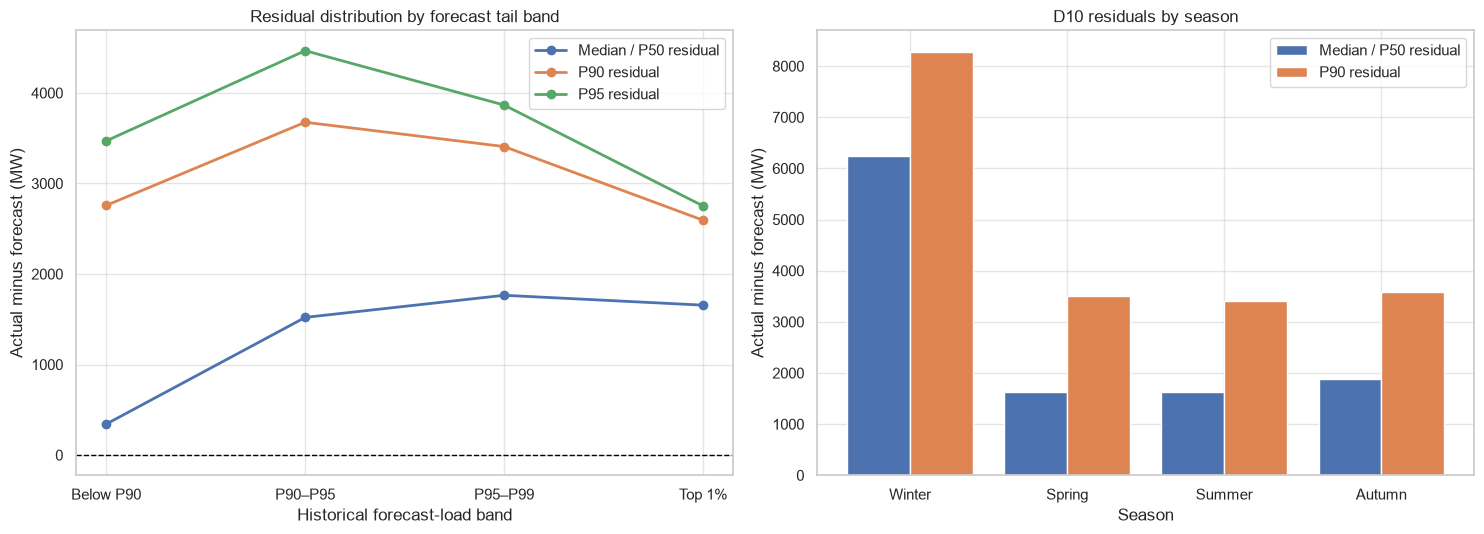

In [ ]:


# ------------------------------------------------------------
# ------------------------------------------------------------
forecast_tail_thresholds = (
    historical_system["forecast_mw"]
    .quantile(
        [
            0.90,
            0.95,
            0.99,
        ]
    )
)

forecast_p90 = float(
    forecast_tail_thresholds.loc[0.90]
)

forecast_p95 = float(
    forecast_tail_thresholds.loc[0.95]
)

forecast_p99 = float(
    forecast_tail_thresholds.loc[0.99]
)

print("Historical system forecast-load tail thresholds:")
print(f"P90: {forecast_p90:,.1f} MW")
print(f"P95: {forecast_p95:,.1f} MW")
print(f"P99: {forecast_p99:,.1f} MW")

# ------------------------------------------------------------
# ------------------------------------------------------------
tail_band_order = [
    "Below P90",
    "P90–P95",
    "P95–P99",
    "Top 1%",
]

historical_system["forecast_tail_band"] = pd.cut(
    historical_system["forecast_mw"],
    bins=[
        -np.inf,
        forecast_p90,
        forecast_p95,
        forecast_p99,
        np.inf,
    ],
    labels=tail_band_order,
    include_lowest=True,
    ordered=True,
)

# ------------------------------------------------------------
# ------------------------------------------------------------
residual_by_tail_band = (
    historical_system
    .groupby(
        "forecast_tail_band",
        observed=True,
    )
    .agg(
        hours=("residual_mw", "size"),

        forecast_min_mw=(
            "forecast_mw",
            "min",
        ),

        forecast_mean_mw=(
            "forecast_mw",
            "mean",
        ),

        forecast_max_mw=(
            "forecast_mw",
            "max",
        ),

        actual_mean_mw=(
            "actual_system_load_mw",
            "mean",
        ),

        mean_residual_mw=(
            "residual_mw",
            "mean",
        ),

        median_residual_mw=(
            "residual_mw",
            "median",
        ),

        underforecast_rate_pct=(
            "is_underforecast",
            lambda values: values.mean() * 100,
        ),

        residual_p90_mw=(
            "residual_mw",
            lambda values: values.quantile(0.90),
        ),

        residual_p95_mw=(
            "residual_mw",
            lambda values: values.quantile(0.95),
        ),

        residual_p99_mw=(
            "residual_mw",
            lambda values: values.quantile(0.99),
        ),
    )
    .reset_index()
)

print("\nResiduals by forecast-load tail band:")
display(
    residual_by_tail_band.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_d10 = historical_system.loc[
    historical_system[
        "forecast_load_decile"
    ].eq("D10")
].copy()

season_order = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn",
]

d10_by_season = (
    historical_d10
    .groupby(
        "season",
        observed=True,
    )
    .agg(
        hours=("residual_mw", "size"),

        forecast_mean_mw=(
            "forecast_mw",
            "mean",
        ),

        actual_mean_mw=(
            "actual_system_load_mw",
            "mean",
        ),

        mean_residual_mw=(
            "residual_mw",
            "mean",
        ),

        median_residual_mw=(
            "residual_mw",
            "median",
        ),

        underforecast_rate_pct=(
            "is_underforecast",
            lambda values: values.mean() * 100,
        ),

        residual_p90_mw=(
            "residual_mw",
            lambda values: values.quantile(0.90),
        ),

        residual_p95_mw=(
            "residual_mw",
            lambda values: values.quantile(0.95),
        ),
    )
    .reindex(season_order)
    .reset_index()
)

print("\nD10 residuals by season:")
display(
    d10_by_season.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
d10_season_year_stability = (
    historical_d10
    .groupby(
        [
            "season",
            "validation_year",
        ],
        observed=True,
    )
    .agg(
        hours=("residual_mw", "size"),

        mean_residual_mw=(
            "residual_mw",
            "mean",
        ),

        median_residual_mw=(
            "residual_mw",
            "median",
        ),

        underforecast_rate_pct=(
            "is_underforecast",
            lambda values: values.mean() * 100,
        ),

        residual_p90_mw=(
            "residual_mw",
            lambda values: values.quantile(0.90),
        ),

        residual_p95_mw=(
            "residual_mw",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
    .sort_values(
        [
            "season",
            "validation_year",
        ]
    )
)

print("\nYear-to-year stability of seasonal D10 residuals:")
display(
    d10_season_year_stability.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5.5),
)

tail_x = np.arange(
    len(residual_by_tail_band)
)

axes[0].plot(
    tail_x,
    residual_by_tail_band[
        "median_residual_mw"
    ],
    marker="o",
    linewidth=2,
    label="Median / P50 residual",
)

axes[0].plot(
    tail_x,
    residual_by_tail_band[
        "residual_p90_mw"
    ],
    marker="o",
    linewidth=2,
    label="P90 residual",
)

axes[0].plot(
    tail_x,
    residual_by_tail_band[
        "residual_p95_mw"
    ],
    marker="o",
    linewidth=2,
    label="P95 residual",
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
)

axes[0].set_xticks(
    tail_x,
    residual_by_tail_band[
        "forecast_tail_band"
    ].astype(str),
)

axes[0].set_title(
    "Residual distribution by forecast tail band"
)

axes[0].set_xlabel(
    "Historical forecast-load band"
)

axes[0].set_ylabel(
    "Actual minus forecast (MW)"
)

axes[0].legend()

season_x = np.arange(
    len(d10_by_season)
)

axes[1].bar(
    season_x - 0.2,
    d10_by_season[
        "median_residual_mw"
    ],
    width=0.4,
    label="Median / P50 residual",
)

axes[1].bar(
    season_x + 0.2,
    d10_by_season[
        "residual_p90_mw"
    ],
    width=0.4,
    label="P90 residual",
)

axes[1].set_xticks(
    season_x,
    d10_by_season["season"],
)

axes[1].set_title(
    "D10 residuals by season"
)

axes[1].set_xlabel("Season")
axes[1].set_ylabel(
    "Actual minus forecast (MW)"
)

axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation of the historical residual analysis.** Underestimation was most pronounced in the forecast P90–P95 and P95–P99 bands. The highest 1% of forecasts still exhibited about **1.63 GW** of median underestimation, although the upper residual quantiles were not strictly increasing across bands. Winter D10 contained only **17 hours**, all from 2024, and Spring D10 only **27 hours**. A fully granular season-by-D10 calibration would therefore be unstable. The next comparison calibrates on 2023 and evaluates on 2024, considering global, tail-band, and forecast-decile methods.

## 06.08 — Select candidate quantile calibration on 2024

Use 2023 for calibration and 2024 for temporal validation. Compare global, forecast tail-band, and forecast-decile conditional residual quantiles on coverage and peak-error metrics.

In [ ]:

# ============================================================
# ============================================================

CALIBRATION_YEAR = 2023
BACKTEST_YEAR = 2024
QUANTILE_LEVELS = [0.50, 0.90, 0.95]

calibration_2023 = historical_system.loc[
    historical_system["validation_year"].eq(
        CALIBRATION_YEAR
    )
].copy()

backtest_2024 = historical_system.loc[
    historical_system["validation_year"].eq(
        BACKTEST_YEAR
    )
].copy()

# ------------------------------------------------------------
# ------------------------------------------------------------
def make_quantile_edges(values, probabilities):
    edges = np.quantile(
        np.asarray(values, dtype=float),
        probabilities,
    ).astype(float)

    edges[0] = -np.inf
    edges[-1] = np.inf

    if np.any(np.diff(edges) <= 0):
        raise ValueError(
            "Conditional bin edges contain duplicate values."
        )

    return edges


def add_band_column(
    frame,
    edges,
    labels,
    output_column,
):
    result = frame.copy()

    result[output_column] = pd.cut(
        result["forecast_mw"],
        bins=edges,
        labels=labels,
        include_lowest=True,
        ordered=True,
    )

    return result


# ------------------------------------------------------------
# ------------------------------------------------------------
scheme_definitions = {
    "global": {
        "edges": np.array(
            [-np.inf, np.inf]
        ),
        "labels": ["All hours"],
    },

    "tail_band": {
        "edges": make_quantile_edges(
            calibration_2023["forecast_mw"],
            [0, 0.90, 0.95, 0.99, 1],
        ),
        "labels": [
            "Below P90",
            "P90–P95",
            "P95–P99",
            "Top 1%",
        ],
    },

    "forecast_decile": {
        "edges": make_quantile_edges(
            calibration_2023["forecast_mw"],
            np.linspace(0, 1, 11),
        ),
        "labels": [
            f"D{number}"
            for number in range(1, 11)
        ],
    },
}

# ------------------------------------------------------------
# ------------------------------------------------------------
calibration_lookup_records = []
backtest_prediction_frames = []

for scheme_name, definition in (
    scheme_definitions.items()
):
    band_column = "calibration_band"

    calibration_banded = add_band_column(
        calibration_2023,
        definition["edges"],
        definition["labels"],
        band_column,
    )

    backtest_banded = add_band_column(
        backtest_2024,
        definition["edges"],
        definition["labels"],
        band_column,
    )

    grouped_residuals = (
        calibration_banded
        .groupby(
            band_column,
            observed=True,
        )["residual_mw"]
    )

    band_counts = grouped_residuals.size()

    quantile_lookup = {
        level: grouped_residuals.quantile(level)
        for level in QUANTILE_LEVELS
    }

    for band_name in band_counts.index:
        calibration_lookup_records.append(
            {
                "scheme": scheme_name,
                "calibration_band": str(
                    band_name
                ),
                "calibration_hours": int(
                    band_counts.loc[band_name]
                ),
                "residual_p50_mw": float(
                    quantile_lookup[0.50]
                    .loc[band_name]
                ),
                "residual_p90_mw": float(
                    quantile_lookup[0.90]
                    .loc[band_name]
                ),
                "residual_p95_mw": float(
                    quantile_lookup[0.95]
                    .loc[band_name]
                ),
            }
        )

    prediction_frame = backtest_banded[
        [
            "timestamp_utc",
            "timestamp_local",
            "season",
            "actual_system_load_mw",
            "forecast_mw",
            band_column,
        ]
    ].copy()

    prediction_frame["scheme"] = scheme_name

    band_as_text = prediction_frame[
        band_column
    ].astype(str)

    for level in QUANTILE_LEVELS:
        level_name = f"p{int(level * 100)}"

        correction_map = {
            str(index): value
            for index, value in (
                quantile_lookup[level].items()
            )
        }

        prediction_frame[
            f"{level_name}_correction_mw"
        ] = band_as_text.map(
            correction_map
        ).astype(float)

        prediction_frame[
            f"{level_name}_forecast_mw"
        ] = (
            prediction_frame["forecast_mw"]
            + prediction_frame[
                f"{level_name}_correction_mw"
            ]
        )

    backtest_prediction_frames.append(
        prediction_frame
    )

calibration_lookup = pd.DataFrame(
    calibration_lookup_records
)

backtest_candidate_predictions = pd.concat(
    backtest_prediction_frames,
    ignore_index=True,
)

# ------------------------------------------------------------
# ------------------------------------------------------------
evaluation_thresholds = {
    "All hours": -np.inf,

    "Forecast >= 2023 P90": float(
        np.quantile(
            calibration_2023["forecast_mw"],
            0.90,
        )
    ),

    "Forecast >= 2023 P95": float(
        np.quantile(
            calibration_2023["forecast_mw"],
            0.95,
        )
    ),

    "Forecast >= 2023 P99": float(
        np.quantile(
            calibration_2023["forecast_mw"],
            0.99,
        )
    ),
}

# ------------------------------------------------------------
# ------------------------------------------------------------
coverage_records = []

for scheme_name, scheme_data in (
    backtest_candidate_predictions.groupby(
        "scheme"
    )
):
    for segment_name, threshold in (
        evaluation_thresholds.items()
    ):
        segment_data = scheme_data.loc[
            scheme_data["forecast_mw"].ge(
                threshold
            )
        ]

        for level in QUANTILE_LEVELS:
            level_name = f"p{int(level * 100)}"

            covered = (
                segment_data[
                    "actual_system_load_mw"
                ]
                <= segment_data[
                    f"{level_name}_forecast_mw"
                ]
            )

            coverage_pct = (
                covered.mean() * 100
            )

            coverage_records.append(
                {
                    "scheme": scheme_name,
                    "evaluation_segment":
                        segment_name,
                    "quantile": level_name.upper(),
                    "target_coverage_pct":
                        level * 100,
                    "hours": len(segment_data),
                    "observed_coverage_pct":
                        coverage_pct,
                    "coverage_gap_pct_point": (
                        coverage_pct
                        - level * 100
                    ),
                    "mean_correction_mw": (
                        segment_data[
                            f"{level_name}_correction_mw"
                        ].mean()
                    ),
                }
            )

coverage_backtest = pd.DataFrame(
    coverage_records
)

# ------------------------------------------------------------
# ------------------------------------------------------------
actual_2024_peak_mw = float(
    backtest_2024[
        "actual_system_load_mw"
    ].max()
)

peak_backtest_records = []

raw_peak_mw = float(
    backtest_2024["forecast_mw"].max()
)

peak_backtest_records.append(
    {
        "scheme": "raw_ridge",
        "quantile": "Raw",
        "predicted_annual_peak_mw":
            raw_peak_mw,
        "actual_annual_peak_mw":
            actual_2024_peak_mw,
        "peak_error_mw": (
            raw_peak_mw
            - actual_2024_peak_mw
        ),
        "absolute_peak_error_mw": abs(
            raw_peak_mw
            - actual_2024_peak_mw
        ),
    }
)

for scheme_name, scheme_data in (
    backtest_candidate_predictions.groupby(
        "scheme"
    )
):
    for level in QUANTILE_LEVELS:
        level_name = f"p{int(level * 100)}"

        predicted_peak_mw = float(
            scheme_data[
                f"{level_name}_forecast_mw"
            ].max()
        )

        peak_backtest_records.append(
            {
                "scheme": scheme_name,
                "quantile": level_name.upper(),
                "predicted_annual_peak_mw":
                    predicted_peak_mw,
                "actual_annual_peak_mw":
                    actual_2024_peak_mw,
                "peak_error_mw": (
                    predicted_peak_mw
                    - actual_2024_peak_mw
                ),
                "absolute_peak_error_mw": abs(
                    predicted_peak_mw
                    - actual_2024_peak_mw
                ),
            }
        )

peak_backtest = pd.DataFrame(
    peak_backtest_records
).sort_values(
    "absolute_peak_error_mw"
).reset_index(drop=True)

# ------------------------------------------------------------
# ------------------------------------------------------------
print("2023 conditional residual quantiles:")
display(
    calibration_lookup.round(1)
)

print("\n2024 empirical coverage backtest:")
display(
    coverage_backtest.round(2)
)

print("\n2024 annual-peak backtest:")
display(
    peak_backtest.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
UNCERTAINTY_OUTPUT_DIR = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "peak_uncertainty"
)

UNCERTAINTY_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

files_to_save = {
    "06_07_residual_by_tail_band.csv":
        residual_by_tail_band,

    "06_07_d10_by_season.csv":
        d10_by_season,

    "06_07_d10_season_year_stability.csv":
        d10_season_year_stability,

    "06_08_calibration_lookup_2023.csv":
        calibration_lookup,

    "06_08_coverage_backtest_2024.csv":
        coverage_backtest,

    "06_08_peak_backtest_2024.csv":
        peak_backtest,
}

saved_file_records = []

for filename, table in files_to_save.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_file_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_uncertainty_files = pd.DataFrame(
    saved_file_records
)

print("\nSaved result files:")
display(saved_uncertainty_files)

print(
    "\nThe CSV files can be uploaded directly; "
    "screenshots are not needed."
)

2023 conditional residual quantiles:


,scheme,calibration_band,calibration_hours,residual_p50_mw,residual_p90_mw,residual_p95_mw
0,global,All hours,8760,435.4,2711.5,3366.8
1,tail_band,Below P90,7884,325.8,2640.7,3271.2
2,tail_band,P90–P95,438,1024.4,3455.6,3874.2
3,tail_band,P95–P99,350,1450.0,2989.0,3627.9
4,tail_band,Top 1%,88,1338.1,2264.2,2363.0
5,forecast_decile,D1,876,454.4,2365.8,2806.0
6,forecast_decile,D2,876,500.2,2572.8,3061.9
7,forecast_decile,D3,876,592.1,2649.9,3251.3
8,forecast_decile,D4,876,255.3,2428.0,3082.2
9,forecast_decile,D5,876,-33.9,2350.5,2956.7



2024 empirical coverage backtest:


,scheme,evaluation_segment,quantile,target_coverage_pct,hours,observed_coverage_pct,coverage_gap_pct_point,mean_correction_mw
0,forecast_decile,All hours,P50,50.0,8784,46.48,-3.52,370.28
1,forecast_decile,All hours,P90,90.0,8784,86.86,-3.14,2705.53
2,forecast_decile,All hours,P95,95.0,8784,93.18,-1.82,3378.81
3,forecast_decile,Forecast >= 2023 P90,P50,50.0,687,27.22,-22.78,1328.99
4,forecast_decile,Forecast >= 2023 P90,P90,90.0,687,80.93,-9.07,3226.69
5,forecast_decile,Forecast >= 2023 P90,P95,95.0,687,91.41,-3.59,3746.04
6,forecast_decile,Forecast >= 2023 P95,P50,50.0,237,11.81,-38.19,1328.99
7,forecast_decile,Forecast >= 2023 P95,P90,90.0,237,82.28,-7.72,3226.69
8,forecast_decile,Forecast >= 2023 P95,P95,95.0,237,94.09,-0.91,3746.04
9,forecast_decile,Forecast >= 2023 P99,P50,50.0,22,0.00,-50.00,1328.99



2024 annual-peak backtest:


,scheme,quantile,predicted_annual_peak_mw,actual_annual_peak_mw,peak_error_mw,absolute_peak_error_mw
0,tail_band,P90,85429.2,85198.9,230.3,230.3
1,tail_band,P95,85527.9,85198.9,329.1,329.1
2,global,P90,85876.5,85198.9,677.6,677.6
3,tail_band,P50,84503.0,85198.9,-695.8,695.8
4,forecast_decile,P50,84493.9,85198.9,-704.9,704.9
5,forecast_decile,P90,86391.6,85198.9,1192.8,1192.8
6,global,P95,86531.7,85198.9,1332.9,1332.9
7,global,P50,83600.4,85198.9,-1598.5,1598.5
8,forecast_decile,P95,86911.0,85198.9,1712.1,1712.1
9,raw_ridge,Raw,83165.0,85198.9,-2033.9,2033.9



Saved result files:


,filename,rows,size_bytes,path
0,06_07_residual_by_tail_band.csv,4,981,/report/tables/peak_uncertainty/06_07_residual_by_tail_band.csv
1,06_07_d10_by_season.csv,4,672,/report/tables/peak_uncertainty/06_07_d10_by_season.csv
2,06_07_d10_season_year_stability.csv,6,749,/report/tables/peak_uncertainty/06_07_d10_season_year_stability.csv
3,06_08_calibration_lookup_2023.csv,15,1264,/report/tables/peak_uncertainty/06_08_calibration_lookup_2023.csv
4,06_08_coverage_backtest_2024.csv,36,3506,/report/tables/peak_uncertainty/06_08_coverage_backtest_2024.csv
5,06_08_peak_backtest_2024.csv,10,920,/report/tables/peak_uncertainty/06_08_peak_backtest_2024.csv



The CSV files can be uploaded directly; screenshots are not needed.


**2024 method selection.** Forecast-load-decile conditioning performed best in the high-load region. The global method achieved only **65.4% P90 coverage** for forecasts at or above P90. The tail-band method minimized annual peak error but yielded only **72.7% / 77.3% P90/P95 coverage** in the forecast top 1%. Decile conditioning achieved about **94.1% P95 coverage** above the predicted P95 threshold. It reduced the original annual peak underestimation of **2.03 GW** to about **0.70 GW** for the P50-adjusted peak. Because high-load P90 coverage was still imperfect, the final decile lookup was estimated using both 2023 and 2024 calibration residuals.

## 06.09 — Final annual-decile lookup; evaluate on 2025

Fit the forecast-decile residual lookup using 2023–2024 validation data only and apply its P50/P90/P95 corrections to 2025 without further tuning.

In [ ]:

# ============================================================


FINAL_QUANTILES = [0.50, 0.90, 0.95]

# ------------------------------------------------------------
# ------------------------------------------------------------
final_decile_edges = make_quantile_edges(
    historical_system["forecast_mw"],
    np.linspace(0, 1, 11),
)

final_decile_labels = [
    f"D{number}"
    for number in range(1, 11)
]

historical_final_calibration = add_band_column(
    historical_system,
    final_decile_edges,
    final_decile_labels,
    "forecast_decile",
)

# ------------------------------------------------------------
# ------------------------------------------------------------
final_grouped_residuals = (
    historical_final_calibration
    .groupby(
        "forecast_decile",
        observed=True,
    )["residual_mw"]
)

final_calibration_lookup = (
    final_grouped_residuals
    .agg(
        calibration_hours="size",

        residual_mean_mw="mean",

        residual_p50_mw=(
            lambda values:
                values.quantile(0.50)
        ),

        residual_p90_mw=(
            lambda values:
                values.quantile(0.90)
        ),

        residual_p95_mw=(
            lambda values:
                values.quantile(0.95)
        ),

        underforecast_rate_pct=(
            lambda values:
                (values > 0).mean() * 100
        ),
    )
    .reset_index()
)

decile_forecast_ranges = (
    historical_final_calibration
    .groupby(
        "forecast_decile",
        observed=True,
    )
    .agg(
        forecast_min_mw=(
            "forecast_mw",
            "min",
        ),
        forecast_mean_mw=(
            "forecast_mw",
            "mean",
        ),
        forecast_max_mw=(
            "forecast_mw",
            "max",
        ),
    )
    .reset_index()
)

final_calibration_lookup = (
    final_calibration_lookup.merge(
        decile_forecast_ranges,
        on="forecast_decile",
        how="left",
        validate="one_to_one",
    )
)

print("Final 2023–2024 conditional decile calibration table:")
display(
    final_calibration_lookup.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
system_2025_calibrated = add_band_column(
    system_2025_std,
    final_decile_edges,
    final_decile_labels,
    "forecast_decile",
)

lookup_indexed = (
    final_calibration_lookup
    .assign(
        forecast_decile=lambda frame:
            frame["forecast_decile"].astype(str)
    )
    .set_index("forecast_decile")
)

decile_text = (
    system_2025_calibrated[
        "forecast_decile"
    ].astype(str)
)

for level in FINAL_QUANTILES:
    level_name = f"p{int(level * 100)}"

    correction_column = (
        f"residual_{level_name}_mw"
    )

    system_2025_calibrated[
        f"{level_name}_correction_mw"
    ] = decile_text.map(
        lookup_indexed[
            correction_column
        ]
    ).astype(float)

    system_2025_calibrated[
        f"{level_name}_forecast_mw"
    ] = (
        system_2025_calibrated[
            "forecast_mw"
        ]
        + system_2025_calibrated[
            f"{level_name}_correction_mw"
        ]
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
quantile_order_check = pd.Series(
    {
        "missing_decile":
            int(
                system_2025_calibrated[
                    "forecast_decile"
                ].isna().sum()
            ),

        "missing_p50":
            int(
                system_2025_calibrated[
                    "p50_forecast_mw"
                ].isna().sum()
            ),

        "p50_above_p90_violations":
            int(
                (
                    system_2025_calibrated[
                        "p50_forecast_mw"
                    ]
                    > system_2025_calibrated[
                        "p90_forecast_mw"
                    ]
                ).sum()
            ),

        "p90_above_p95_violations":
            int(
                (
                    system_2025_calibrated[
                        "p90_forecast_mw"
                    ]
                    > system_2025_calibrated[
                        "p95_forecast_mw"
                    ]
                ).sum()
            ),
    },
    name="value",
)

print("\n2025 quantile forecast integrity checks:")
print(
    quantile_order_check.to_string()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_p90_threshold = float(
    historical_system[
        "forecast_mw"
    ].quantile(0.90)
)

historical_p95_threshold = float(
    historical_system[
        "forecast_mw"
    ].quantile(0.95)
)

historical_p99_threshold = float(
    historical_system[
        "forecast_mw"
    ].quantile(0.99)
)

test_segments = {
    "All hours": -np.inf,
    "Forecast >= historical P90":
        historical_p90_threshold,
    "Forecast >= historical P95":
        historical_p95_threshold,
    "Forecast >= historical P99":
        historical_p99_threshold,
}

coverage_2025_records = []

for segment_name, threshold in (
    test_segments.items()
):
    segment = system_2025_calibrated.loc[
        system_2025_calibrated[
            "forecast_mw"
        ].ge(threshold)
    ]

    for level in FINAL_QUANTILES:
        level_name = f"p{int(level * 100)}"

        covered = (
            segment["actual_mw"]
            <= segment[
                f"{level_name}_forecast_mw"
            ]
        )

        observed_coverage = (
            covered.mean() * 100
        )

        coverage_2025_records.append(
            {
                "evaluation_segment":
                    segment_name,
                "quantile":
                    level_name.upper(),
                "target_coverage_pct":
                    level * 100,
                "hours": len(segment),
                "observed_coverage_pct":
                    observed_coverage,
                "coverage_gap_pct_point": (
                    observed_coverage
                    - level * 100
                ),
                "mean_correction_mw":
                    segment[
                        f"{level_name}_correction_mw"
                    ].mean(),
            }
        )

coverage_2025 = pd.DataFrame(
    coverage_2025_records
)

print("\n2025 held-out empirical coverage:")
display(
    coverage_2025.round(2)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
actual_2025_peak_mw = float(
    system_2025_calibrated[
        "actual_mw"
    ].max()
)

peak_2025_records = [
    {
        "forecast_type": "Raw Ridge",
        "predicted_peak_mw": float(
            system_2025_calibrated[
                "forecast_mw"
            ].max()
        ),
    },
    {
        "forecast_type": "Calibrated P50",
        "predicted_peak_mw": float(
            system_2025_calibrated[
                "p50_forecast_mw"
            ].max()
        ),
    },
    {
        "forecast_type": "Calibrated P90",
        "predicted_peak_mw": float(
            system_2025_calibrated[
                "p90_forecast_mw"
            ].max()
        ),
    },
    {
        "forecast_type": "Calibrated P95",
        "predicted_peak_mw": float(
            system_2025_calibrated[
                "p95_forecast_mw"
            ].max()
        ),
    },
]

peak_2025 = pd.DataFrame(
    peak_2025_records
)

peak_2025["actual_peak_mw"] = (
    actual_2025_peak_mw
)

peak_2025["peak_error_mw"] = (
    peak_2025["predicted_peak_mw"]
    - peak_2025["actual_peak_mw"]
)

peak_2025["absolute_peak_error_mw"] = (
    peak_2025["peak_error_mw"].abs()
)

print("\n2025 annual-peak backtest:")
display(
    peak_2025.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_09 = {
    "06_09_final_decile_calibration.csv":
        final_calibration_lookup,

    "06_09_2025_hourly_calibrated_forecasts.csv":
        system_2025_calibrated,

    "06_09_2025_coverage_backtest.csv":
        coverage_2025,

    "06_09_2025_annual_peak_backtest.csv":
        peak_2025,
}

saved_06_09_records = []

for filename, table in outputs_06_09.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_09_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_09 = pd.DataFrame(
    saved_06_09_records
)

print("\nFiles written in 06.09:")
display(saved_06_09)

Final 2023–2024 conditional decile calibration table:


,forecast_decile,calibration_hours,residual_mean_mw,residual_p50_mw,residual_p90_mw,residual_p95_mw,underforecast_rate_pct,forecast_min_mw,forecast_mean_mw,forecast_max_mw
0,D1,1755,487.1,535.6,2628.5,3204.8,62.9,32649.5,37789.4,39975.2
1,D2,1754,471.8,583.3,2711.4,3378.6,62.8,39975.3,41311.3,42417.6
2,D3,1754,266.1,401.4,2471.2,3074.5,58.5,42418.8,43402.0,44356.1
3,D4,1755,98.6,164.2,2565.7,3097.5,53.7,44356.4,45290.3,46247.8
4,D5,1754,102.8,164.5,2553.9,3337.1,53.0,46248.0,47232.3,48291.6
5,D6,1754,-11.1,-38.2,2568.6,3291.0,49.1,48294.5,49551.9,50949.1
6,D7,1755,247.4,339.4,2710.8,3327.9,56.0,50949.3,52630.7,54532.1
7,D8,1754,289.0,312.7,3187.5,4197.5,55.6,54532.5,57177.9,60377.9
8,D9,1754,536.9,613.2,3293.1,4037.0,60.5,60379.4,64123.8,68188.6
9,D10,1755,1491.3,1661.7,3469.9,4021.5,81.4,68190.4,73946.5,84153.9



2025 quantile forecast integrity checks:
missing_decile              0
missing_p50                 0
p50_above_p90_violations    0
p90_above_p95_violations    0

2025 held-out empirical coverage:


,evaluation_segment,quantile,target_coverage_pct,hours,observed_coverage_pct,coverage_gap_pct_point,mean_correction_mw
0,All hours,P50,50.0,8760,46.77,-3.23,484.66
1,All hours,P90,90.0,8760,87.56,-2.44,2914.73
2,All hours,P95,95.0,8760,93.16,-1.84,3630.65
3,Forecast >= historical P90,P50,50.0,1153,47.01,-2.99,1661.73
4,Forecast >= historical P90,P90,90.0,1153,87.60,-2.40,3469.87
5,Forecast >= historical P90,P95,95.0,1153,93.58,-1.42,4021.46
6,Forecast >= historical P95,P50,50.0,468,42.09,-7.91,1661.73
7,Forecast >= historical P95,P90,90.0,468,90.60,0.60,3469.87
8,Forecast >= historical P95,P95,95.0,468,96.58,1.58,4021.46
9,Forecast >= historical P99,P50,50.0,35,65.71,15.71,1661.73



2025 annual-peak backtest:


,forecast_type,predicted_peak_mw,actual_peak_mw,peak_error_mw,absolute_peak_error_mw
0,Raw Ridge,82561.5,83679.0,-1117.5,1117.5
1,Calibrated P50,84223.3,83679.0,544.3,544.3
2,Calibrated P90,86031.4,83679.0,2352.4,2352.4
3,Calibrated P95,86583.0,83679.0,2904.0,2904.0



Files written in 06.09:


,filename,rows,size_bytes,path
0,06_09_final_decile_calibration.csv,10,1718,/report/tables/peak_uncertainty/06_09_final_decile_calibration.csv
1,06_09_2025_hourly_calibrated_forecasts.csv,8760,2450657,/report/tables/peak_uncertainty/06_09_2025_hourly_calibrated_forecasts.csv
2,06_09_2025_coverage_backtest.csv,12,1162,/report/tables/peak_uncertainty/06_09_2025_coverage_backtest.csv
3,06_09_2025_annual_peak_backtest.csv,4,432,/report/tables/peak_uncertainty/06_09_2025_annual_peak_backtest.csv


**2025 independent evaluation of annual-decile calibration.** The raw annual peak was **1,117 MW too low**, while the calibrated P50 annual peak was **544 MW too high**, reducing absolute peak error by approximately **51%**. For forecast load at or above the historical P95 threshold, P90/P95 hourly coverage was **90.60% / 96.58%**; all **35** hours at or above the historical P99 threshold were covered by both bounds. Overall annual hourly coverage was roughly two percentage points below nominal. The 2025 outcomes were not used to retune the lookup; the next section generates annual, monthly, and seasonal planning tables.

## 06.10 — Annual, monthly, and seasonal peak summaries

Extract maxima from original and hourly calibrated forecasts, and compare their values with the observed 2025 peak at each planning horizon.

2025 annual system peak planning table:


/var/folders/7v/ptggmzp56xv2zs9hx5nwyrx00000gn/T/ipykernel_96906/2639040014.py:218: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  pd.Categorical(
/var/folders/7v/ptggmzp56xv2zs9hx5nwyrx00000gn/T/ipykernel_96906/2639040014.py:256: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(1)


,period,actual_peak_local,actual_peak_mw,raw_peak_mw,raw_peak_error_mw,p50_peak_mw,p50_peak_error_mw,p90_planning_peak_mw,p90_margin_above_actual_mw,p95_planning_peak_mw,p95_margin_above_actual_mw
0,2025 Annual,2025-08-18 18:00:00-05:00,83679.0,82561.5,-1117.5,84223.3,544.3,86031.4,2352.4,86583.0,2904.0



2025 monthly system peak planning table:


,local_month,actual_peak_mw,raw_peak_mw,raw_peak_error_mw,p50_peak_mw,p50_peak_error_mw,p90_planning_peak_mw,p90_margin_above_actual_mw,p95_planning_peak_mw,p95_margin_above_actual_mw
0,1,77478.3,70638.2,-6840.0,72300.0,-5178.3,74108.1,-3370.2,74659.7,-2818.6
1,2,80524.7,70989.8,-9534.9,72651.5,-7873.2,74459.7,-6065.0,75011.2,-5513.5
2,3,62920.4,62464.3,-456.1,63077.4,157.0,65757.4,2837.0,66501.3,3580.9
3,4,65613.5,63512.3,-2101.2,64125.5,-1488.0,66805.4,1191.9,67549.3,1935.8
4,5,78391.8,74849.4,-3542.5,76511.1,-1880.7,78319.2,-72.6,78870.8,479.0
5,6,77351.0,75691.9,-1659.1,77353.7,2.7,79161.8,1810.8,79713.4,2362.4
6,7,81706.5,81168.2,-538.3,82829.9,1123.4,84638.1,2931.5,85189.7,3483.1
7,8,83679.0,82561.5,-1117.5,84223.3,544.3,86031.4,2352.4,86583.0,2904.0
8,9,79917.5,78858.0,-1059.5,80519.7,602.2,82327.9,2410.4,82879.5,2961.9
9,10,75889.2,73996.4,-1892.7,75658.2,-231.0,77466.3,1577.2,78017.9,2128.7



2025 seasonal system peak planning table:


,season,actual_peak_mw,raw_peak_mw,raw_peak_error_mw,p50_peak_mw,p50_peak_error_mw,p90_planning_peak_mw,p90_margin_above_actual_mw,p95_planning_peak_mw,p95_margin_above_actual_mw
0,Winter,80524.7,70989.8,-9534.9,72651.5,-7873.2,74459.7,-6065.0,75011.2,-5513.5
1,Spring,78391.8,74849.4,-3542.5,76511.1,-1880.7,78319.2,-72.6,78870.8,479.0
2,Summer,83679.0,82561.5,-1117.5,84223.3,544.3,86031.4,2352.4,86583.0,2904.0
3,NaN,79917.5,78858.0,-1059.5,80519.7,602.2,82327.9,2410.4,82879.5,2961.9


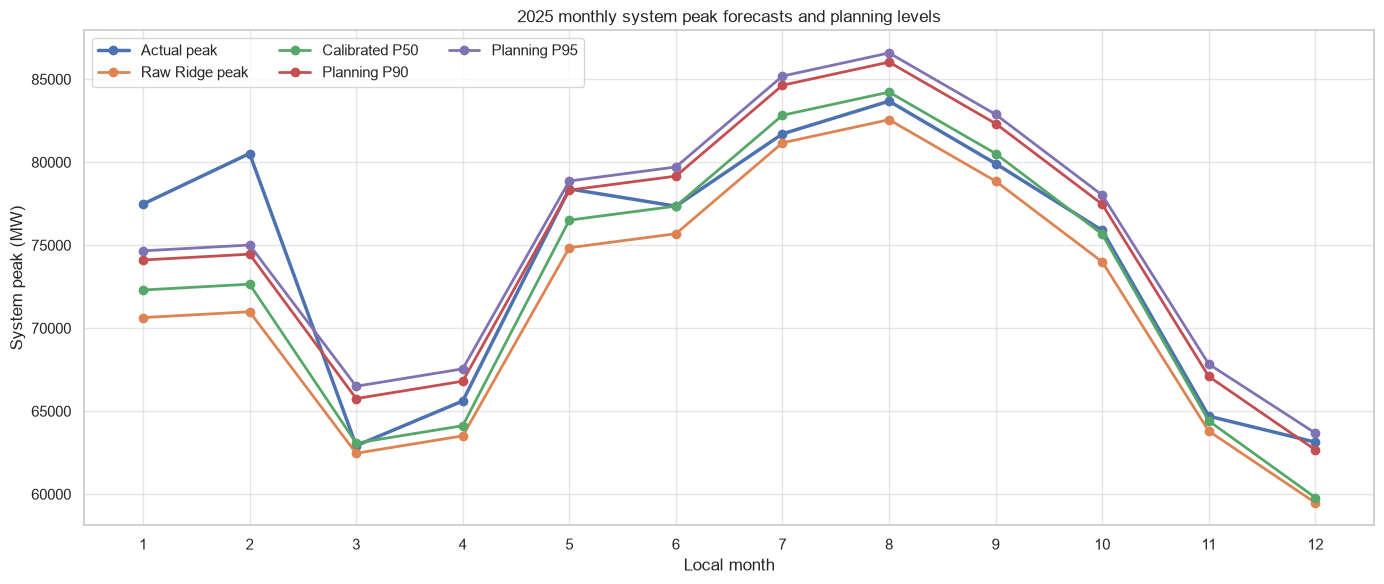


Files written in 06.10:


,filename,rows,size_bytes,path
0,06_10_2025_annual_system_peaks.csv,1,629,/report/tables/peak_uncertainty/06_10_2025_annual_system_peaks.csv
1,06_10_2025_monthly_system_peaks.csv,12,4284,/report/tables/peak_uncertainty/06_10_2025_monthly_system_peaks.csv
2,06_10_2025_seasonal_system_peaks.csv,4,1636,/report/tables/peak_uncertainty/06_10_2025_seasonal_system_peaks.csv


In [ ]:

# ============================================================
# ============================================================

# ------------------------------------------------------------
# ------------------------------------------------------------
def summarize_period_peaks(
    frame,
    group_columns,
    summary_name,
):
    records = []

    if group_columns:
        grouped = frame.groupby(
            group_columns,
            observed=True,
            sort=False,
        )
    else:
        grouped = [
            ("2025 Annual", frame)
        ]

    for group_key, group in grouped:
        if not isinstance(group_key, tuple):
            group_key = (group_key,)

        group_info = (
            dict(zip(group_columns, group_key))
            if group_columns
            else {"period": "2025 Annual"}
        )

        actual_peak_row = group.loc[
            group["actual_mw"].idxmax()
        ]

        raw_peak_row = group.loc[
            group["forecast_mw"].idxmax()
        ]

        p50_peak_row = group.loc[
            group["p50_forecast_mw"].idxmax()
        ]

        p90_peak_row = group.loc[
            group["p90_forecast_mw"].idxmax()
        ]

        p95_peak_row = group.loc[
            group["p95_forecast_mw"].idxmax()
        ]

        actual_peak_mw = float(
            actual_peak_row["actual_mw"]
        )

        records.append(
            {
                **group_info,
                "summary_level": summary_name,

                "hours": len(group),

                "actual_peak_mw":
                    actual_peak_mw,

                "actual_peak_utc":
                    actual_peak_row[
                        "timestamp_utc"
                    ],

                "actual_peak_local":
                    actual_peak_row[
                        "timestamp_local"
                    ],

                "raw_peak_mw":
                    float(
                        raw_peak_row[
                            "forecast_mw"
                        ]
                    ),

                "raw_peak_error_mw": (
                    float(
                        raw_peak_row[
                            "forecast_mw"
                        ]
                    )
                    - actual_peak_mw
                ),

                "raw_peak_utc":
                    raw_peak_row[
                        "timestamp_utc"
                    ],

                "p50_peak_mw":
                    float(
                        p50_peak_row[
                            "p50_forecast_mw"
                        ]
                    ),

                "p50_peak_error_mw": (
                    float(
                        p50_peak_row[
                            "p50_forecast_mw"
                        ]
                    )
                    - actual_peak_mw
                ),

                "p50_peak_utc":
                    p50_peak_row[
                        "timestamp_utc"
                    ],

                "p90_planning_peak_mw":
                    float(
                        p90_peak_row[
                            "p90_forecast_mw"
                        ]
                    ),

                "p90_margin_above_actual_mw": (
                    float(
                        p90_peak_row[
                            "p90_forecast_mw"
                        ]
                    )
                    - actual_peak_mw
                ),

                "p90_peak_utc":
                    p90_peak_row[
                        "timestamp_utc"
                    ],

                "p95_planning_peak_mw":
                    float(
                        p95_peak_row[
                            "p95_forecast_mw"
                        ]
                    ),

                "p95_margin_above_actual_mw": (
                    float(
                        p95_peak_row[
                            "p95_forecast_mw"
                        ]
                    )
                    - actual_peak_mw
                ),

                "p95_peak_utc":
                    p95_peak_row[
                        "timestamp_utc"
                    ],
            }
        )

    return pd.DataFrame(records)


# ------------------------------------------------------------
# ------------------------------------------------------------
annual_system_peaks_2025 = (
    summarize_period_peaks(
        system_2025_calibrated,
        group_columns=[],
        summary_name="Annual",
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
monthly_system_peaks_2025 = (
    summarize_period_peaks(
        system_2025_calibrated,
        group_columns=[
            "local_month",
        ],
        summary_name="Monthly",
    )
    .sort_values("local_month")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
season_order = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn",
]

seasonal_system_peaks_2025 = (
    summarize_period_peaks(
        system_2025_calibrated,
        group_columns=[
            "season",
        ],
        summary_name="Seasonal",
    )
)

seasonal_system_peaks_2025["season"] = (
    pd.Categorical(
        seasonal_system_peaks_2025[
            "season"
        ],
        categories=season_order,
        ordered=True,
    )
)

seasonal_system_peaks_2025 = (
    seasonal_system_peaks_2025
    .sort_values("season")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
planning_columns = [
    "actual_peak_mw",
    "raw_peak_mw",
    "raw_peak_error_mw",
    "p50_peak_mw",
    "p50_peak_error_mw",
    "p90_planning_peak_mw",
    "p90_margin_above_actual_mw",
    "p95_planning_peak_mw",
    "p95_margin_above_actual_mw",
]

print("2025 annual system peak planning table:")
display(
    annual_system_peaks_2025[
        [
            "period",
            "actual_peak_local",
            *planning_columns,
        ]
    ].round(1)
)

print("\n2025 monthly system peak planning table:")
display(
    monthly_system_peaks_2025[
        [
            "local_month",
            *planning_columns,
        ]
    ].round(1)
)

print("\n2025 seasonal system peak planning table:")
display(
    seasonal_system_peaks_2025[
        [
            "season",
            *planning_columns,
        ]
    ].round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(14, 6),
)

months = (
    monthly_system_peaks_2025[
        "local_month"
    ].to_numpy()
)

ax.plot(
    months,
    monthly_system_peaks_2025[
        "actual_peak_mw"
    ],
    marker="o",
    linewidth=2.5,
    label="Actual peak",
)

ax.plot(
    months,
    monthly_system_peaks_2025[
        "raw_peak_mw"
    ],
    marker="o",
    linewidth=2,
    label="Raw Ridge peak",
)

ax.plot(
    months,
    monthly_system_peaks_2025[
        "p50_peak_mw"
    ],
    marker="o",
    linewidth=2,
    label="Calibrated P50",
)

ax.plot(
    months,
    monthly_system_peaks_2025[
        "p90_planning_peak_mw"
    ],
    marker="o",
    linewidth=2,
    label="Planning P90",
)

ax.plot(
    months,
    monthly_system_peaks_2025[
        "p95_planning_peak_mw"
    ],
    marker="o",
    linewidth=2,
    label="Planning P95",
)

ax.set_xticks(
    range(1, 13)
)

ax.set_xlabel("Local month")
ax.set_ylabel("System peak (MW)")
ax.set_title(
    "2025 monthly system peak forecasts and planning levels"
)
ax.legend(ncol=3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_10 = {
    "06_10_2025_annual_system_peaks.csv":
        annual_system_peaks_2025,

    "06_10_2025_monthly_system_peaks.csv":
        monthly_system_peaks_2025,

    "06_10_2025_seasonal_system_peaks.csv":
        seasonal_system_peaks_2025,
}

saved_06_10_records = []

for filename, table in outputs_06_10.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_10_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_10 = pd.DataFrame(
    saved_06_10_records
)

print("\nFiles written in 06.10:")
display(saved_06_10)

## 06.10a — Standardize season labels

Normalize the season label to `Autumn`, regenerate the saved seasonal peak table, and verify its contents.

In [ ]:
# ============================================================
# ============================================================

system_2025_calibrated["season"] = (
    system_2025_calibrated["season"]
    .astype(str)
    .replace(
        {
            "Fall": "Autumn",
            "fall": "Autumn",
            "autumn": "Autumn",
        }
    )
)

season_order = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn",
]

print(
    "Normalized season labels:",
    sorted(
        system_2025_calibrated[
            "season"
        ].dropna().unique()
    ),
)

seasonal_system_peaks_2025 = (
    summarize_period_peaks(
        system_2025_calibrated,
        group_columns=["season"],
        summary_name="Seasonal",
    )
)

season_sort_order = {
    season: position
    for position, season in enumerate(
        season_order
    )
}

seasonal_system_peaks_2025[
    "_season_order"
] = (
    seasonal_system_peaks_2025[
        "season"
    ].map(season_sort_order)
)

seasonal_system_peaks_2025 = (
    seasonal_system_peaks_2025
    .sort_values("_season_order")
    .drop(columns="_season_order")
    .reset_index(drop=True)
)

seasonal_display = (
    seasonal_system_peaks_2025[
        [
            "season",
            "actual_peak_mw",
            "raw_peak_mw",
            "raw_peak_error_mw",
            "p50_peak_mw",
            "p50_peak_error_mw",
            "p90_planning_peak_mw",
            "p90_margin_above_actual_mw",
            "p95_planning_peak_mw",
            "p95_margin_above_actual_mw",
        ]
    ]
    .copy()
)

numeric_columns = (
    seasonal_display
    .select_dtypes(include="number")
    .columns
)

seasonal_display[numeric_columns] = (
    seasonal_display[
        numeric_columns
    ].round(1)
)

print("\nCorrected 2025 seasonal system peak planning table:")
display(seasonal_display)

SEASONAL_OUTPUT_PATH = (
    UNCERTAINTY_OUTPUT_DIR
    / "06_10_2025_seasonal_system_peaks.csv"
)

seasonal_system_peaks_2025.to_csv(
    SEASONAL_OUTPUT_PATH,
    index=False,
)

seasonal_saved_check = pd.read_csv(
    SEASONAL_OUTPUT_PATH
)

print("\nSaved-file verification:")
print("Path:", SEASONAL_OUTPUT_PATH)
print("Rows:", len(seasonal_saved_check))
print(
    "Seasons:",
    seasonal_saved_check[
        "season"
    ].tolist(),
)

if (
    len(seasonal_saved_check) != 4
    or seasonal_saved_check[
        "season"
    ].isna().any()
):
    raise RuntimeError(
        "Seasonal-peak table verification failed."
    )

print(
    "\nSeasonal peak table was corrected "
    "and saved successfully."
)

Normalized season labels: ['Autumn', 'Spring', 'Summer', 'Winter']

Corrected 2025 seasonal system peak planning table:


,season,actual_peak_mw,raw_peak_mw,raw_peak_error_mw,p50_peak_mw,p50_peak_error_mw,p90_planning_peak_mw,p90_margin_above_actual_mw,p95_planning_peak_mw,p95_margin_above_actual_mw
0,Winter,80524.7,70989.8,-9534.9,72651.5,-7873.2,74459.7,-6065.0,75011.2,-5513.5
1,Spring,78391.8,74849.4,-3542.5,76511.1,-1880.7,78319.2,-72.6,78870.8,479.0
2,Summer,83679.0,82561.5,-1117.5,84223.3,544.3,86031.4,2352.4,86583.0,2904.0
3,Autumn,79917.5,78858.0,-1059.5,80519.7,602.2,82327.9,2410.4,82879.5,2961.9



Saved-file verification:
Path: <PROJECT_ROOT>/report/tables/peak_uncertainty/06_10_2025_seasonal_system_peaks.csv
Rows: 4
Seasons: ['Winter', 'Spring', 'Summer', 'Autumn']

Seasonal peak table was corrected and saved successfully.


**Seasonal limitation of annual deciles.** The Summer and Autumn P50 peak errors were **+544 MW** and **+602 MW**, and the Spring P90 peak error was **−73 MW**. In Winter, even the P95-adjusted peak remained **5.51 GW too low**; the raw January and February peak errors were approximately **6.84 GW** and **9.53 GW**. Winter forecast values seldom reach the annual D10 threshold, so an annual-decile lookup can undercorrect a severe winter event. This motivates season-specific forecast deciles.

## 06.11 — Season-specific forecast-decile backtest

Build deciles separately within each season; calibrate on 2023 and evaluate 2024 seasonal coverage and peak errors.

In [ ]:
#assign_seasonal_deciles()

# ============================================================
# ============================================================

SEASON_ORDER = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn",
]

SEASONAL_DECILE_LABELS = [
    f"D{number}"
    for number in range(1, 11)
]

# ------------------------------------------------------------
# ------------------------------------------------------------
def build_seasonal_decile_edges(
    calibration_frame,
):
    edge_lookup = {}

    for season_name in SEASON_ORDER:
        season_values = calibration_frame.loc[
            calibration_frame["season"].eq(
                season_name
            ),
            "forecast_mw",
        ]

        if len(season_values) == 0:
            raise ValueError(
                f"{season_name} has no calibration samples."
            )

        edge_lookup[season_name] = (
            make_quantile_edges(
                season_values,
                np.linspace(0, 1, 11),
            )
        )

    return edge_lookup


# ------------------------------------------------------------
# ------------------------------------------------------------
def assign_seasonal_deciles(
    frame,
    edge_lookup,
):
    result = frame.copy()

    result[
        "seasonal_forecast_decile"
    ] = None

    for season_name in SEASON_ORDER:
        season_mask = result["season"].eq(
            season_name
        )

        season_bands = pd.cut(
            result.loc[
                season_mask,
                "forecast_mw",
            ],
            bins=edge_lookup[season_name],
            labels=SEASONAL_DECILE_LABELS,
            include_lowest=True,
            ordered=True,
        )

        result.loc[
            season_mask,
            "seasonal_forecast_decile",
        ] = season_bands.astype(str).values

    if result[
        "seasonal_forecast_decile"
    ].isna().any():
        raise ValueError(
            "Some records could not be assigned a within-season decile."
        )

    return result


# ------------------------------------------------------------
# ------------------------------------------------------------
seasonal_edges_2023 = (
    build_seasonal_decile_edges(
        calibration_2023
    )
)

calibration_2023_seasonal = (
    assign_seasonal_deciles(
        calibration_2023,
        seasonal_edges_2023,
    )
)

backtest_2024_seasonal = (
    assign_seasonal_deciles(
        backtest_2024,
        seasonal_edges_2023,
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
seasonal_decile_calibration_2023 = (
    calibration_2023_seasonal
    .groupby(
        [
            "season",
            "seasonal_forecast_decile",
        ],
        observed=True,
    )
    .agg(
        calibration_hours=(
            "residual_mw",
            "size",
        ),

        forecast_min_mw=(
            "forecast_mw",
            "min",
        ),

        forecast_max_mw=(
            "forecast_mw",
            "max",
        ),

        residual_p50_mw=(
            "residual_mw",
            lambda values:
                values.quantile(0.50),
        ),

        residual_p90_mw=(
            "residual_mw",
            lambda values:
                values.quantile(0.90),
        ),

        residual_p95_mw=(
            "residual_mw",
            lambda values:
                values.quantile(0.95),
        ),

        underforecast_rate_pct=(
            "residual_mw",
            lambda values:
                (values > 0).mean() * 100,
        ),
    )
    .reset_index()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
lookup_2023_seasonal = (
    seasonal_decile_calibration_2023
    .set_index(
        [
            "season",
            "seasonal_forecast_decile",
        ]
    )
)

backtest_keys = pd.MultiIndex.from_frame(
    backtest_2024_seasonal[
        [
            "season",
            "seasonal_forecast_decile",
        ]
    ]
)

for level in [50, 90, 95]:
    correction_values = (
        lookup_2023_seasonal[
            f"residual_p{level}_mw"
        ]
        .reindex(backtest_keys)
        .to_numpy()
    )

    backtest_2024_seasonal[
        f"p{level}_correction_mw"
    ] = correction_values

    backtest_2024_seasonal[
        f"p{level}_forecast_mw"
    ] = (
        backtest_2024_seasonal[
            "forecast_mw"
        ]
        + correction_values
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
seasonal_backtest_quality = pd.Series(
    {
        "rows":
            len(backtest_2024_seasonal),

        "missing_p50":
            int(
                backtest_2024_seasonal[
                    "p50_forecast_mw"
                ].isna().sum()
            ),

        "missing_p90":
            int(
                backtest_2024_seasonal[
                    "p90_forecast_mw"
                ].isna().sum()
            ),

        "missing_p95":
            int(
                backtest_2024_seasonal[
                    "p95_forecast_mw"
                ].isna().sum()
            ),

        "p50_above_p90":
            int(
                (
                    backtest_2024_seasonal[
                        "p50_forecast_mw"
                    ]
                    > backtest_2024_seasonal[
                        "p90_forecast_mw"
                    ]
                ).sum()
            ),

        "p90_above_p95":
            int(
                (
                    backtest_2024_seasonal[
                        "p90_forecast_mw"
                    ]
                    > backtest_2024_seasonal[
                        "p95_forecast_mw"
                    ]
                ).sum()
            ),
    },
    name="value",
)

print("Within-season decile backtest integrity checks:")
print(
    seasonal_backtest_quality.to_string()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
seasonal_coverage_records = []

for season_name in SEASON_ORDER:
    season_data = backtest_2024_seasonal.loc[
        backtest_2024_seasonal[
            "season"
        ].eq(season_name)
    ]

    for segment_name, segment_mask in {
        "All seasonal hours":
            pd.Series(
                True,
                index=season_data.index,
            ),

        "Seasonal D10":
            season_data[
                "seasonal_forecast_decile"
            ].eq("D10"),
    }.items():
        segment = season_data.loc[
            segment_mask
        ]

        for level in [50, 90, 95]:
            coverage = (
                segment[
                    "actual_system_load_mw"
                ]
                <= segment[
                    f"p{level}_forecast_mw"
                ]
            ).mean() * 100

            seasonal_coverage_records.append(
                {
                    "season": season_name,
                    "segment": segment_name,
                    "quantile": f"P{level}",
                    "target_coverage_pct":
                        float(level),
                    "hours": len(segment),
                    "observed_coverage_pct":
                        coverage,
                    "coverage_gap_pct_point": (
                        coverage - level
                    ),
                }
            )

seasonal_decile_coverage_2024 = (
    pd.DataFrame(
        seasonal_coverage_records
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
seasonal_peak_backtest_records = []

for season_name in SEASON_ORDER:
    season_data = backtest_2024_seasonal.loc[
        backtest_2024_seasonal[
            "season"
        ].eq(season_name)
    ]

    actual_peak = float(
        season_data[
            "actual_system_load_mw"
        ].max()
    )

    forecast_columns = {
        "Raw Ridge": "forecast_mw",
        "Seasonal-decile P50":
            "p50_forecast_mw",
        "Seasonal-decile P90":
            "p90_forecast_mw",
        "Seasonal-decile P95":
            "p95_forecast_mw",
    }

    for forecast_type, column_name in (
        forecast_columns.items()
    ):
        predicted_peak = float(
            season_data[
                column_name
            ].max()
        )

        seasonal_peak_backtest_records.append(
            {
                "season": season_name,
                "forecast_type":
                    forecast_type,
                "predicted_peak_mw":
                    predicted_peak,
                "actual_peak_mw":
                    actual_peak,
                "peak_error_mw": (
                    predicted_peak
                    - actual_peak
                ),
                "absolute_peak_error_mw": abs(
                    predicted_peak
                    - actual_peak
                ),
            }
        )

seasonal_decile_peak_backtest_2024 = (
    pd.DataFrame(
        seasonal_peak_backtest_records
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
print("\n2023 seasonal D10 calibration parameters:")
display(
    seasonal_decile_calibration_2023.loc[
        seasonal_decile_calibration_2023[
            "seasonal_forecast_decile"
        ].eq("D10")
    ].round(1)
)

print("\n2024 seasonal empirical coverage backtest:")
display(
    seasonal_decile_coverage_2024.round(2)
)

print("\n2024 seasonal-peak backtest:")
display(
    seasonal_decile_peak_backtest_2024.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_11 = {
    "06_11_seasonal_decile_calibration_2023.csv":
        seasonal_decile_calibration_2023,

    "06_11_seasonal_decile_coverage_2024.csv":
        seasonal_decile_coverage_2024,

    "06_11_seasonal_peak_backtest_2024.csv":
        seasonal_decile_peak_backtest_2024,
}

saved_06_11_records = []

for filename, table in outputs_06_11.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_11_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_11 = pd.DataFrame(
    saved_06_11_records
)

print("\nFiles written in 06.11:")
display(saved_06_11)

Within-season decile backtest integrity checks:
rows             8784
missing_p50         0
missing_p90         0
missing_p95         0
p50_above_p90       0
p90_above_p95       0

2023 seasonal D10 calibration parameters:


,season,seasonal_forecast_decile,calibration_hours,forecast_min_mw,forecast_max_mw,residual_p50_mw,residual_p90_mw,residual_p95_mw,underforecast_rate_pct
1,Autumn,D10,219,65821.6,82569.4,1508.0,3475.6,3991.9,74.0
11,Spring,D10,221,54098.0,63606.8,538.9,3886.1,5134.1,61.5
21,Summer,D10,221,78018.4,84153.9,1412.2,2307.4,2688.7,92.8
31,Winter,D10,216,49577.0,61260.5,617.6,6814.6,8036.1,56.9



2024 seasonal empirical coverage backtest:


,season,segment,quantile,target_coverage_pct,hours,observed_coverage_pct,coverage_gap_pct_point
0,Winter,All seasonal hours,P50,50.0,2184,46.34,-3.66
1,Winter,All seasonal hours,P90,90.0,2184,89.70,-0.30
2,Winter,All seasonal hours,P95,95.0,2184,94.73,-0.27
3,Winter,Seasonal D10,P50,50.0,538,54.83,4.83
4,Winter,Seasonal D10,P90,90.0,538,87.17,-2.83
5,Winter,Seasonal D10,P95,95.0,538,90.52,-4.48
6,Spring,All seasonal hours,P50,50.0,2207,48.71,-1.29
7,Spring,All seasonal hours,P90,90.0,2207,90.71,0.71
8,Spring,All seasonal hours,P95,95.0,2207,96.10,1.10
9,Spring,Seasonal D10,P50,50.0,411,47.45,-2.55



2024 seasonal-peak backtest:


,season,forecast_type,predicted_peak_mw,actual_peak_mw,peak_error_mw,absolute_peak_error_mw
0,Winter,Raw Ridge,71089.4,78313.7,-7224.3,7224.3
1,Winter,Seasonal-decile P50,71707.1,78313.7,-6606.7,6606.7
2,Winter,Seasonal-decile P90,77904.0,78313.7,-409.7,409.7
3,Winter,Seasonal-decile P95,79125.5,78313.7,811.8,811.8
4,Spring,Raw Ridge,74241.2,77121.8,-2880.6,2880.6
5,Spring,Seasonal-decile P50,74780.1,77121.8,-2341.7,2341.7
6,Spring,Seasonal-decile P90,78127.4,77121.8,1005.6,1005.6
7,Spring,Seasonal-decile P95,79375.3,77121.8,2253.6,2253.6
8,Summer,Raw Ridge,83165.0,85198.9,-2033.9,2033.9
9,Summer,Seasonal-decile P50,84577.2,85198.9,-621.7,621.7



Files written in 06.11:


,filename,rows,size_bytes,path
0,06_11_seasonal_decile_calibration_2023.csv,40,5094,/report/tables/peak_uncertainty/06_11_seasonal_decile_calibration_2023.csv
1,06_11_seasonal_decile_coverage_2024.csv,24,1868,/report/tables/peak_uncertainty/06_11_seasonal_decile_coverage_2024.csv
2,06_11_seasonal_peak_backtest_2024.csv,16,1561,/report/tables/peak_uncertainty/06_11_seasonal_peak_backtest_2024.csv


A **decile** divides sorted observations into ten approximately equally populated groups. For a forecast in decile *d*, the hourly calibrated scenario is the original forecast plus the historical residual quantile in group *d*: P50 uses the median residual, P90 the 90th percentile, and P95 the 95th percentile.

**Seasonal-decile comparison.** Conditioning within each season substantially improved some peak-level estimates, but hourly coverage remained unstable in some seasons. A uniform seasonal-decile method was therefore not automatically preferable; annual and seasonal conditioning needed to be compared using the same evaluation metrics.

## 06.12 — Compare calibration schemes by season

Compare global, annual-decile, and seasonal-decile methods on the same 2024 seasonal coverage and peak-error measures; choose a lookup by season.

In [ ]:

# ============================================================
# ============================================================

# ------------------------------------------------------------
# ------------------------------------------------------------
def evaluate_method_by_season(
    prediction_frame,
    method_name,
    seasonal_d10_reference,
):
    evaluation_data = (
        prediction_frame.merge(
            seasonal_d10_reference,
            on="timestamp_utc",
            how="left",
            validate="one_to_one",
        )
    )

    coverage_records = []
    peak_records = []

    for season_name in SEASON_ORDER:
        season_data = evaluation_data.loc[
            evaluation_data["season"].eq(
                season_name
            )
        ]

        segment_masks = {
            "All seasonal hours":
                pd.Series(
                    True,
                    index=season_data.index,
                ),

            "Seasonal D10":
                season_data[
                    "is_seasonal_d10"
                ],
        }

        for segment_name, mask in (
            segment_masks.items()
        ):
            segment = season_data.loc[mask]

            for level in [50, 90, 95]:
                covered = (
                    segment[
                        "actual_system_load_mw"
                    ]
                    <= segment[
                        f"p{level}_forecast_mw"
                    ]
                )

                coverage_records.append(
                    {
                        "method": method_name,
                        "season": season_name,
                        "segment":
                            segment_name,
                        "quantile":
                            f"P{level}",
                        "target_coverage_pct":
                            float(level),
                        "hours": len(segment),
                        "observed_coverage_pct":
                            covered.mean() * 100,
                        "absolute_coverage_gap":
                            abs(
                                covered.mean() * 100
                                - level
                            ),
                    }
                )

        actual_peak = float(
            season_data[
                "actual_system_load_mw"
            ].max()
        )

        raw_peak = float(
            season_data[
                "forecast_mw"
            ].max()
        )

        peak_records.append(
            {
                "method": method_name,
                "season": season_name,
                "quantile": "Raw",
                "predicted_peak_mw":
                    raw_peak,
                "actual_peak_mw":
                    actual_peak,
                "peak_error_mw": (
                    raw_peak - actual_peak
                ),
                "absolute_peak_error_mw":
                    abs(
                        raw_peak - actual_peak
                    ),
            }
        )

        for level in [50, 90, 95]:
            predicted_peak = float(
                season_data[
                    f"p{level}_forecast_mw"
                ].max()
            )

            peak_records.append(
                {
                    "method": method_name,
                    "season": season_name,
                    "quantile":
                        f"P{level}",
                    "predicted_peak_mw":
                        predicted_peak,
                    "actual_peak_mw":
                        actual_peak,
                    "peak_error_mw": (
                        predicted_peak
                        - actual_peak
                    ),
                    "absolute_peak_error_mw":
                        abs(
                            predicted_peak
                            - actual_peak
                        ),
                }
            )

    return (
        pd.DataFrame(coverage_records),
        pd.DataFrame(peak_records),
    )


# ------------------------------------------------------------
# ------------------------------------------------------------
seasonal_d10_reference = (
    backtest_2024_seasonal[
        [
            "timestamp_utc",
            "seasonal_forecast_decile",
        ]
    ]
    .copy()
)

seasonal_d10_reference[
    "is_seasonal_d10"
] = (
    seasonal_d10_reference[
        "seasonal_forecast_decile"
    ].eq("D10")
)

seasonal_d10_reference = (
    seasonal_d10_reference[
        [
            "timestamp_utc",
            "is_seasonal_d10",
        ]
    ]
)

# ------------------------------------------------------------
# ------------------------------------------------------------
global_2024_predictions = (
    backtest_candidate_predictions.loc[
        backtest_candidate_predictions[
            "scheme"
        ].eq("global")
    ]
    .copy()
)

annual_decile_2024_predictions = (
    backtest_candidate_predictions.loc[
        backtest_candidate_predictions[
            "scheme"
        ].eq("forecast_decile")
    ]
    .copy()
)

seasonal_decile_2024_predictions = (
    backtest_2024_seasonal.copy()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
method_frames = {
    "Global residual":
        global_2024_predictions,

    "Annual forecast decile":
        annual_decile_2024_predictions,

    "Seasonal forecast decile":
        seasonal_decile_2024_predictions,
}

coverage_comparisons = []
peak_comparisons = []

for method_name, method_frame in (
    method_frames.items()
):
    method_coverage, method_peaks = (
        evaluate_method_by_season(
            method_frame,
            method_name,
            seasonal_d10_reference,
        )
    )

    coverage_comparisons.append(
        method_coverage
    )

    peak_comparisons.append(
        method_peaks
    )

seasonal_method_coverage_2024 = (
    pd.concat(
        coverage_comparisons,
        ignore_index=True,
    )
)

seasonal_method_peaks_2024 = (
    pd.concat(
        peak_comparisons,
        ignore_index=True,
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
coverage_decision_table = (
    seasonal_method_coverage_2024.loc[
        seasonal_method_coverage_2024[
            "quantile"
        ].isin(["P90", "P95"])
    ]
    .pivot_table(
        index=[
            "season",
            "segment",
            "quantile",
        ],
        columns="method",
        values="observed_coverage_pct",
    )
    .reset_index()
)

peak_decision_table = (
    seasonal_method_peaks_2024.loc[
        seasonal_method_peaks_2024[
            "quantile"
        ].isin(
            [
                "P50",
                "P90",
                "P95",
            ]
        )
    ]
    .pivot_table(
        index=[
            "season",
            "quantile",
        ],
        columns="method",
        values="peak_error_mw",
    )
    .reset_index()
)

print("2024 P90/P95 coverage comparison across seasons:")
display(
    coverage_decision_table.round(2)
)

print("\n2024 seasonal-peak error comparison:")
display(
    peak_decision_table.round(1)
)

# ------------------------------------------------------------
#
# ------------------------------------------------------------
coverage_score = (
    seasonal_method_coverage_2024.loc[
        seasonal_method_coverage_2024[
            "quantile"
        ].isin(["P90", "P95"])
    ]
    .groupby(
        [
            "method",
            "season",
        ]
    )
    .agg(
        mean_absolute_coverage_gap=(
            "absolute_coverage_gap",
            "mean",
        )
    )
    .reset_index()
)

peak_score = (
    seasonal_method_peaks_2024.loc[
        seasonal_method_peaks_2024[
            "quantile"
        ].isin(["P50", "P90"])
    ]
    .groupby(
        [
            "method",
            "season",
        ]
    )
    .agg(
        mean_absolute_peak_error_mw=(
            "absolute_peak_error_mw",
            "mean",
        )
    )
    .reset_index()
)

method_decision_summary = (
    coverage_score.merge(
        peak_score,
        on=[
            "method",
            "season",
        ],
        how="inner",
        validate="one_to_one",
    )
    .sort_values(
        [
            "season",
            "mean_absolute_coverage_gap",
            "mean_absolute_peak_error_mw",
        ]
    )
    .reset_index(drop=True)
)

print("\nMethod-selection summary:")
display(
    method_decision_summary.round(2)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_12 = {
    "06_12_seasonal_method_coverage_2024.csv":
        seasonal_method_coverage_2024,

    "06_12_seasonal_method_peaks_2024.csv":
        seasonal_method_peaks_2024,

    "06_12_method_decision_summary.csv":
        method_decision_summary,
}

saved_06_12_records = []

for filename, table in outputs_06_12.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_12_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_12 = pd.DataFrame(
    saved_06_12_records
)

print("\nFiles written in 06.12:")
display(saved_06_12)

2024 P90/P95 coverage comparison across seasons:


method,season,segment,quantile,Annual forecast decile,Global residual,Seasonal forecast decile
0,Autumn,All seasonal hours,P90,82.43,82.97,83.80
1,Autumn,All seasonal hours,P95,91.26,91.95,90.89
2,Autumn,Seasonal D10,P90,84.86,73.51,90.81
3,Autumn,Seasonal D10,P95,95.68,88.11,96.76
4,Spring,All seasonal hours,P90,90.30,91.12,90.71
5,Spring,All seasonal hours,P95,95.88,96.10,96.10
6,Spring,Seasonal D10,P90,84.91,77.62,93.43
7,Spring,Seasonal D10,P95,93.43,89.05,98.78
8,Summer,All seasonal hours,P90,88.27,82.29,84.33
9,Summer,All seasonal hours,P95,95.06,91.89,91.71



2024 seasonal-peak error comparison:


method,season,quantile,Annual forecast decile,Global residual,Seasonal forecast decile
0,Autumn,P50,-1003.2,-1896.8,-824.2
1,Autumn,P90,894.5,379.3,1143.5
2,Autumn,P95,1413.9,1034.6,1659.7
3,Spring,P50,-1551.6,-2445.2,-2341.7
4,Spring,P90,346.1,-169.1,1005.6
5,Spring,P95,865.5,486.2,2253.6
6,Summer,P50,-704.9,-1598.5,-621.7
7,Summer,P90,1192.8,677.6,273.5
8,Summer,P95,1712.1,1332.9,654.8
9,Winter,P50,-5895.3,-6788.9,-6606.7



Method-selection summary:


,method,season,mean_absolute_coverage_gap,mean_absolute_peak_error_mw
0,Seasonal forecast decile,Autumn,3.22,983.82
1,Annual forecast decile,Autumn,4.28,948.85
2,Global residual,Autumn,8.36,1138.05
3,Annual forecast decile,Spring,1.96,948.85
4,Seasonal forecast decile,Spring,2.26,1673.61
5,Global residual,Spring,5.14,1307.10
6,Annual forecast decile,Summer,1.40,948.85
7,Global residual,Summer,7.53,1138.05
8,Seasonal forecast decile,Summer,16.87,447.60
9,Seasonal forecast decile,Winter,1.97,3508.19



Files written in 06.12:


,filename,rows,size_bytes,path
0,06_12_seasonal_method_coverage_2024.csv,72,6871,/report/tables/peak_uncertainty/06_12_seasonal_method_coverage_2024.csv
1,06_12_seasonal_method_peaks_2024.csv,48,4887,/report/tables/peak_uncertainty/06_12_seasonal_method_peaks_2024.csv
2,06_12_method_decision_summary.csv,12,848,/report/tables/peak_uncertainty/06_12_method_decision_summary.csv


**Method decision.** Select the conditioning scheme separately by season rather than imposing one lookup type throughout the year, based on the held-out 2024 comparison.

## 06.13 — Final hybrid calibration and 2025 evaluation

Keep the season-specific method selection fixed from 2024. Fit lookup values on combined 2023–2024 residuals, then evaluate the frozen method on 2025.

In [ ]:

# ============================================================
# ============================================================

TAIL_METHOD_BY_SEASON = {
    "Winter": "Seasonal forecast decile",
    "Spring": "Annual forecast decile",
    "Summer": "Annual forecast decile",
    "Autumn": "Seasonal forecast decile",
}

# ------------------------------------------------------------
# ------------------------------------------------------------
final_seasonal_edges = (
    build_seasonal_decile_edges(
        historical_system
    )
)

historical_seasonal_final = (
    assign_seasonal_deciles(
        historical_system,
        final_seasonal_edges,
    )
)

system_2025_hybrid = (
    assign_seasonal_deciles(
        system_2025_calibrated,
        final_seasonal_edges,
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
final_seasonal_lookup = (
    historical_seasonal_final
    .groupby(
        [
            "season",
            "seasonal_forecast_decile",
        ],
        observed=True,
    )
    .agg(
        calibration_hours=(
            "residual_mw",
            "size",
        ),

        residual_p50_mw=(
            "residual_mw",
            lambda values:
                values.quantile(0.50),
        ),

        residual_p90_mw=(
            "residual_mw",
            lambda values:
                values.quantile(0.90),
        ),

        residual_p95_mw=(
            "residual_mw",
            lambda values:
                values.quantile(0.95),
        ),
    )
    .reset_index()
)

seasonal_lookup_indexed = (
    final_seasonal_lookup
    .set_index(
        [
            "season",
            "seasonal_forecast_decile",
        ]
    )
)

system_2025_seasonal_keys = (
    pd.MultiIndex.from_frame(
        system_2025_hybrid[
            [
                "season",
                "seasonal_forecast_decile",
            ]
        ]
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
for level in [90, 95]:
    seasonal_corrections = (
        seasonal_lookup_indexed[
            f"residual_p{level}_mw"
        ]
        .reindex(
            system_2025_seasonal_keys
        )
        .to_numpy()
    )

    system_2025_hybrid[
        f"seasonal_p{level}_correction_mw"
    ] = seasonal_corrections

    system_2025_hybrid[
        f"seasonal_p{level}_forecast_mw"
    ] = (
        system_2025_hybrid[
            "forecast_mw"
        ]
        + seasonal_corrections
    )

# ------------------------------------------------------------
#
# ------------------------------------------------------------
system_2025_hybrid[
    "p50_method"
] = "Annual forecast decile"

system_2025_hybrid[
    "hybrid_p50_forecast_mw"
] = (
    system_2025_hybrid[
        "p50_forecast_mw"
    ]
)

system_2025_hybrid[
    "tail_method"
] = (
    system_2025_hybrid[
        "season"
    ].map(TAIL_METHOD_BY_SEASON)
)

for level in [90, 95]:
    use_seasonal_method = (
        system_2025_hybrid[
            "tail_method"
        ].eq(
            "Seasonal forecast decile"
        )
    )

    system_2025_hybrid[
        f"hybrid_p{level}_forecast_mw"
    ] = np.where(
        use_seasonal_method,

        system_2025_hybrid[
            f"seasonal_p{level}_forecast_mw"
        ],

        system_2025_hybrid[
            f"p{level}_forecast_mw"
        ],
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
hybrid_quality_check = pd.Series(
    {
        "rows":
            len(system_2025_hybrid),

        "missing_p50":
            int(
                system_2025_hybrid[
                    "hybrid_p50_forecast_mw"
                ].isna().sum()
            ),

        "missing_p90":
            int(
                system_2025_hybrid[
                    "hybrid_p90_forecast_mw"
                ].isna().sum()
            ),

        "missing_p95":
            int(
                system_2025_hybrid[
                    "hybrid_p95_forecast_mw"
                ].isna().sum()
            ),

        "p50_above_p90":
            int(
                (
                    system_2025_hybrid[
                        "hybrid_p50_forecast_mw"
                    ]
                    > system_2025_hybrid[
                        "hybrid_p90_forecast_mw"
                    ]
                ).sum()
            ),

        "p90_above_p95":
            int(
                (
                    system_2025_hybrid[
                        "hybrid_p90_forecast_mw"
                    ]
                    > system_2025_hybrid[
                        "hybrid_p95_forecast_mw"
                    ]
                ).sum()
            ),
    },
    name="value",
)

print("Final hybrid forecast integrity checks:")
print(
    hybrid_quality_check.to_string()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
hybrid_coverage_records = []

for season_name in SEASON_ORDER:
    season_data = system_2025_hybrid.loc[
        system_2025_hybrid[
            "season"
        ].eq(season_name)
    ]

    for level in [50, 90, 95]:
        covered = (
            season_data["actual_mw"]
            <= season_data[
                f"hybrid_p{level}_forecast_mw"
            ]
        )

        observed_coverage = (
            covered.mean() * 100
        )

        hybrid_coverage_records.append(
            {
                "season": season_name,
                "quantile": f"P{level}",
                "method": (
                    "Annual forecast decile"
                    if level == 50
                    else TAIL_METHOD_BY_SEASON[
                        season_name
                    ]
                ),
                "target_coverage_pct":
                    float(level),
                "hours": len(season_data),
                "observed_coverage_pct":
                    observed_coverage,
                "coverage_gap_pct_point": (
                    observed_coverage
                    - level
                ),
            }
        )

hybrid_coverage_2025 = pd.DataFrame(
    hybrid_coverage_records
)

print("\nFinal hybrid empirical coverage by 2025 season:")
display(
    hybrid_coverage_2025.round(2)
)

# ------------------------------------------------------------
#
# ------------------------------------------------------------
system_2025_hybrid_planning = (
    system_2025_hybrid.copy()
)

system_2025_hybrid_planning[
    "p50_forecast_mw"
] = system_2025_hybrid_planning[
    "hybrid_p50_forecast_mw"
]

system_2025_hybrid_planning[
    "p90_forecast_mw"
] = system_2025_hybrid_planning[
    "hybrid_p90_forecast_mw"
]

system_2025_hybrid_planning[
    "p95_forecast_mw"
] = system_2025_hybrid_planning[
    "hybrid_p95_forecast_mw"
]

hybrid_annual_peaks_2025 = (
    summarize_period_peaks(
        system_2025_hybrid_planning,
        group_columns=[],
        summary_name="Annual hybrid",
    )
)

hybrid_seasonal_peaks_2025 = (
    summarize_period_peaks(
        system_2025_hybrid_planning,
        group_columns=["season"],
        summary_name="Seasonal hybrid",
    )
)

hybrid_seasonal_peaks_2025[
    "_season_order"
] = (
    hybrid_seasonal_peaks_2025[
        "season"
    ].map(
        {
            season: position
            for position, season in enumerate(
                SEASON_ORDER
            )
        }
    )
)

hybrid_seasonal_peaks_2025 = (
    hybrid_seasonal_peaks_2025
    .sort_values("_season_order")
    .drop(columns="_season_order")
    .reset_index(drop=True)
)

print("\n2025 final hybrid annual peak:")
display(
    hybrid_annual_peaks_2025[
        [
            "actual_peak_mw",
            "raw_peak_mw",
            "raw_peak_error_mw",
            "p50_peak_mw",
            "p50_peak_error_mw",
            "p90_planning_peak_mw",
            "p90_margin_above_actual_mw",
            "p95_planning_peak_mw",
            "p95_margin_above_actual_mw",
        ]
    ].round(1)
)

print("\n2025 final hybrid seasonal peaks:")
hybrid_seasonal_display = (
    hybrid_seasonal_peaks_2025[
        [
            "season",
            "actual_peak_mw",
            "raw_peak_mw",
            "raw_peak_error_mw",
            "p50_peak_mw",
            "p50_peak_error_mw",
            "p90_planning_peak_mw",
            "p90_margin_above_actual_mw",
            "p95_planning_peak_mw",
            "p95_margin_above_actual_mw",
        ]
    ]
    .copy()
)

hybrid_numeric_columns = (
    hybrid_seasonal_display
    .select_dtypes(include="number")
    .columns
)

hybrid_seasonal_display[
    hybrid_numeric_columns
] = (
    hybrid_seasonal_display[
        hybrid_numeric_columns
    ].round(1)
)

display(hybrid_seasonal_display)

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_13 = {
    "06_13_final_seasonal_lookup.csv":
        final_seasonal_lookup,

    "06_13_2025_hybrid_hourly_forecasts.csv":
        system_2025_hybrid,

    "06_13_2025_hybrid_coverage.csv":
        hybrid_coverage_2025,

    "06_13_2025_hybrid_annual_peaks.csv":
        hybrid_annual_peaks_2025,

    "06_13_2025_hybrid_seasonal_peaks.csv":
        hybrid_seasonal_peaks_2025,
}

saved_06_13_records = []

for filename, table in outputs_06_13.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_13_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_13 = pd.DataFrame(
    saved_06_13_records
)

print("\nFiles written in 06.13:")
display(saved_06_13)

Final hybrid forecast integrity checks:
rows             8760
missing_p50         0
missing_p90         0
missing_p95         0
p50_above_p90       0
p90_above_p95       0

Final hybrid empirical coverage by 2025 season:


,season,quantile,method,target_coverage_pct,hours,observed_coverage_pct,coverage_gap_pct_point
0,Winter,P50,Annual forecast decile,50.0,2160,49.68,-0.32
1,Winter,P90,Seasonal forecast decile,90.0,2160,94.35,4.35
2,Winter,P95,Seasonal forecast decile,95.0,2160,97.18,2.18
3,Spring,P50,Annual forecast decile,50.0,2207,49.12,-0.88
4,Spring,P90,Annual forecast decile,90.0,2207,89.71,-0.29
5,Spring,P95,Annual forecast decile,95.0,2207,95.15,0.15
6,Summer,P50,Annual forecast decile,50.0,2208,48.60,-1.40
7,Summer,P90,Annual forecast decile,90.0,2208,92.44,2.44
8,Summer,P95,Annual forecast decile,95.0,2208,96.60,1.60
9,Autumn,P50,Annual forecast decile,50.0,2185,39.68,-10.32



2025 final hybrid annual peak:


,actual_peak_mw,raw_peak_mw,raw_peak_error_mw,p50_peak_mw,p50_peak_error_mw,p90_planning_peak_mw,p90_margin_above_actual_mw,p95_planning_peak_mw,p95_margin_above_actual_mw
0,83679.0,82561.5,-1117.5,84223.3,544.3,86031.4,2352.4,86583.0,2904.0



2025 final hybrid seasonal peaks:


,season,actual_peak_mw,raw_peak_mw,raw_peak_error_mw,p50_peak_mw,p50_peak_error_mw,p90_planning_peak_mw,p90_margin_above_actual_mw,p95_planning_peak_mw,p95_margin_above_actual_mw
0,Winter,80524.7,70989.8,-9534.9,72651.5,-7873.2,79323.4,-1201.3,80490.8,-33.9
1,Spring,78391.8,74849.4,-3542.5,76511.1,-1880.7,78319.2,-72.6,78870.8,479.0
2,Summer,83679.0,82561.5,-1117.5,84223.3,544.3,86031.4,2352.4,86583.0,2904.0
3,Autumn,79917.5,78858.0,-1059.5,80519.7,602.2,82318.0,2400.5,82749.2,2831.7



Files written in 06.13:


,filename,rows,size_bytes,path
0,06_13_final_seasonal_lookup.csv,40,2888,/report/tables/peak_uncertainty/06_13_final_seasonal_lookup.csv
1,06_13_2025_hybrid_hourly_forecasts.csv,8760,4010896,/report/tables/peak_uncertainty/06_13_2025_hybrid_hourly_forecasts.csv
2,06_13_2025_hybrid_coverage.csv,12,1081,/report/tables/peak_uncertainty/06_13_2025_hybrid_coverage.csv
3,06_13_2025_hybrid_annual_peaks.csv,1,636,/report/tables/peak_uncertainty/06_13_2025_hybrid_annual_peaks.csv
4,06_13_2025_hybrid_seasonal_peaks.csv,4,1672,/report/tables/peak_uncertainty/06_13_2025_hybrid_seasonal_peaks.csv


**2025 evaluation of the final hybrid.** Winter P95 peak underestimation was reduced to about **34 MW**, although Winter P90 remained **1.20 GW too low**. Spring P90 peak error was **−73 MW**, Summer P50 was **+544 MW**, and Autumn P50 was **+602 MW**. The annual peak remained a summer event, so the annual result matched the earlier annual-decile calculation. **Important distinction:** taking the maximum of hourly P90/P95 bounds is not the same as estimating the P90/P95 quantile of the *annual maximum*. Bootstrap analysis addresses the latter.

## 06.14 — Independent hourly residual bootstrap (stress test)

Simulate maxima by applying conditional historical residual draws to forecast high-load hours; repeat 5,000 times. Independent hourly draws are retained only as a stress sensitivity, not the final planning distribution.

2025 annual bootstrap peak distribution:


,period,actual_peak_mw,raw_forecast_peak_mw,bootstrap_peak_p50_mw,bootstrap_p50_error_mw,bootstrap_peak_p90_mw,bootstrap_p90_margin_mw,bootstrap_peak_p95_mw,bootstrap_p95_margin_mw
0,2025 Annual,83679.0,82561.5,86377.3,2698.3,88361.1,4682.1,88947.5,5268.5



2025 seasonal bootstrap peak distribution:


,season,actual_peak_mw,raw_forecast_peak_mw,bootstrap_peak_p50_mw,bootstrap_p50_error_mw,bootstrap_peak_p90_mw,bootstrap_p90_margin_mw,bootstrap_peak_p95_mw,bootstrap_p95_margin_mw
0,Winter,80524.7,70989.8,80886.2,361.5,82839.4,2314.7,83225.4,2700.8
1,Spring,78391.8,74849.4,78307.4,-84.5,80095.8,1704.0,81062.5,2670.7
2,Summer,83679.0,82561.5,86348.6,2669.6,88358.9,4679.9,88999.5,5320.5
3,Autumn,79917.5,78858.0,81700.7,1783.2,82828.9,2911.4,83261.6,3344.1



2025 monthly bootstrap peak distribution:


,local_month,actual_peak_mw,raw_forecast_peak_mw,bootstrap_peak_p50_mw,bootstrap_p50_error_mw,bootstrap_peak_p90_mw,bootstrap_p90_margin_mw,bootstrap_peak_p95_mw,bootstrap_p95_margin_mw
0,1,77478.3,70638.2,79400.1,1921.8,82127.7,4649.4,82621.7,5143.4
1,2,80524.7,70989.8,79821.5,-703.2,82597.6,2072.9,83029.1,2504.4
2,3,62920.4,62464.3,65822.0,2901.6,69967.9,7047.4,70975.5,8055.1
3,4,65613.5,63512.3,67656.2,2042.7,71720.1,6106.6,72578.3,6964.8
4,5,78391.8,74849.4,78257.6,-134.2,80250.1,1858.3,81161.4,2769.5
5,6,77351.0,75691.9,79693.1,2342.1,82154.2,4803.2,82736.7,5385.7
6,7,81706.5,81168.2,85047.3,3340.8,87267.1,5560.5,88157.2,6450.7
7,8,83679.0,82561.5,85803.9,2124.9,87901.5,4222.5,88628.8,4949.8
8,9,79917.5,78858.0,81725.2,1807.7,82799.6,2882.0,83261.6,3344.1
9,10,75889.2,73996.4,77128.9,1239.7,78163.3,2274.2,78512.1,2622.9


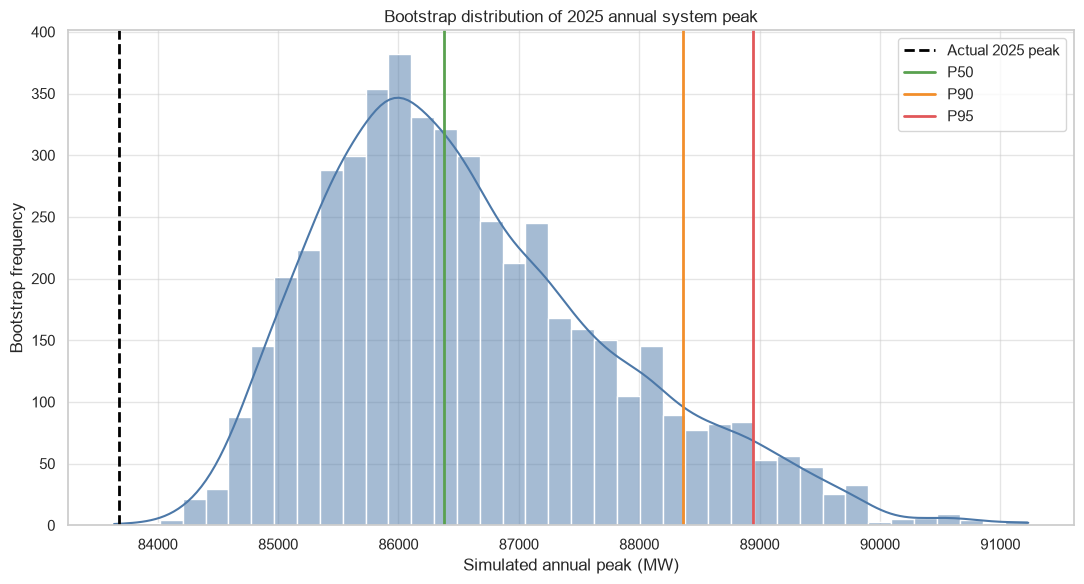


Files written in 06.14:


,filename,rows,size_bytes,path
0,06_14_annual_bootstrap_summary.csv,1,480,/report/tables/peak_uncertainty/06_14_annual_bootstrap_summary.csv
1,06_14_seasonal_bootstrap_summary.csv,4,1125,/report/tables/peak_uncertainty/06_14_seasonal_bootstrap_summary.csv
2,06_14_monthly_bootstrap_summary.csv,12,2756,/report/tables/peak_uncertainty/06_14_monthly_bootstrap_summary.csv
3,06_14_annual_bootstrap_simulations.csv,5000,113135,/report/tables/peak_uncertainty/06_14_annual_bootstrap_simulations.csv


In [ ]:


# ============================================================
# ============================================================

N_BOOTSTRAP = 5000
RANDOM_SEED = 42
CANDIDATE_TOP_FRACTION = 0.05

rng = np.random.default_rng(
    RANDOM_SEED
)

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_bootstrap = add_band_column(
    historical_system,
    final_decile_edges,
    final_decile_labels,
    "annual_forecast_decile",
)

historical_bootstrap = (
    assign_seasonal_deciles(
        historical_bootstrap,
        final_seasonal_edges,
    )
)

system_2025_bootstrap = (
    system_2025_hybrid.copy()
)

system_2025_bootstrap[
    "annual_forecast_decile"
] = (
    system_2025_bootstrap[
        "forecast_decile"
    ].astype(str)
)

# ------------------------------------------------------------
#
# ------------------------------------------------------------
annual_residual_pools = {
    str(decile): group[
        "residual_mw"
    ].to_numpy(dtype=float)

    for decile, group in (
        historical_bootstrap.groupby(
            "annual_forecast_decile",
            observed=True,
        )
    )
}

seasonal_residual_pools = {
    (
        str(season),
        str(decile),
    ): group[
        "residual_mw"
    ].to_numpy(dtype=float)

    for (season, decile), group in (
        historical_bootstrap.groupby(
            [
                "season",
                "seasonal_forecast_decile",
            ],
            observed=True,
        )
    )
}

# ------------------------------------------------------------
# ------------------------------------------------------------
def get_hybrid_residual_pool(row):
    season_name = str(
        row["season"]
    )

    if season_name in {
        "Winter",
        "Autumn",
    }:
        pool_key = (
            season_name,
            str(
                row[
                    "seasonal_forecast_decile"
                ]
            ),
        )

        pool = seasonal_residual_pools.get(
            pool_key
        )

    else:
        pool_key = str(
            row[
                "annual_forecast_decile"
            ]
        )

        pool = annual_residual_pools.get(
            pool_key
        )

    if pool is None or len(pool) == 0:
        raise ValueError(
            f"Residual pool not found:"
            f"season={season_name}, "
            f"annual_decile="
            f"{row['annual_forecast_decile']}, "
            f"seasonal_decile="
            f"{row['seasonal_forecast_decile']}"
        )

    return pool


# ------------------------------------------------------------
# ------------------------------------------------------------
def run_conditional_peak_bootstrap(
    period_data,
    period_label,
    n_bootstrap=N_BOOTSTRAP,
    candidate_fraction=(
        CANDIDATE_TOP_FRACTION
    ),
):
    period_data = (
        period_data
        .sort_values(
            "forecast_mw",
            ascending=False,
        )
        .copy()
    )

    candidate_count = max(
        24,
        int(
            np.ceil(
                len(period_data)
                * candidate_fraction
            )
        ),
    )

    candidate_data = (
        period_data
        .head(candidate_count)
        .reset_index(drop=True)
    )

    simulated_peaks = np.full(
        n_bootstrap,
        -np.inf,
        dtype=float,
    )

    for _, row in candidate_data.iterrows():
        residual_pool = (
            get_hybrid_residual_pool(row)
        )

        sampled_residuals = rng.choice(
            residual_pool,
            size=n_bootstrap,
            replace=True,
        )

        simulated_load = (
            float(row["forecast_mw"])
            + sampled_residuals
        )

        simulated_peaks = np.maximum(
            simulated_peaks,
            simulated_load,
        )

    actual_peak_mw = float(
        period_data["actual_mw"].max()
    )

    raw_peak_mw = float(
        period_data["forecast_mw"].max()
    )

    summary = {
        "period": period_label,
        "period_hours": len(period_data),
        "candidate_hours":
            candidate_count,
        "bootstrap_simulations":
            n_bootstrap,

        "actual_peak_mw":
            actual_peak_mw,

        "raw_forecast_peak_mw":
            raw_peak_mw,

        "bootstrap_peak_mean_mw":
            float(
                simulated_peaks.mean()
            ),

        "bootstrap_peak_p50_mw":
            float(
                np.quantile(
                    simulated_peaks,
                    0.50,
                )
            ),

        "bootstrap_peak_p90_mw":
            float(
                np.quantile(
                    simulated_peaks,
                    0.90,
                )
            ),

        "bootstrap_peak_p95_mw":
            float(
                np.quantile(
                    simulated_peaks,
                    0.95,
                )
            ),

        "bootstrap_peak_p99_mw":
            float(
                np.quantile(
                    simulated_peaks,
                    0.99,
                )
            ),
    }

    summary[
        "bootstrap_p50_error_mw"
    ] = (
        summary[
            "bootstrap_peak_p50_mw"
        ]
        - actual_peak_mw
    )

    summary[
        "bootstrap_p90_margin_mw"
    ] = (
        summary[
            "bootstrap_peak_p90_mw"
        ]
        - actual_peak_mw
    )

    summary[
        "bootstrap_p95_margin_mw"
    ] = (
        summary[
            "bootstrap_peak_p95_mw"
        ]
        - actual_peak_mw
    )

    return summary, simulated_peaks


# ------------------------------------------------------------
# ------------------------------------------------------------
annual_bootstrap_summary, (
    annual_bootstrap_simulations
) = run_conditional_peak_bootstrap(
    system_2025_bootstrap,
    "2025 Annual",
)

# ------------------------------------------------------------
# ------------------------------------------------------------
seasonal_bootstrap_records = []

for season_name in SEASON_ORDER:
    season_data = (
        system_2025_bootstrap.loc[
            system_2025_bootstrap[
                "season"
            ].eq(season_name)
        ]
    )

    season_summary, _ = (
        run_conditional_peak_bootstrap(
            season_data,
            f"2025 {season_name}",
        )
    )

    season_summary["season"] = (
        season_name
    )

    seasonal_bootstrap_records.append(
        season_summary
    )

seasonal_bootstrap_summary = (
    pd.DataFrame(
        seasonal_bootstrap_records
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
monthly_bootstrap_records = []

for month_number in range(1, 13):
    month_data = (
        system_2025_bootstrap.loc[
            system_2025_bootstrap[
                "local_month"
            ].eq(month_number)
        ]
    )

    month_summary, _ = (
        run_conditional_peak_bootstrap(
            month_data,
            f"2025 Month {month_number:02d}",
        )
    )

    month_summary["local_month"] = (
        month_number
    )

    monthly_bootstrap_records.append(
        month_summary
    )

monthly_bootstrap_summary = (
    pd.DataFrame(
        monthly_bootstrap_records
    )
)

annual_bootstrap_summary_df = (
    pd.DataFrame(
        [annual_bootstrap_summary]
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
bootstrap_display_columns = [
    "period",
    "actual_peak_mw",
    "raw_forecast_peak_mw",
    "bootstrap_peak_p50_mw",
    "bootstrap_p50_error_mw",
    "bootstrap_peak_p90_mw",
    "bootstrap_p90_margin_mw",
    "bootstrap_peak_p95_mw",
    "bootstrap_p95_margin_mw",
]

print("2025 annual bootstrap peak distribution:")
display(
    annual_bootstrap_summary_df[
        bootstrap_display_columns
    ].round(1)
)

print("\n2025 seasonal bootstrap peak distribution:")
display(
    seasonal_bootstrap_summary[
        [
            "season",
            *bootstrap_display_columns[1:],
        ]
    ].round(1)
)

print("\n2025 monthly bootstrap peak distribution:")
display(
    monthly_bootstrap_summary[
        [
            "local_month",
            *bootstrap_display_columns[1:],
        ]
    ].round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(11, 6),
)

sns.histplot(
    annual_bootstrap_simulations,
    bins=40,
    kde=True,
    ax=ax,
    color="#4C78A8",
)

ax.axvline(
    annual_bootstrap_summary[
        "actual_peak_mw"
    ],
    color="black",
    linestyle="--",
    linewidth=2,
    label="Actual 2025 peak",
)

for quantile_name, color in [
    ("bootstrap_peak_p50_mw", "#59A14F"),
    ("bootstrap_peak_p90_mw", "#F28E2B"),
    ("bootstrap_peak_p95_mw", "#E15759"),
]:
    ax.axvline(
        annual_bootstrap_summary[
            quantile_name
        ],
        color=color,
        linewidth=2,
        label=quantile_name.replace(
            "bootstrap_peak_",
            "",
        ).replace(
            "_mw",
            "",
        ).upper(),
    )

ax.set_title(
    "Bootstrap distribution of 2025 annual system peak"
)
ax.set_xlabel("Simulated annual peak (MW)")
ax.set_ylabel("Bootstrap frequency")
ax.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# ------------------------------------------------------------
annual_simulation_table = pd.DataFrame(
    {
        "simulation_id":
            np.arange(
                1,
                N_BOOTSTRAP + 1,
            ),

        "simulated_annual_peak_mw":
            annual_bootstrap_simulations,
    }
)

outputs_06_14 = {
    "06_14_annual_bootstrap_summary.csv":
        annual_bootstrap_summary_df,

    "06_14_seasonal_bootstrap_summary.csv":
        seasonal_bootstrap_summary,

    "06_14_monthly_bootstrap_summary.csv":
        monthly_bootstrap_summary,

    "06_14_annual_bootstrap_simulations.csv":
        annual_simulation_table,
}

saved_06_14_records = []

for filename, table in outputs_06_14.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_14_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_14 = pd.DataFrame(
    saved_06_14_records
)

print("\nFiles written in 06.14:")
display(saved_06_14)

Capacity planning needs a distribution of plausible maximum demand, not only one corrected peak estimate. The following simulations propagate historical residual variability into annual, seasonal, and monthly maximum-load scenarios.

**Why the initial bootstrap is not the final choice.** Independently sampling an error for every hour can exaggerate the maximum of a long sequence. Section 06.14 is therefore retained as a conservative stress-test sensitivity case, **not** as the final planning P50/P90/P95. The next method samples residuals in daily blocks to preserve within-day dependence.

## 06.15 — Conditional daily-block bootstrap

Resample complete historical daily residual profiles conditional on season and forecast daily-peak quintile. This preserves within-day residual structure. Run 5,000 simulations and summarize annual, seasonal, and monthly peak distributions.

In [ ]:


# ============================================================
# ============================================================

DAILY_BLOCK_SIMULATIONS = 5000
DAILY_BLOCK_RANDOM_SEED = 42

block_rng = np.random.default_rng(
    DAILY_BLOCK_RANDOM_SEED
)

# ------------------------------------------------------------
# ------------------------------------------------------------
def build_daily_peak_quintile_edges(
    daily_summary,
):
    edge_lookup = {}

    for season_name in SEASON_ORDER:
        season_daily_peaks = daily_summary.loc[
            daily_summary["season"].eq(
                season_name
            ),
            "daily_forecast_peak_mw",
        ]

        edge_lookup[season_name] = (
            make_quantile_edges(
                season_daily_peaks,
                np.linspace(0, 1, 6),
            )
        )

    return edge_lookup


# ------------------------------------------------------------
# ------------------------------------------------------------
def assign_daily_peak_quintile(
    daily_summary,
    edge_lookup,
):
    result = daily_summary.copy()

    result["daily_peak_quintile"] = None

    quintile_labels = [
        "Q1",
        "Q2",
        "Q3",
        "Q4",
        "Q5",
    ]

    for season_name in SEASON_ORDER:
        season_mask = result["season"].eq(
            season_name
        )

        assigned = pd.cut(
            result.loc[
                season_mask,
                "daily_forecast_peak_mw",
            ],
            bins=edge_lookup[season_name],
            labels=quintile_labels,
            include_lowest=True,
            ordered=True,
        )

        result.loc[
            season_mask,
            "daily_peak_quintile",
        ] = assigned.astype(str).values

    if result[
        "daily_peak_quintile"
    ].isna().any():
        raise ValueError(
            "Some dates could not be assigned a daily-peak quintile."
        )

    return result


# ------------------------------------------------------------
# ------------------------------------------------------------
#
# ------------------------------------------------------------
historical_block_data = (
    historical_bootstrap.copy()
)

historical_local_index = pd.DatetimeIndex(
    historical_block_data[
        "timestamp_local"
    ]
)

historical_block_data[
    "local_date"
] = (
    historical_local_index
    - pd.Timedelta(seconds=1)
).date


system_2025_block_data = (
    system_2025_bootstrap.copy()
)

test_local_index = pd.DatetimeIndex(
    system_2025_block_data[
        "timestamp_local"
    ]
)

system_2025_block_data[
    "local_date"
] = (
    test_local_index
    - pd.Timedelta(seconds=1)
).date

operating_day_hour_check = (
    system_2025_block_data
    .groupby("local_date")
    .size()
    .value_counts()
    .sort_index()
)

print("Distribution of hours per 2025 local date:")
print(
    operating_day_hour_check.to_string()
)

print(
    "\nDate range:",
    system_2025_block_data[
        "local_date"
    ].min(),
    "→",
    system_2025_block_data[
        "local_date"
    ].max(),
)
# ------------------------------------------------------------
historical_daily_summary = (
    historical_block_data
    .groupby("local_date")
    .agg(
        season=("season", "first"),

        daily_hours=(
            "timestamp_utc",
            "size",
        ),

        daily_forecast_peak_mw=(
            "forecast_mw",
            "max",
        ),
    )
    .reset_index()
)

historical_daily_summary_24h = (
    historical_daily_summary.loc[
        historical_daily_summary[
            "daily_hours"
        ].eq(24)
    ]
    .copy()
)

daily_peak_edges = (
    build_daily_peak_quintile_edges(
        historical_daily_summary_24h
    )
)

historical_daily_summary_24h = (
    assign_daily_peak_quintile(
        historical_daily_summary_24h,
        daily_peak_edges,
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
test_daily_summary = (
    system_2025_block_data
    .groupby("local_date")
    .agg(
        season=("season", "first"),

        local_month=(
            "local_month",
            "first",
        ),

        daily_hours=(
            "timestamp_utc",
            "size",
        ),

        daily_forecast_peak_mw=(
            "forecast_mw",
            "max",
        ),
    )
    .reset_index()
)

test_daily_summary = (
    assign_daily_peak_quintile(
        test_daily_summary,
        daily_peak_edges,
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
historical_day_conditions = (
    historical_daily_summary_24h[
        [
            "local_date",
            "season",
            "daily_peak_quintile",
        ]
    ]
)

historical_blocks_source = (
    historical_block_data.merge(
        historical_day_conditions,
        on=[
            "local_date",
            "season",
        ],
        how="inner",
        validate="many_to_one",
    )
)

daily_residual_block_pools = {}

for (
    season_name,
    quintile_name,
), condition_data in (
    historical_blocks_source.groupby(
        [
            "season",
            "daily_peak_quintile",
        ],
        observed=True,
    )
):
    residual_blocks = []

    for _, day_data in (
        condition_data.groupby(
            "local_date"
        )
    ):
        day_data = day_data.sort_values(
            "timestamp_utc"
        )

        residual_array = (
            day_data[
                "residual_mw"
            ].to_numpy(dtype=float)
        )

        if len(residual_array) == 24:
            residual_blocks.append(
                residual_array
            )

    if residual_blocks:
        daily_residual_block_pools[
            (
                str(season_name),
                str(quintile_name),
            )
        ] = np.vstack(
            residual_blocks
        )

# ------------------------------------------------------------
# ------------------------------------------------------------
block_pool_summary_records = []

for pool_key, pool_array in (
    daily_residual_block_pools.items()
):
    block_pool_summary_records.append(
        {
            "season": pool_key[0],
            "daily_peak_quintile":
                pool_key[1],
            "historical_days":
                pool_array.shape[0],
            "hours_per_block":
                pool_array.shape[1],
        }
    )

block_pool_summary = pd.DataFrame(
    block_pool_summary_records
)

print("Historical daily-block residual-pool summary:")
display(
    block_pool_summary.sort_values(
        [
            "season",
            "daily_peak_quintile",
        ]
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
def run_daily_block_bootstrap(
    test_hourly_data,
    test_day_summary,
    residual_block_pools,
    n_simulations=(
        DAILY_BLOCK_SIMULATIONS
    ),
):
    annual_maxima = np.full(
        n_simulations,
        -np.inf,
    )

    seasonal_maxima = {
        season: np.full(
            n_simulations,
            -np.inf,
        )
        for season in SEASON_ORDER
    }

    monthly_maxima = {
        month: np.full(
            n_simulations,
            -np.inf,
        )
        for month in range(1, 13)
    }

    for day_record in (
        test_day_summary.itertuples(
            index=False
        )
    ):
        local_date = day_record.local_date
        season_name = day_record.season
        month_number = int(
            day_record.local_month
        )
        quintile_name = (
            day_record.daily_peak_quintile
        )

        day_data = (
            test_hourly_data.loc[
                test_hourly_data[
                    "local_date"
                ].eq(local_date)
            ]
            .sort_values("timestamp_utc")
        )

        forecast_curve = (
            day_data[
                "forecast_mw"
            ].to_numpy(dtype=float)
        )

        block_pool = residual_block_pools[
            (
                season_name,
                quintile_name,
            )
        ]

        sampled_block_indices = (
            block_rng.integers(
                0,
                block_pool.shape[0],
                size=n_simulations,
            )
        )

        sampled_blocks = block_pool[
            sampled_block_indices
        ]

        day_length = len(forecast_curve)

        if day_length == 24:
            aligned_blocks = sampled_blocks

        elif day_length == 23:
            aligned_blocks = (
                sampled_blocks[:, :23]
            )

        elif day_length == 25:
            aligned_blocks = np.concatenate(
                [
                    sampled_blocks,
                    sampled_blocks[:, -1:],
                ],
                axis=1,
            )

        else:
            raise ValueError(
                f"{local_date} has an unexpected number of hours:"
                f"{day_length}"
            )

        simulated_day_loads = (
            forecast_curve[None, :]
            + aligned_blocks
        )

        simulated_day_peaks = (
            simulated_day_loads.max(
                axis=1
            )
        )

        annual_maxima = np.maximum(
            annual_maxima,
            simulated_day_peaks,
        )

        seasonal_maxima[
            season_name
        ] = np.maximum(
            seasonal_maxima[
                season_name
            ],
            simulated_day_peaks,
        )

        monthly_maxima[
            month_number
        ] = np.maximum(
            monthly_maxima[
                month_number
            ],
            simulated_day_peaks,
        )

    return (
        annual_maxima,
        seasonal_maxima,
        monthly_maxima,
    )


(
    daily_block_annual_simulations,
    daily_block_seasonal_simulations,
    daily_block_monthly_simulations,
) = run_daily_block_bootstrap(
    system_2025_block_data,
    test_daily_summary,
    daily_residual_block_pools,
)

# ------------------------------------------------------------
# ------------------------------------------------------------
def summarize_bootstrap_distribution(
    simulated_peaks,
    actual_peak_mw,
    raw_peak_mw,
    period_label,
):
    return {
        "period": period_label,

        "actual_peak_mw":
            float(actual_peak_mw),

        "raw_forecast_peak_mw":
            float(raw_peak_mw),

        "bootstrap_peak_mean_mw":
            float(
                simulated_peaks.mean()
            ),

        "bootstrap_peak_p50_mw":
            float(
                np.quantile(
                    simulated_peaks,
                    0.50,
                )
            ),

        "bootstrap_peak_p90_mw":
            float(
                np.quantile(
                    simulated_peaks,
                    0.90,
                )
            ),

        "bootstrap_peak_p95_mw":
            float(
                np.quantile(
                    simulated_peaks,
                    0.95,
                )
            ),

        "bootstrap_peak_p99_mw":
            float(
                np.quantile(
                    simulated_peaks,
                    0.99,
                )
            ),
    }


daily_block_annual_summary = pd.DataFrame(
    [
        summarize_bootstrap_distribution(
            daily_block_annual_simulations,
            system_2025_block_data[
                "actual_mw"
            ].max(),
            system_2025_block_data[
                "forecast_mw"
            ].max(),
            "2025 Annual",
        )
    ]
)

seasonal_block_records = []

for season_name in SEASON_ORDER:
    season_data = (
        system_2025_block_data.loc[
            system_2025_block_data[
                "season"
            ].eq(season_name)
        ]
    )

    record = summarize_bootstrap_distribution(
        daily_block_seasonal_simulations[
            season_name
        ],
        season_data["actual_mw"].max(),
        season_data["forecast_mw"].max(),
        f"2025 {season_name}",
    )

    record["season"] = season_name
    seasonal_block_records.append(record)

daily_block_seasonal_summary = (
    pd.DataFrame(
        seasonal_block_records
    )
)

monthly_block_records = []

for month_number in range(1, 13):
    month_data = (
        system_2025_block_data.loc[
            system_2025_block_data[
                "local_month"
            ].eq(month_number)
        ]
    )

    record = summarize_bootstrap_distribution(
        daily_block_monthly_simulations[
            month_number
        ],
        month_data["actual_mw"].max(),
        month_data["forecast_mw"].max(),
        f"2025 Month {month_number:02d}",
    )

    record["local_month"] = month_number
    monthly_block_records.append(record)

daily_block_monthly_summary = pd.DataFrame(
    monthly_block_records
)

for table in [
    daily_block_annual_summary,
    daily_block_seasonal_summary,
    daily_block_monthly_summary,
]:
    table["bootstrap_p50_error_mw"] = (
        table["bootstrap_peak_p50_mw"]
        - table["actual_peak_mw"]
    )

    table["bootstrap_p90_margin_mw"] = (
        table["bootstrap_peak_p90_mw"]
        - table["actual_peak_mw"]
    )

    table["bootstrap_p95_margin_mw"] = (
        table["bootstrap_peak_p95_mw"]
        - table["actual_peak_mw"]
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
print("\n2025 daily-block bootstrap annual peak:")
display(
    daily_block_annual_summary.round(1)
)

print("\n2025 daily-block bootstrap seasonal peaks:")
display(
    daily_block_seasonal_summary.round(1)
)

print("\n2025 daily-block bootstrap monthly peaks:")
display(
    daily_block_monthly_summary.round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_15 = {
    "06_15_daily_block_pool_summary.csv":
        block_pool_summary,

    "06_15_annual_daily_block_bootstrap.csv":
        daily_block_annual_summary,

    "06_15_seasonal_daily_block_bootstrap.csv":
        daily_block_seasonal_summary,

    "06_15_monthly_daily_block_bootstrap.csv":
        daily_block_monthly_summary,
}

saved_06_15_records = []

for filename, table in outputs_06_15.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_15_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_15 = pd.DataFrame(
    saved_06_15_records
)

print("\nFiles written in 06.15:")
display(saved_06_15)

Distribution of hours per 2025 local date:
23      1
24    363
25      1

Date range: 2025-01-01 → 2025-12-31
Historical daily-block residual-pool summary:


,season,daily_peak_quintile,historical_days,hours_per_block
0,Autumn,Q1,34,24
1,Autumn,Q2,36,24
2,Autumn,Q3,36,24
3,Autumn,Q4,36,24
4,Autumn,Q5,36,24
5,Spring,Q1,37,24
6,Spring,Q2,36,24
7,Spring,Q3,36,24
8,Spring,Q4,36,24
9,Spring,Q5,35,24



2025 daily-block bootstrap annual peak:


,period,actual_peak_mw,raw_forecast_peak_mw,bootstrap_peak_mean_mw,bootstrap_peak_p50_mw,bootstrap_peak_p90_mw,bootstrap_peak_p95_mw,bootstrap_peak_p99_mw,bootstrap_p50_error_mw,bootstrap_p90_margin_mw,bootstrap_p95_margin_mw
0,2025 Annual,83679.0,82561.5,84728.3,84782.9,85646.2,85938.4,86937.1,1103.9,1967.2,2259.4



2025 daily-block bootstrap seasonal peaks:


,period,actual_peak_mw,raw_forecast_peak_mw,bootstrap_peak_mean_mw,bootstrap_peak_p50_mw,bootstrap_peak_p90_mw,bootstrap_peak_p95_mw,bootstrap_peak_p99_mw,season,bootstrap_p50_error_mw,bootstrap_p90_margin_mw,bootstrap_p95_margin_mw
0,2025 Winter,80524.7,70989.8,77712.0,78162.9,80189.0,82903.3,83130.6,Winter,-2361.8,-335.7,2378.6
1,2025 Spring,78391.8,74849.4,78391.1,78288.1,80363.0,81338.3,81677.0,Spring,-103.7,1971.1,2946.4
2,2025 Summer,83679.0,82561.5,84727.4,84782.9,85646.2,85938.4,86937.1,Summer,1103.9,1967.2,2259.4
3,2025 Autumn,79917.5,78858.0,81527.0,81487.0,82877.4,82960.0,83861.6,Autumn,1569.5,2959.9,3042.5



2025 daily-block bootstrap monthly peaks:


,period,actual_peak_mw,raw_forecast_peak_mw,bootstrap_peak_mean_mw,bootstrap_peak_p50_mw,bootstrap_peak_p90_mw,bootstrap_peak_p95_mw,bootstrap_peak_p99_mw,local_month,bootstrap_p50_error_mw,bootstrap_p90_margin_mw,bootstrap_p95_margin_mw
0,2025 Month 01,77478.3,70638.2,76140.2,76122.4,79010.9,79442.5,83130.6,1,-1355.8,1532.6,1964.2
1,2025 Month 02,80524.7,70989.8,76108.8,75516.3,79933.6,80949.7,82903.3,2,-5008.4,-591.1,425.0
2,2025 Month 03,62920.4,62464.3,64986.0,65015.7,67005.4,68258.5,69320.4,3,2095.3,4085.0,5338.1
3,2025 Month 04,65613.5,63512.3,67670.3,67293.0,69863.3,70140.2,70368.5,4,1679.5,4249.8,4526.7
4,2025 Month 05,78391.8,74849.4,78391.1,78288.1,80363.0,81338.3,81677.0,5,-103.7,1971.1,2946.4
5,2025 Month 06,77351.0,75691.9,79296.7,79250.8,80190.4,80491.0,80552.8,6,1899.8,2839.4,3140.0
6,2025 Month 07,81706.5,81168.2,83666.4,83551.7,84547.0,85319.4,85999.4,7,1845.2,2840.5,3612.8
7,2025 Month 08,83679.0,82561.5,84593.5,84683.0,85447.4,85661.6,86937.1,8,1004.0,1768.4,1982.6
8,2025 Month 09,79917.5,78858.0,81527.0,81487.0,82877.4,82960.0,83861.6,9,1569.5,2959.9,3042.5
9,2025 Month 10,75889.2,73996.4,77039.1,76938.3,78098.5,78347.0,79000.1,10,1049.2,2209.3,2457.8



Files written in 06.15:


,filename,rows,size_bytes,path
0,06_15_daily_block_pool_summary.csv,20,379,/report/tables/peak_uncertainty/06_15_daily_block_pool_summary.csv
1,06_15_annual_daily_block_bootstrap.csv,1,419,/report/tables/peak_uncertainty/06_15_annual_daily_block_bootstrap.csv
2,06_15_seasonal_daily_block_bootstrap.csv,4,1022,/report/tables/peak_uncertainty/06_15_seasonal_daily_block_bootstrap.csv
3,06_15_monthly_daily_block_bootstrap.csv,12,2575,/report/tables/peak_uncertainty/06_15_monthly_daily_block_bootstrap.csv


**Bootstrap selection.** Conditional daily-block resampling better preserves the daily structure of forecast errors and is used for the principal peak-distribution scenarios. These simulated quantiles remain scenario estimates, not proven probabilistic coverage guarantees.

## 06.16 — Final system capacity-planning inputs

Combine raw peak forecasts, calibrated hourly peak values, and daily-block Bootstrap P50/P90/P95/P99 into the system tables used by Stage 07. Planning increments represent simulated peak demand above the uncalibrated forecast.

Final annual system capacity-planning inputs:


,period,raw_forecast_peak_mw,hourly_curve_p50_peak_mw,bootstrap_peak_p50_mw,bootstrap_peak_p90_mw,bootstrap_peak_p95_mw,bootstrap_peak_p99_mw,p90_addition_vs_raw_mw,p95_addition_vs_raw_mw,independent_hour_stress_p95_mw
0,2025 Annual,82561.5,84223.3,84782.9,85646.2,85938.4,86937.1,3084.7,3376.8,88947.5



Final seasonal system capacity-planning inputs:


,season,raw_forecast_peak_mw,bootstrap_peak_p50_mw,bootstrap_peak_p90_mw,bootstrap_peak_p95_mw,p90_addition_vs_raw_mw,p95_addition_vs_raw_mw
0,Winter,70989.8,78162.9,80189.0,82903.3,9199.3,11913.5
1,Spring,74849.4,78288.1,80363.0,81338.3,5513.6,6488.9
2,Summer,82561.5,84782.9,85646.2,85938.4,3084.7,3376.8
3,Autumn,78858.0,81487.0,82877.4,82960.0,4019.4,4102.0



Final monthly system capacity-planning inputs:


,local_month,raw_forecast_peak_mw,bootstrap_peak_p50_mw,bootstrap_peak_p90_mw,bootstrap_peak_p95_mw,p90_addition_vs_raw_mw,p95_addition_vs_raw_mw
0,1,70638.2,76122.4,79010.9,79442.5,8372.7,8804.3
1,2,70989.8,75516.3,79933.6,80949.7,8943.8,9959.9
2,3,62464.3,65015.7,67005.4,68258.5,4541.1,5794.2
3,4,63512.3,67293.0,69863.3,70140.2,6351.0,6627.9
4,5,74849.4,78288.1,80363.0,81338.3,5513.6,6488.9
5,6,75691.9,79250.8,80190.4,80491.0,4498.5,4799.0
6,7,81168.2,83551.7,84547.0,85319.4,3378.8,4151.2
7,8,82561.5,84683.0,85447.4,85661.6,2885.8,3100.1
8,9,78858.0,81487.0,82877.4,82960.0,4019.4,4102.0
9,10,73996.4,76938.3,78098.5,78347.0,4102.0,4350.5


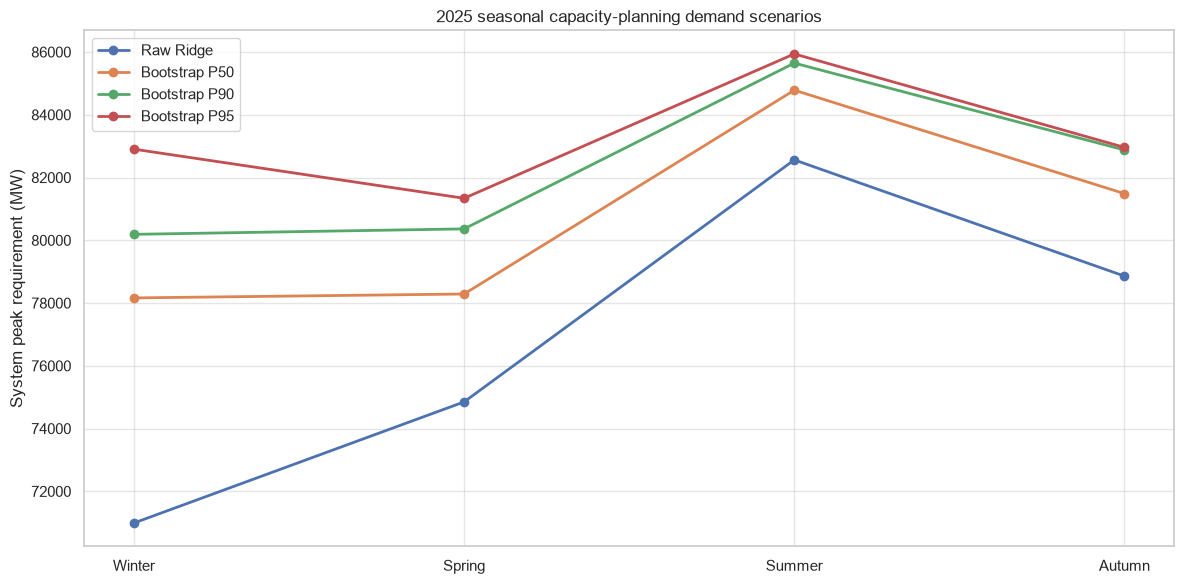


Files written in 06.16:


,filename,rows,size_bytes,path
0,06_16_final_annual_capacity_planning.csv,1,594,/report/tables/peak_uncertainty/06_16_final_annual_capacity_planning.csv
1,06_16_final_seasonal_capacity_planning.csv,4,1249,/report/tables/peak_uncertainty/06_16_final_seasonal_capacity_planning.csv
2,06_16_final_monthly_capacity_planning.csv,12,3109,/report/tables/peak_uncertainty/06_16_final_monthly_capacity_planning.csv


In [ ]:

# ============================================================
# ============================================================

# ------------------------------------------------------------
# ------------------------------------------------------------
def add_planning_margins(table):
    result = table.copy()

    result[
        "p50_addition_vs_raw_mw"
    ] = (
        result["bootstrap_peak_p50_mw"]
        - result["raw_forecast_peak_mw"]
    )

    result[
        "p90_addition_vs_raw_mw"
    ] = (
        result["bootstrap_peak_p90_mw"]
        - result["raw_forecast_peak_mw"]
    )

    result[
        "p95_addition_vs_raw_mw"
    ] = (
        result["bootstrap_peak_p95_mw"]
        - result["raw_forecast_peak_mw"]
    )

    result[
        "p99_addition_vs_raw_mw"
    ] = (
        result["bootstrap_peak_p99_mw"]
        - result["raw_forecast_peak_mw"]
    )

    return result


# ------------------------------------------------------------
# ------------------------------------------------------------
hybrid_monthly_peaks_2025 = (
    summarize_period_peaks(
        system_2025_hybrid_planning,
        group_columns=["local_month"],
        summary_name="Monthly hybrid",
    )
    .sort_values("local_month")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
annual_point_summary = (
    hybrid_annual_peaks_2025[
        [
            "actual_peak_mw",
            "raw_peak_mw",
            "p50_peak_mw",
            "p90_planning_peak_mw",
            "p95_planning_peak_mw",
        ]
    ]
    .rename(
        columns={
            "raw_peak_mw":
                "raw_forecast_peak_mw",

            "p50_peak_mw":
                "hourly_curve_p50_peak_mw",

            "p90_planning_peak_mw":
                "hourly_curve_p90_peak_mw",

            "p95_planning_peak_mw":
                "hourly_curve_p95_peak_mw",
        }
    )
)

annual_bootstrap_columns = (
    daily_block_annual_summary[
        [
            "bootstrap_peak_p50_mw",
            "bootstrap_peak_p90_mw",
            "bootstrap_peak_p95_mw",
            "bootstrap_peak_p99_mw",
        ]
    ]
)

final_annual_planning = pd.concat(
    [
        annual_point_summary.reset_index(
            drop=True
        ),
        annual_bootstrap_columns.reset_index(
            drop=True
        ),
    ],
    axis=1,
)

final_annual_planning.insert(
    0,
    "period",
    "2025 Annual",
)

final_annual_planning = (
    add_planning_margins(
        final_annual_planning
    )
)

final_annual_planning[
    "independent_hour_stress_p95_mw"
] = float(
    annual_bootstrap_summary_df.loc[
        0,
        "bootstrap_peak_p95_mw",
    ]
)

# ------------------------------------------------------------
# ------------------------------------------------------------
seasonal_point_summary = (
    hybrid_seasonal_peaks_2025[
        [
            "season",
            "actual_peak_mw",
            "raw_peak_mw",
            "p50_peak_mw",
            "p90_planning_peak_mw",
            "p95_planning_peak_mw",
        ]
    ]
    .rename(
        columns={
            "raw_peak_mw":
                "raw_forecast_peak_mw",

            "p50_peak_mw":
                "hourly_curve_p50_peak_mw",

            "p90_planning_peak_mw":
                "hourly_curve_p90_peak_mw",

            "p95_planning_peak_mw":
                "hourly_curve_p95_peak_mw",
        }
    )
)

seasonal_bootstrap_columns = (
    daily_block_seasonal_summary[
        [
            "season",
            "bootstrap_peak_p50_mw",
            "bootstrap_peak_p90_mw",
            "bootstrap_peak_p95_mw",
            "bootstrap_peak_p99_mw",
        ]
    ]
)

final_seasonal_planning = (
    seasonal_point_summary.merge(
        seasonal_bootstrap_columns,
        on="season",
        how="inner",
        validate="one_to_one",
    )
)

final_seasonal_planning = (
    add_planning_margins(
        final_seasonal_planning
    )
)

final_seasonal_planning[
    "_season_order"
] = (
    final_seasonal_planning[
        "season"
    ].map(
        {
            season: position
            for position, season in enumerate(
                SEASON_ORDER
            )
        }
    )
)

final_seasonal_planning = (
    final_seasonal_planning
    .sort_values("_season_order")
    .drop(columns="_season_order")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
monthly_point_summary = (
    hybrid_monthly_peaks_2025[
        [
            "local_month",
            "actual_peak_mw",
            "raw_peak_mw",
            "p50_peak_mw",
            "p90_planning_peak_mw",
            "p95_planning_peak_mw",
        ]
    ]
    .rename(
        columns={
            "raw_peak_mw":
                "raw_forecast_peak_mw",

            "p50_peak_mw":
                "hourly_curve_p50_peak_mw",

            "p90_planning_peak_mw":
                "hourly_curve_p90_peak_mw",

            "p95_planning_peak_mw":
                "hourly_curve_p95_peak_mw",
        }
    )
)

monthly_bootstrap_columns = (
    daily_block_monthly_summary[
        [
            "local_month",
            "bootstrap_peak_p50_mw",
            "bootstrap_peak_p90_mw",
            "bootstrap_peak_p95_mw",
            "bootstrap_peak_p99_mw",
        ]
    ]
)

final_monthly_planning = (
    monthly_point_summary.merge(
        monthly_bootstrap_columns,
        on="local_month",
        how="inner",
        validate="one_to_one",
    )
)

final_monthly_planning = (
    add_planning_margins(
        final_monthly_planning
    )
)

final_monthly_planning = (
    final_monthly_planning
    .sort_values("local_month")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
annual_display_columns = [
    "period",
    "raw_forecast_peak_mw",
    "hourly_curve_p50_peak_mw",
    "bootstrap_peak_p50_mw",
    "bootstrap_peak_p90_mw",
    "bootstrap_peak_p95_mw",
    "bootstrap_peak_p99_mw",
    "p90_addition_vs_raw_mw",
    "p95_addition_vs_raw_mw",
    "independent_hour_stress_p95_mw",
]

print("Final annual system capacity-planning inputs:")
display(
    final_annual_planning[
        annual_display_columns
    ].round(1)
)

print("\nFinal seasonal system capacity-planning inputs:")
display(
    final_seasonal_planning[
        [
            "season",
            "raw_forecast_peak_mw",
            "bootstrap_peak_p50_mw",
            "bootstrap_peak_p90_mw",
            "bootstrap_peak_p95_mw",
            "p90_addition_vs_raw_mw",
            "p95_addition_vs_raw_mw",
        ]
    ].round(1)
)

print("\nFinal monthly system capacity-planning inputs:")
display(
    final_monthly_planning[
        [
            "local_month",
            "raw_forecast_peak_mw",
            "bootstrap_peak_p50_mw",
            "bootstrap_peak_p90_mw",
            "bootstrap_peak_p95_mw",
            "p90_addition_vs_raw_mw",
            "p95_addition_vs_raw_mw",
        ]
    ].round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(12, 6),
)

season_positions = np.arange(
    len(final_seasonal_planning)
)

ax.plot(
    season_positions,
    final_seasonal_planning[
        "raw_forecast_peak_mw"
    ],
    marker="o",
    linewidth=2,
    label="Raw Ridge",
)

ax.plot(
    season_positions,
    final_seasonal_planning[
        "bootstrap_peak_p50_mw"
    ],
    marker="o",
    linewidth=2,
    label="Bootstrap P50",
)

ax.plot(
    season_positions,
    final_seasonal_planning[
        "bootstrap_peak_p90_mw"
    ],
    marker="o",
    linewidth=2,
    label="Bootstrap P90",
)

ax.plot(
    season_positions,
    final_seasonal_planning[
        "bootstrap_peak_p95_mw"
    ],
    marker="o",
    linewidth=2,
    label="Bootstrap P95",
)

ax.set_xticks(
    season_positions,
    final_seasonal_planning[
        "season"
    ],
)

ax.set_ylabel(
    "System peak requirement (MW)"
)

ax.set_title(
    "2025 seasonal capacity-planning demand scenarios"
)

ax.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_16 = {
    "06_16_final_annual_capacity_planning.csv":
        final_annual_planning,

    "06_16_final_seasonal_capacity_planning.csv":
        final_seasonal_planning,

    "06_16_final_monthly_capacity_planning.csv":
        final_monthly_planning,
}

saved_06_16_records = []

for filename, table in outputs_06_16.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_16_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_16 = pd.DataFrame(
    saved_06_16_records
)

print("\nFiles written in 06.16:")
display(saved_06_16)

**Regional question.** Which zones contribute most to the simultaneous ERCOT system peak, and which zones account for the system-level forecast error at that timestamp?

## 06.17 — Coincident regional contributions

Decompose load and underestimation into the eight regional contributions at observed and predicted system-peak timestamps, and contrast these with each zone’s independent annual maximum.

Key system-peak timestamps:
Actual annual system peak: 2025-08-18 23:00:00+00:00
Raw Ridge annual peak: 2025-08-18 22:00:00+00:00
Hybrid P50 curve peak: 2025-08-18 22:00:00+00:00
Hybrid P90 curve peak: 2025-08-18 22:00:00+00:00
Hybrid P95 curve peak: 2025-08-18 22:00:00+00:00

Regional contributions at the actual system-peak timestamp:


,zone,actual_mw,actual_contribution_pct,forecast_mw,residual_mw,share_of_positive_residual_pct
0,NCENT,26581.62,31.77,24949.05,1632.58,61.86
1,COAST,22349.50,26.71,21687.99,661.51,25.06
2,SCENT,14519.96,17.35,14299.93,220.03,8.34
3,FWEST,7046.25,8.42,7640.64,-594.40,0.00
4,SOUTH,6508.85,7.78,6383.62,125.23,4.74
5,EAST,2888.69,3.45,2965.52,-76.83,0.00
6,NORTH,1942.52,2.32,2223.23,-280.71,0.00
7,WEST,1841.61,2.20,1955.94,-114.33,0.00



2025 regional annual peaks:


,zone,actual_regional_peak_mw,forecast_regional_peak_mw,regional_peak_error_mw,regional_peak_timing_error_hours,actual_load_at_system_peak_mw,residual_at_system_peak_mw,regional_peak_coincides_with_system_peak
0,NCENT,27531.8,26125.8,-1405.9,0.0,26581.6,1632.6,False
1,COAST,23006.7,22227.1,-779.6,-48.0,22349.5,661.5,False
2,SCENT,14799.3,14304.4,-494.9,4306.0,14520.0,220.0,False
3,FWEST,8773.1,8617.2,-155.8,840.0,7046.2,-594.4,False
4,SOUTH,7155.6,6628.5,-527.1,4879.0,6508.8,125.2,False
5,EAST,3696.7,3008.0,-688.7,4327.0,2888.7,-76.8,False
6,NORTH,2732.1,2505.1,-227.0,-578.0,1942.5,-280.7,False
7,WEST,2116.5,2045.2,-71.3,4209.0,1841.6,-114.3,False


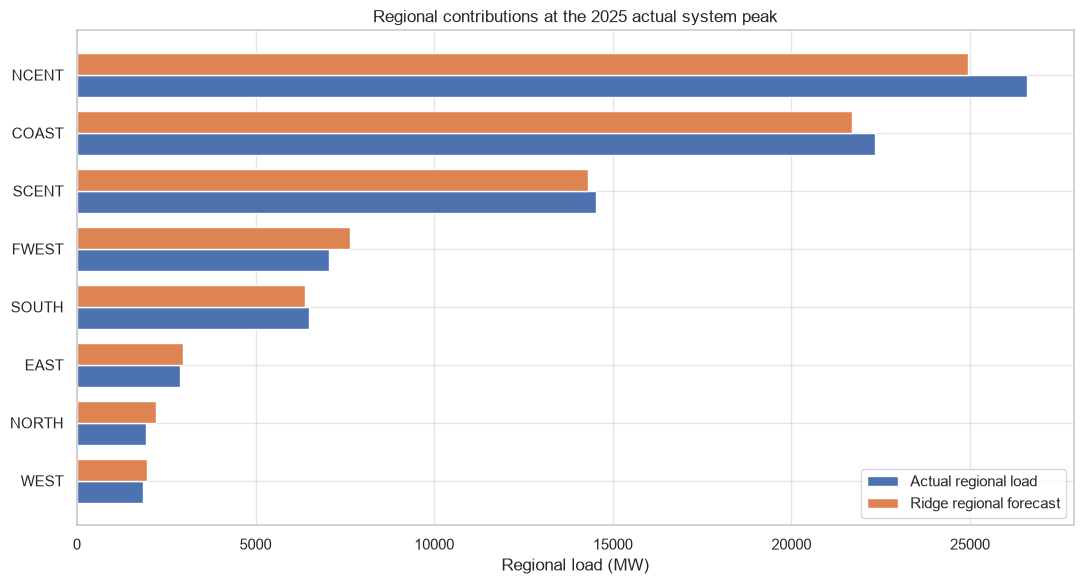


Files written in 06.17:


,filename,rows,size_bytes,path
0,06_17_system_peak_regional_contributions.csv,40,7500,/report/tables/peak_uncertainty/06_17_system_peak_regional_contributions.csv
1,06_17_actual_system_peak_regional_contributions.csv,8,1676,/report/tables/peak_uncertainty/06_17_actual_system_peak_regional_contributions.csv
2,06_17_regional_annual_peaks.csv,8,1817,/report/tables/peak_uncertainty/06_17_regional_annual_peaks.csv


In [ ]:

# ============================================================
# ============================================================

# ------------------------------------------------------------
# ------------------------------------------------------------
def extract_regional_contributions(
    regional_frame,
    timestamp_utc,
    scenario_name,
):
    contributions = (
        regional_frame.loc[
            regional_frame[
                "timestamp_utc"
            ].eq(timestamp_utc),
            [
                "timestamp_utc",
                "zone",
                "actual_mw",
                "forecast_mw",
            ],
        ]
        .copy()
    )

    if len(contributions) != 8:
        raise ValueError(
            f"{scenario_name} timestamp does not contain all eight zones:"
            f"{len(contributions)}"
        )

    contributions.insert(
        0,
        "scenario",
        scenario_name,
    )

    contributions[
        "residual_mw"
    ] = (
        contributions["actual_mw"]
        - contributions["forecast_mw"]
    )

    actual_system_total = float(
        contributions["actual_mw"].sum()
    )

    forecast_system_total = float(
        contributions["forecast_mw"].sum()
    )

    contributions[
        "actual_system_total_mw"
    ] = actual_system_total

    contributions[
        "forecast_system_total_mw"
    ] = forecast_system_total

    contributions[
        "actual_contribution_pct"
    ] = (
        contributions["actual_mw"]
        / actual_system_total
        * 100
    )

    contributions[
        "forecast_contribution_pct"
    ] = (
        contributions["forecast_mw"]
        / forecast_system_total
        * 100
    )

    total_underforecast = (
        contributions.loc[
            contributions[
                "residual_mw"
            ].gt(0),
            "residual_mw",
        ].sum()
    )

    contributions[
        "share_of_positive_residual_pct"
    ] = np.where(
        contributions[
            "residual_mw"
        ].gt(0)
        & (total_underforecast > 0),

        contributions[
            "residual_mw"
        ]
        / total_underforecast
        * 100,

        0.0,
    )

    return (
        contributions
        .sort_values(
            "actual_mw",
            ascending=False,
        )
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# ------------------------------------------------------------
actual_peak_timestamp = (
    system_2025_hybrid.loc[
        system_2025_hybrid[
            "actual_mw"
        ].idxmax(),
        "timestamp_utc",
    ]
)

raw_peak_timestamp = (
    system_2025_hybrid.loc[
        system_2025_hybrid[
            "forecast_mw"
        ].idxmax(),
        "timestamp_utc",
    ]
)

p50_peak_timestamp = (
    system_2025_hybrid.loc[
        system_2025_hybrid[
            "hybrid_p50_forecast_mw"
        ].idxmax(),
        "timestamp_utc",
    ]
)

p90_peak_timestamp = (
    system_2025_hybrid.loc[
        system_2025_hybrid[
            "hybrid_p90_forecast_mw"
        ].idxmax(),
        "timestamp_utc",
    ]
)

p95_peak_timestamp = (
    system_2025_hybrid.loc[
        system_2025_hybrid[
            "hybrid_p95_forecast_mw"
        ].idxmax(),
        "timestamp_utc",
    ]
)

peak_scenarios = {
    "Actual annual system peak":
        actual_peak_timestamp,

    "Raw Ridge annual peak":
        raw_peak_timestamp,

    "Hybrid P50 curve peak":
        p50_peak_timestamp,

    "Hybrid P90 curve peak":
        p90_peak_timestamp,

    "Hybrid P95 curve peak":
        p95_peak_timestamp,
}

print("Key system-peak timestamps:")

for scenario_name, timestamp in (
    peak_scenarios.items()
):
    print(
        f"{scenario_name}: {timestamp}"
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
regional_contribution_frames = []

for scenario_name, timestamp in (
    peak_scenarios.items()
):
    regional_contribution_frames.append(
        extract_regional_contributions(
            regional_2025_std,
            timestamp,
            scenario_name,
        )
    )

regional_peak_contributions = pd.concat(
    regional_contribution_frames,
    ignore_index=True,
)

# ------------------------------------------------------------
# ------------------------------------------------------------
actual_peak_regional_contributions = (
    regional_peak_contributions.loc[
        regional_peak_contributions[
            "scenario"
        ].eq(
            "Actual annual system peak"
        )
    ]
    .sort_values(
        "actual_mw",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("\nRegional contributions at the actual system-peak timestamp:")
display(
    actual_peak_regional_contributions[
        [
            "zone",
            "actual_mw",
            "actual_contribution_pct",
            "forecast_mw",
            "residual_mw",
            "share_of_positive_residual_pct",
        ]
    ].round(2)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
def summarize_regional_annual_peaks(
    regional_frame,
    system_peak_timestamp,
):
    records = []

    for zone_name, zone_data in (
        regional_frame.groupby("zone")
    ):
        actual_peak_row = zone_data.loc[
            zone_data[
                "actual_mw"
            ].idxmax()
        ]

        forecast_peak_row = zone_data.loc[
            zone_data[
                "forecast_mw"
            ].idxmax()
        ]

        system_peak_row = zone_data.loc[
            zone_data[
                "timestamp_utc"
            ].eq(system_peak_timestamp)
        ].iloc[0]

        actual_peak_mw = float(
            actual_peak_row[
                "actual_mw"
            ]
        )

        forecast_peak_mw = float(
            forecast_peak_row[
                "forecast_mw"
            ]
        )

        timing_difference_hours = (
            (
                forecast_peak_row[
                    "timestamp_utc"
                ]
                - actual_peak_row[
                    "timestamp_utc"
                ]
            )
            .total_seconds()
            / 3600
        )

        records.append(
            {
                "zone": zone_name,

                "actual_regional_peak_mw":
                    actual_peak_mw,

                "actual_regional_peak_utc":
                    actual_peak_row[
                        "timestamp_utc"
                    ],

                "forecast_regional_peak_mw":
                    forecast_peak_mw,

                "forecast_regional_peak_utc":
                    forecast_peak_row[
                        "timestamp_utc"
                    ],

                "regional_peak_error_mw": (
                    forecast_peak_mw
                    - actual_peak_mw
                ),

                "regional_peak_absolute_error_mw":
                    abs(
                        forecast_peak_mw
                        - actual_peak_mw
                    ),

                "regional_peak_timing_error_hours":
                    timing_difference_hours,

                "actual_load_at_system_peak_mw":
                    float(
                        system_peak_row[
                            "actual_mw"
                        ]
                    ),

                "forecast_at_system_peak_mw":
                    float(
                        system_peak_row[
                            "forecast_mw"
                        ]
                    ),

                "residual_at_system_peak_mw": (
                    float(
                        system_peak_row[
                            "actual_mw"
                        ]
                    )
                    - float(
                        system_peak_row[
                            "forecast_mw"
                        ]
                    )
                ),

                "regional_peak_coincides_with_system_peak":
                    bool(
                        actual_peak_row[
                            "timestamp_utc"
                        ]
                        == system_peak_timestamp
                    ),
            }
        )

    return (
        pd.DataFrame(records)
        .sort_values(
            "actual_regional_peak_mw",
            ascending=False,
        )
        .reset_index(drop=True)
    )


regional_annual_peaks_2025 = (
    summarize_regional_annual_peaks(
        regional_2025_std,
        actual_peak_timestamp,
    )
)

print("\n2025 regional annual peaks:")
display(
    regional_annual_peaks_2025[
        [
            "zone",
            "actual_regional_peak_mw",
            "forecast_regional_peak_mw",
            "regional_peak_error_mw",
            "regional_peak_timing_error_hours",
            "actual_load_at_system_peak_mw",
            "residual_at_system_peak_mw",
            "regional_peak_coincides_with_system_peak",
        ]
    ].round(1)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
plot_data = (
    actual_peak_regional_contributions
    .sort_values(
        "actual_mw",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6),
)

y_positions = np.arange(
    len(plot_data)
)

bar_height = 0.38

ax.barh(
    y_positions - bar_height / 2,
    plot_data["actual_mw"],
    height=bar_height,
    label="Actual regional load",
)

ax.barh(
    y_positions + bar_height / 2,
    plot_data["forecast_mw"],
    height=bar_height,
    label="Ridge regional forecast",
)

ax.set_yticks(
    y_positions,
    plot_data["zone"],
)

ax.set_xlabel("Regional load (MW)")
ax.set_title(
    "Regional contributions at the 2025 actual system peak"
)
ax.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_17 = {
    "06_17_system_peak_regional_contributions.csv":
        regional_peak_contributions,

    "06_17_actual_system_peak_regional_contributions.csv":
        actual_peak_regional_contributions,

    "06_17_regional_annual_peaks.csv":
        regional_annual_peaks_2025,
}

saved_06_17_records = []

for filename, table in outputs_06_17.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_17_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_17 = pd.DataFrame(
    saved_06_17_records
)

print("\nFiles written in 06.17:")
display(saved_06_17)

**Coincidence matters.** None of the eight zones' separate annual maxima coincided exactly with the system annual peak. Summing independent regional peak estimates (including independent regional P95 values) would overstate simultaneous system demand. Instead, allocate the system-level planning scenario using historically adjusted regional shares **at the system peak**.

## 06.18 — Allocate system-level peak scenarios across eight zones

Estimate regional-share bias at forecast system-peak timestamps using 2023–2024 validation records. Correct the raw 2025 Ridge regional shares, allocate system Bootstrap P50/P90/P95 across zones, and verify that regional allocations sum to their corresponding system totals.

## 06.18a — Calibrated regional-share allocation

Estimate historical regional-share biases at the predicted system peak, allocate the final system scenarios proportionally across zones, and audit that allocations reconcile to system totals.

Historical 2023–2024 regional-share bias at predicted system peaks:


,zone,historical_peak_years,mean_actual_share_pct,mean_forecast_share_pct,mean_share_bias_pct_point
0,COAST,2,26.772,26.907,-0.135
1,EAST,2,3.569,3.590,-0.020
2,FWEST,2,7.208,7.499,-0.290
3,NCENT,2,32.433,32.283,0.150
4,NORTH,2,2.489,2.479,0.010
5,SCENT,2,17.495,17.192,0.303
6,SOUTH,2,7.513,7.520,-0.007
7,WEST,2,2.521,2.531,-0.010



Regional capacity-allocation integrity checks:
calibrated_share_sum        1.000
allocated_raw_sum_mw    82561.530
allocated_p50_sum_mw    84782.949
allocated_p90_sum_mw    85646.229
allocated_p95_sum_mw    85938.352
allocated_p99_sum_mw    86937.130

2025 coincident regional capacity-planning allocation:


,zone,raw_forecast_share,mean_share_bias,calibrated_peak_share_pct,actual_share_at_system_peak_pct,share_backtest_error_pct_point,allocated_p50_peak_mw,allocated_p90_peak_mw,allocated_p95_peak_mw,allocated_p99_peak_mw
0,NCENT,0.30,0.0,30.22,31.77,-1.54,25623.00,25883.90,25972.18,26274.03
1,COAST,0.27,-0.0,26.79,26.71,0.08,22710.37,22941.62,23019.87,23287.40
2,SCENT,0.17,0.0,17.49,17.35,0.14,14829.22,14980.21,15031.30,15206.00
3,FWEST,0.09,-0.0,9.10,8.42,0.68,7712.05,7790.57,7817.14,7907.99
4,SOUTH,0.08,-0.0,7.72,7.78,-0.06,6547.25,6613.92,6636.48,6713.61
5,EAST,0.04,-0.0,3.57,3.45,0.12,3026.80,3057.62,3068.05,3103.71
6,NORTH,0.03,0.0,2.75,2.32,0.43,2329.93,2353.65,2361.68,2389.12
7,WEST,0.02,-0.0,2.36,2.20,0.16,2004.33,2024.74,2031.65,2055.26


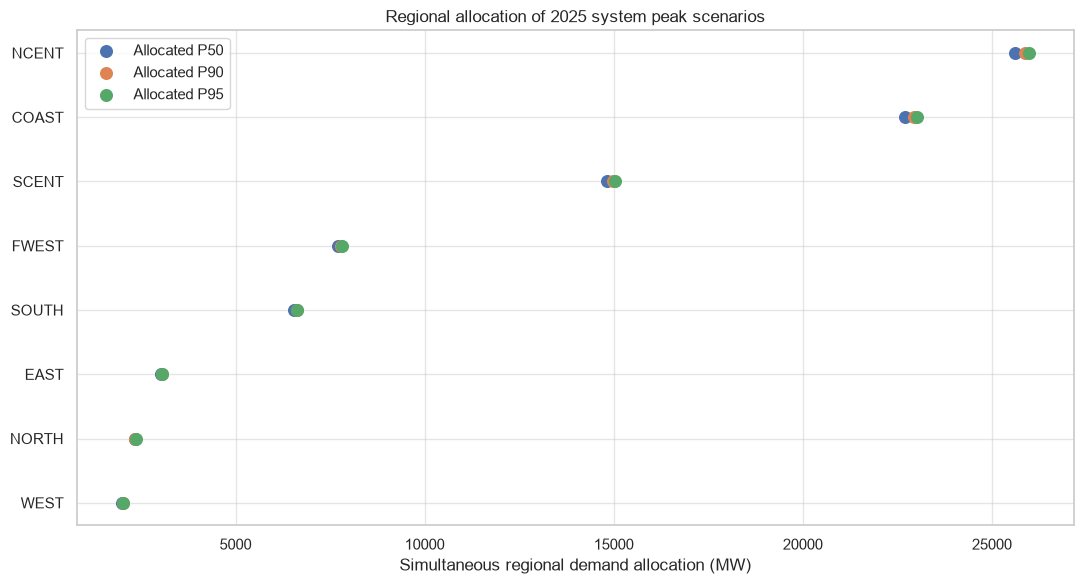


Files written in 06.18:


,filename,rows,size_bytes,path
0,06_18_historical_peak_share_detail.csv,16,4374,/report/tables/peak_uncertainty/06_18_historical_peak_share_detail.csv
1,06_18_historical_peak_share_bias.csv,8,1031,/report/tables/peak_uncertainty/06_18_historical_peak_share_bias.csv
2,06_18_regional_capacity_allocation.csv,8,3071,/report/tables/peak_uncertainty/06_18_regional_capacity_allocation.csv


In [ ]:
# ============================================================
# ============================================================

# ------------------------------------------------------------
# ------------------------------------------------------------
def estimate_peak_share_bias(
    historical_regional_frame,
):
    system_forecast_by_hour = (
        historical_regional_frame
        .groupby(
            [
                "validation_year",
                "timestamp_utc",
            ],
            as_index=False,
        )
        .agg(
            actual_system_mw=(
                "load_mw",
                "sum",
            ),

            forecast_system_mw=(
                "forecast_mw",
                "sum",
            ),
        )
    )

    peak_timestamps = (
        system_forecast_by_hour.loc[
            system_forecast_by_hour
            .groupby(
                "validation_year"
            )[
                "forecast_system_mw"
            ]
            .idxmax(),
            [
                "validation_year",
                "timestamp_utc",
            ],
        ]
    )

    peak_regional_rows = (
        historical_regional_frame.merge(
            peak_timestamps,
            on=[
                "validation_year",
                "timestamp_utc",
            ],
            how="inner",
            validate="many_to_one",
        )
    )

    peak_regional_rows[
        "actual_system_total_mw"
    ] = (
        peak_regional_rows.groupby(
            "validation_year"
        )["load_mw"].transform("sum")
    )

    peak_regional_rows[
        "forecast_system_total_mw"
    ] = (
        peak_regional_rows.groupby(
            "validation_year"
        )["forecast_mw"].transform("sum")
    )

    peak_regional_rows[
        "actual_share"
    ] = (
        peak_regional_rows["load_mw"]
        / peak_regional_rows[
            "actual_system_total_mw"
        ]
    )

    peak_regional_rows[
        "forecast_share"
    ] = (
        peak_regional_rows["forecast_mw"]
        / peak_regional_rows[
            "forecast_system_total_mw"
        ]
    )

    peak_regional_rows[
        "share_bias"
    ] = (
        peak_regional_rows[
            "actual_share"
        ]
        - peak_regional_rows[
            "forecast_share"
        ]
    )

    share_bias_summary = (
        peak_regional_rows
        .groupby("zone")
        .agg(
            historical_peak_years=(
                "validation_year",
                "nunique",
            ),

            mean_actual_share=(
                "actual_share",
                "mean",
            ),

            mean_forecast_share=(
                "forecast_share",
                "mean",
            ),

            mean_share_bias=(
                "share_bias",
                "mean",
            ),

            min_share_bias=(
                "share_bias",
                "min",
            ),

            max_share_bias=(
                "share_bias",
                "max",
            ),
        )
        .reset_index()
    )

    return (
        peak_regional_rows,
        share_bias_summary,
    )


(
    historical_peak_share_detail,
    historical_peak_share_bias,
) = estimate_peak_share_bias(
    historical_regional
)

print("Historical 2023–2024 regional-share bias at predicted system peaks:")
display(
    historical_peak_share_bias.assign(
        mean_actual_share_pct=lambda frame:
            frame["mean_actual_share"] * 100,

        mean_forecast_share_pct=lambda frame:
            frame["mean_forecast_share"] * 100,

        mean_share_bias_pct_point=lambda frame:
            frame["mean_share_bias"] * 100,
    )[
        [
            "zone",
            "historical_peak_years",
            "mean_actual_share_pct",
            "mean_forecast_share_pct",
            "mean_share_bias_pct_point",
        ]
    ].round(3)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
regional_at_2025_raw_peak = (
    regional_2025_std.loc[
        regional_2025_std[
            "timestamp_utc"
        ].eq(raw_peak_timestamp)
    ]
    .copy()
)

if len(regional_at_2025_raw_peak) != 8:
    raise ValueError(
        "Incomplete eight-zone observations at the 2025 raw system peak."
    )

regional_at_2025_raw_peak[
    "raw_forecast_share"
] = (
    regional_at_2025_raw_peak[
        "forecast_mw"
    ]
    / regional_at_2025_raw_peak[
        "forecast_mw"
    ].sum()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
regional_capacity_allocation = (
    regional_at_2025_raw_peak[
        [
            "timestamp_utc",
            "zone",
            "forecast_mw",
            "raw_forecast_share",
        ]
    ]
    .merge(
        historical_peak_share_bias[
            [
                "zone",
                "mean_share_bias",
            ]
        ],
        on="zone",
        how="left",
        validate="one_to_one",
    )
)

regional_capacity_allocation[
    "uncorrected_share"
] = (
    regional_capacity_allocation[
        "raw_forecast_share"
    ]
    + regional_capacity_allocation[
        "mean_share_bias"
    ]
)

regional_capacity_allocation[
    "uncorrected_share"
] = (
    regional_capacity_allocation[
        "uncorrected_share"
    ].clip(lower=0)
)

regional_capacity_allocation[
    "calibrated_peak_share"
] = (
    regional_capacity_allocation[
        "uncorrected_share"
    ]
    / regional_capacity_allocation[
        "uncorrected_share"
    ].sum()
)

# ------------------------------------------------------------
# ------------------------------------------------------------
def allocate_system_scenarios(
    allocation_table,
    system_planning_row,
):
    result = allocation_table.copy()

    scenario_columns = {
        "allocated_raw_peak_mw":
            "raw_forecast_peak_mw",

        "allocated_p50_peak_mw":
            "bootstrap_peak_p50_mw",

        "allocated_p90_peak_mw":
            "bootstrap_peak_p90_mw",

        "allocated_p95_peak_mw":
            "bootstrap_peak_p95_mw",

        "allocated_p99_peak_mw":
            "bootstrap_peak_p99_mw",
    }

    for output_column, system_column in (
        scenario_columns.items()
    ):
        system_total = float(
            system_planning_row[
                system_column
            ]
        )

        result[output_column] = (
            result[
                "calibrated_peak_share"
            ]
            * system_total
        )

    return result


regional_capacity_allocation = (
    allocate_system_scenarios(
        regional_capacity_allocation,
        final_annual_planning.iloc[0],
    )
)

# ------------------------------------------------------------
# ------------------------------------------------------------
actual_peak_evaluation = (
    actual_peak_regional_contributions[
        [
            "zone",
            "actual_mw",
            "actual_contribution_pct",
        ]
    ]
    .rename(
        columns={
            "actual_mw":
                "actual_load_at_system_peak_mw",

            "actual_contribution_pct":
                "actual_share_at_system_peak_pct",
        }
    )
)

regional_capacity_allocation = (
    regional_capacity_allocation.merge(
        actual_peak_evaluation,
        on="zone",
        how="left",
        validate="one_to_one",
    )
)

regional_capacity_allocation[
    "calibrated_peak_share_pct"
] = (
    regional_capacity_allocation[
        "calibrated_peak_share"
    ]
    * 100
)

regional_capacity_allocation[
    "share_backtest_error_pct_point"
] = (
    regional_capacity_allocation[
        "calibrated_peak_share_pct"
    ]
    - regional_capacity_allocation[
        "actual_share_at_system_peak_pct"
    ]
)

# ------------------------------------------------------------
# ------------------------------------------------------------
regional_capacity_allocation = (
    regional_capacity_allocation.merge(
        regional_annual_peaks_2025[
            [
                "zone",
                "actual_regional_peak_mw",
                "forecast_regional_peak_mw",
                "regional_peak_coincides_with_system_peak",
            ]
        ],
        on="zone",
        how="left",
        validate="one_to_one",
    )
)

regional_capacity_allocation = (
    regional_capacity_allocation
    .sort_values(
        "allocated_p95_peak_mw",
        ascending=False,
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
allocation_check = pd.Series(
    {
        "calibrated_share_sum":
            regional_capacity_allocation[
                "calibrated_peak_share"
            ].sum(),

        "allocated_raw_sum_mw":
            regional_capacity_allocation[
                "allocated_raw_peak_mw"
            ].sum(),

        "allocated_p50_sum_mw":
            regional_capacity_allocation[
                "allocated_p50_peak_mw"
            ].sum(),

        "allocated_p90_sum_mw":
            regional_capacity_allocation[
                "allocated_p90_peak_mw"
            ].sum(),

        "allocated_p95_sum_mw":
            regional_capacity_allocation[
                "allocated_p95_peak_mw"
            ].sum(),

        "allocated_p99_sum_mw":
            regional_capacity_allocation[
                "allocated_p99_peak_mw"
            ].sum(),
    },
    name="value",
)

print("\nRegional capacity-allocation integrity checks:")
print(
    allocation_check.round(3).to_string()
)

print("\n2025 coincident regional capacity-planning allocation:")
display(
    regional_capacity_allocation[
        [
            "zone",
            "raw_forecast_share",
            "mean_share_bias",
            "calibrated_peak_share_pct",
            "actual_share_at_system_peak_pct",
            "share_backtest_error_pct_point",
            "allocated_p50_peak_mw",
            "allocated_p90_peak_mw",
            "allocated_p95_peak_mw",
            "allocated_p99_peak_mw",
        ]
    ].round(2)
)

# ------------------------------------------------------------
# ------------------------------------------------------------
plot_allocation = (
    regional_capacity_allocation
    .sort_values(
        "allocated_p95_peak_mw",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6),
)

y_positions = np.arange(
    len(plot_allocation)
)

ax.scatter(
    plot_allocation[
        "allocated_p50_peak_mw"
    ],
    y_positions,
    label="Allocated P50",
    s=70,
)

ax.scatter(
    plot_allocation[
        "allocated_p90_peak_mw"
    ],
    y_positions,
    label="Allocated P90",
    s=70,
)

ax.scatter(
    plot_allocation[
        "allocated_p95_peak_mw"
    ],
    y_positions,
    label="Allocated P95",
    s=70,
)

ax.set_yticks(
    y_positions,
    plot_allocation["zone"],
)

ax.set_xlabel(
    "Simultaneous regional demand allocation (MW)"
)

ax.set_title(
    "Regional allocation of 2025 system peak scenarios"
)

ax.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# ------------------------------------------------------------
outputs_06_18 = {
    "06_18_historical_peak_share_detail.csv":
        historical_peak_share_detail,

    "06_18_historical_peak_share_bias.csv":
        historical_peak_share_bias,

    "06_18_regional_capacity_allocation.csv":
        regional_capacity_allocation,
}

saved_06_18_records = []

for filename, table in outputs_06_18.items():
    output_path = (
        UNCERTAINTY_OUTPUT_DIR / filename
    )

    table.to_csv(
        output_path,
        index=False,
    )

    saved_06_18_records.append(
        {
            "filename": filename,
            "rows": len(table),
            "size_bytes":
                output_path.stat().st_size,
            "path": str(output_path),
        }
    )

saved_06_18 = pd.DataFrame(
    saved_06_18_records
)

print("\nFiles written in 06.18:")
display(saved_06_18)

The regional table represents **simultaneous load at the system peak**, not the sum of separate regional annual peaks. Stage 07 should use synchronized allocation when examining regional contributions, avoiding double counting noncoincident maxima.

**Regional allocation interpretation.** Historical share corrections were small (at most about **0.30 percentage points**). Allocated coincident P95 demand was largest for **NCENT (25.97 GW)**, **COAST (23.02 GW)**, and **SCENT (15.03 GW)**. However, NCENT's observed share at the actual system peak was **1.54 percentage points** above the calibrated allocation. The shares are useful for allocating a system-level scenario, **not** a zone-specific reliability guarantee. Final QA follows.

## 06.19 — Final quality assurance and artifact inventory

Check input completeness, quantile ordering, regional allocation consistency, and the saved table and figure inventory. Results are from the original project execution, not a new end-to-end reproduction.

Final quality assurance checks:


,check,passed,observed,expected
0,Historical system rows = 17544,True,17544.000000,17544.000000
1,Historical regional rows = 140352,True,140352.000000,140352.000000
2,2025 system rows = 8760,True,8760.000000,8760.000000
3,2025 regional rows = 70080,True,70080.000000,70080.000000
4,No P50 > P90 violations,True,0.000000,0.000000
5,No P90 > P95 violations,True,0.000000,0.000000
6,Regional shares sum to 1,True,1.000000,1.000000
7,Regional P50 sums to system P50,True,84782.949201,84782.949201
8,Regional P90 sums to system P90,True,85646.229475,85646.229475
9,Regional P95 sums to system P95,True,85938.352071,85938.352071


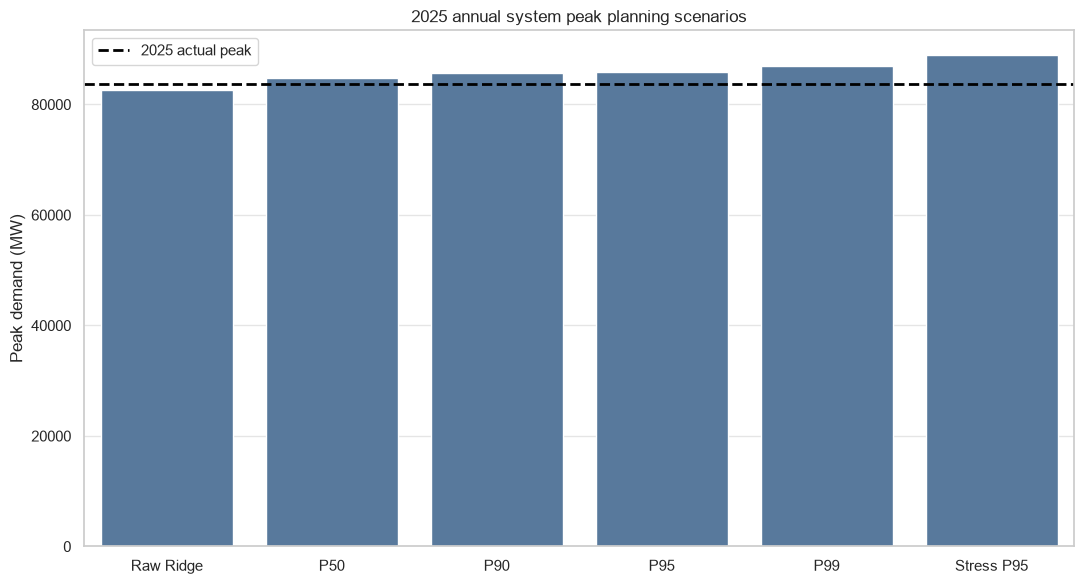

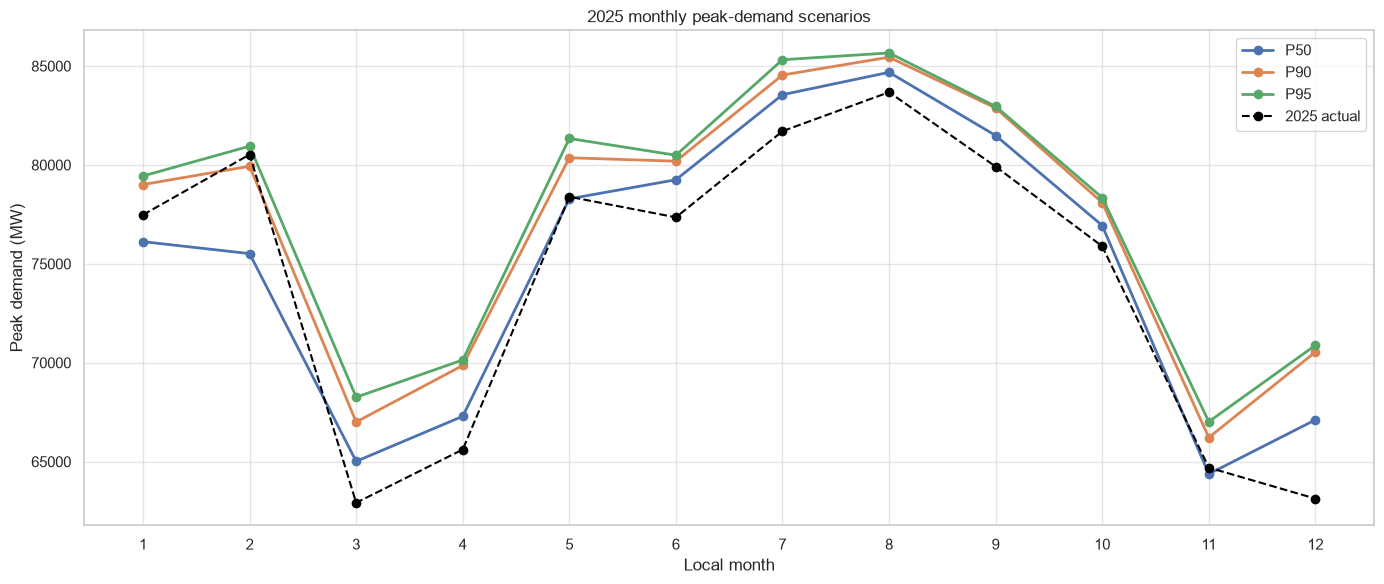

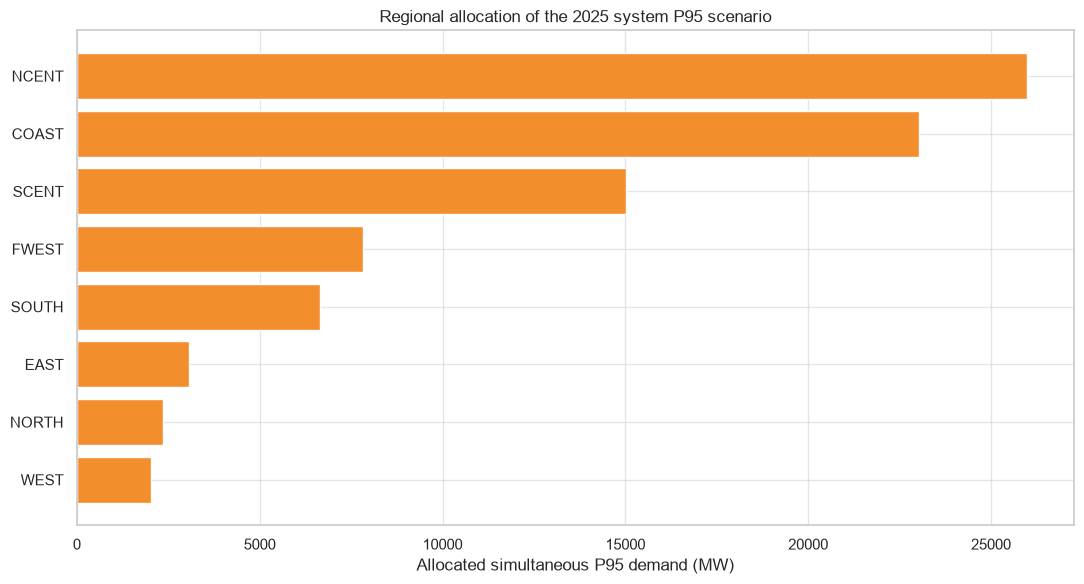


Final methodology summary:


,component,selected_method,calibration_data,purpose
0,Hourly point forecast,"Eight regional Ridge models, alpha=100",2019–2024 training; 2025 test,Raw hourly system and regional load forecast
1,P50 hourly calibration,Annual forecast-decile empirical residual median,2023–2024 out-of-sample residuals,Bias-corrected central hourly forecast
2,Winter and Autumn P90/P95,Seasonal forecast-decile empirical residual quantiles,2023–2024 out-of-sample residuals,Season-sensitive upper hourly bounds
3,Spring and Summer P90/P95,Annual forecast-decile empirical residual quantiles,2023–2024 out-of-sample residuals,Stable high-load upper hourly bounds
4,Peak probability distribution,Season and daily-peak-quintile conditioned daily-block bootstrap,2023–2024 daily residual blocks,"Annual, seasonal and monthly peak P50/P90/P95/P99"
5,Stress test,Independent conditional hourly residual bootstrap,2023–2024 residuals,Conservative extreme-risk scenario only
6,Regional allocation,Historically calibrated simultaneous peak shares,2023–2024 forecast-peak regional shares,Allocate system planning scenarios without summing noncoincident peaks



Final key metrics:


,metric,value_mw,interpretation,value_gw
0,2025 actual annual peak,83679.002,Backtest reference only,83.679
1,Raw Ridge annual peak,82561.530,Uncalibrated point forecast,82.562
2,Daily-block bootstrap P50,84782.949,Central capacity-demand scenario,84.783
3,Daily-block bootstrap P90,85646.229,Reliability-planning scenario,85.646
4,Daily-block bootstrap P95,85938.352,Conservative capacity scenario,85.938
5,Daily-block bootstrap P99,86937.130,Severe peak scenario,86.937
6,Independent-hour stress P95,88947.504,"Extreme stress test, not base planning",88.948



Stage 06 output inventory:


,artifact_type,filename,size_bytes,path
0,table,06_07_d10_by_season.csv,672,/report/tables/peak_uncertainty/06_07_d10_by_season.csv
1,table,06_07_d10_season_year_stability.csv,749,/report/tables/peak_uncertainty/06_07_d10_season_year_stability.csv
2,table,06_07_residual_by_tail_band.csv,981,/report/tables/peak_uncertainty/06_07_residual_by_tail_band.csv
3,table,06_08_calibration_lookup_2023.csv,1264,/report/tables/peak_uncertainty/06_08_calibration_lookup_2023.csv
4,table,06_08_coverage_backtest_2024.csv,3506,/report/tables/peak_uncertainty/06_08_coverage_backtest_2024.csv
5,table,06_08_peak_backtest_2024.csv,920,/report/tables/peak_uncertainty/06_08_peak_backtest_2024.csv
6,table,06_09_2025_annual_peak_backtest.csv,432,/report/tables/peak_uncertainty/06_09_2025_annual_peak_backtest.csv
7,table,06_09_2025_coverage_backtest.csv,1162,/report/tables/peak_uncertainty/06_09_2025_coverage_backtest.csv
8,table,06_09_2025_hourly_calibrated_forecasts.csv,2450657,/report/tables/peak_uncertainty/06_09_2025_hourly_calibrated_forecasts.csv
9,table,06_09_final_decile_calibration.csv,1718,/report/tables/peak_uncertainty/06_09_final_decile_calibration.csv



Stage 06 final tables and figures were saved successfully.


In [ ]:

# ============================================================
# ============================================================

# ------------------------------------------------------------
# ------------------------------------------------------------
def check_close(
    actual_value,
    expected_value,
    tolerance=1e-6,
):
    return bool(
        np.isclose(
            actual_value,
            expected_value,
            atol=tolerance,
            rtol=0,
        )
    )


# ------------------------------------------------------------
# ------------------------------------------------------------
final_methodology_summary = pd.DataFrame(
    [
        {
            "component":
                "Hourly point forecast",
            "selected_method":
                "Eight regional Ridge models, alpha=100",
            "calibration_data":
                "2019–2024 training; 2025 test",
            "purpose":
                "Raw hourly system and regional load forecast",
        },
        {
            "component":
                "P50 hourly calibration",
            "selected_method":
                "Annual forecast-decile empirical residual median",
            "calibration_data":
                "2023–2024 out-of-sample residuals",
            "purpose":
                "Bias-corrected central hourly forecast",
        },
        {
            "component":
                "Winter and Autumn P90/P95",
            "selected_method":
                "Seasonal forecast-decile empirical residual quantiles",
            "calibration_data":
                "2023–2024 out-of-sample residuals",
            "purpose":
                "Season-sensitive upper hourly bounds",
        },
        {
            "component":
                "Spring and Summer P90/P95",
            "selected_method":
                "Annual forecast-decile empirical residual quantiles",
            "calibration_data":
                "2023–2024 out-of-sample residuals",
            "purpose":
                "Stable high-load upper hourly bounds",
        },
        {
            "component":
                "Peak probability distribution",
            "selected_method":
                "Season and daily-peak-quintile conditioned daily-block bootstrap",
            "calibration_data":
                "2023–2024 daily residual blocks",
            "purpose":
                "Annual, seasonal and monthly peak P50/P90/P95/P99",
        },
        {
            "component":
                "Stress test",
            "selected_method":
                "Independent conditional hourly residual bootstrap",
            "calibration_data":
                "2023–2024 residuals",
            "purpose":
                "Conservative extreme-risk scenario only",
        },
        {
            "component":
                "Regional allocation",
            "selected_method":
                "Historically calibrated simultaneous peak shares",
            "calibration_data":
                "2023–2024 forecast-peak regional shares",
            "purpose":
                "Allocate system planning scenarios without summing noncoincident peaks",
        },
    ]
)

# ------------------------------------------------------------
# ------------------------------------------------------------
annual_row = final_annual_planning.iloc[0]

final_key_metrics = pd.DataFrame(
    [
        {
            "metric":
                "2025 actual annual peak",
            "value_mw":
                annual_row["actual_peak_mw"],
            "interpretation":
                "Backtest reference only",
        },
        {
            "metric":
                "Raw Ridge annual peak",
            "value_mw":
                annual_row[
                    "raw_forecast_peak_mw"
                ],
            "interpretation":
                "Uncalibrated point forecast",
        },
        {
            "metric":
                "Daily-block bootstrap P50",
            "value_mw":
                annual_row[
                    "bootstrap_peak_p50_mw"
                ],
            "interpretation":
                "Central capacity-demand scenario",
        },
        {
            "metric":
                "Daily-block bootstrap P90",
            "value_mw":
                annual_row[
                    "bootstrap_peak_p90_mw"
                ],
            "interpretation":
                "Reliability-planning scenario",
        },
        {
            "metric":
                "Daily-block bootstrap P95",
            "value_mw":
                annual_row[
                    "bootstrap_peak_p95_mw"
                ],
            "interpretation":
                "Conservative capacity scenario",
        },
        {
            "metric":
                "Daily-block bootstrap P99",
            "value_mw":
                annual_row[
                    "bootstrap_peak_p99_mw"
                ],
            "interpretation":
                "Severe peak scenario",
        },
        {
            "metric":
                "Independent-hour stress P95",
            "value_mw":
                annual_row[
                    "independent_hour_stress_p95_mw"
                ],
            "interpretation":
                "Extreme stress test, not base planning",
        },
    ]
)

# ------------------------------------------------------------
# ------------------------------------------------------------
final_qa_checks = pd.DataFrame(
    [
        {
            "check":
                "Historical system rows = 17544",
            "passed":
                len(historical_system) == 17544,
            "observed":
                len(historical_system),
            "expected":
                17544,
        },
        {
            "check":
                "Historical regional rows = 140352",
            "passed":
                len(historical_regional) == 140352,
            "observed":
                len(historical_regional),
            "expected":
                140352,
        },
        {
            "check":
                "2025 system rows = 8760",
            "passed":
                len(system_2025_hybrid) == 8760,
            "observed":
                len(system_2025_hybrid),
            "expected":
                8760,
        },
        {
            "check":
                "2025 regional rows = 70080",
            "passed":
                len(regional_2025_std) == 70080,
            "observed":
                len(regional_2025_std),
            "expected":
                70080,
        },
        {
            "check":
                "No P50 > P90 violations",
            "passed":
                int(
                    (
                        system_2025_hybrid[
                            "hybrid_p50_forecast_mw"
                        ]
                        > system_2025_hybrid[
                            "hybrid_p90_forecast_mw"
                        ]
                    ).sum()
                ) == 0,
            "observed":
                int(
                    (
                        system_2025_hybrid[
                            "hybrid_p50_forecast_mw"
                        ]
                        > system_2025_hybrid[
                            "hybrid_p90_forecast_mw"
                        ]
                    ).sum()
                ),
            "expected":
                0,
        },
        {
            "check":
                "No P90 > P95 violations",
            "passed":
                int(
                    (
                        system_2025_hybrid[
                            "hybrid_p90_forecast_mw"
                        ]
                        > system_2025_hybrid[
                            "hybrid_p95_forecast_mw"
                        ]
                    ).sum()
                ) == 0,
            "observed":
                int(
                    (
                        system_2025_hybrid[
                            "hybrid_p90_forecast_mw"
                        ]
                        > system_2025_hybrid[
                            "hybrid_p95_forecast_mw"
                        ]
                    ).sum()
                ),
            "expected":
                0,
        },
        {
            "check":
                "Regional shares sum to 1",
            "passed":
                check_close(
                    regional_capacity_allocation[
                        "calibrated_peak_share"
                    ].sum(),
                    1.0,
                ),
            "observed":
                regional_capacity_allocation[
                    "calibrated_peak_share"
                ].sum(),
            "expected":
                1.0,
        },
        {
            "check":
                "Regional P50 sums to system P50",
            "passed":
                check_close(
                    regional_capacity_allocation[
                        "allocated_p50_peak_mw"
                    ].sum(),
                    annual_row[
                        "bootstrap_peak_p50_mw"
                    ],
                ),
            "observed":
                regional_capacity_allocation[
                    "allocated_p50_peak_mw"
                ].sum(),
            "expected":
                annual_row[
                    "bootstrap_peak_p50_mw"
                ],
        },
        {
            "check":
                "Regional P90 sums to system P90",
            "passed":
                check_close(
                    regional_capacity_allocation[
                        "allocated_p90_peak_mw"
                    ].sum(),
                    annual_row[
                        "bootstrap_peak_p90_mw"
                    ],
                ),
            "observed":
                regional_capacity_allocation[
                    "allocated_p90_peak_mw"
                ].sum(),
            "expected":
                annual_row[
                    "bootstrap_peak_p90_mw"
                ],
        },
        {
            "check":
                "Regional P95 sums to system P95",
            "passed":
                check_close(
                    regional_capacity_allocation[
                        "allocated_p95_peak_mw"
                    ].sum(),
                    annual_row[
                        "bootstrap_peak_p95_mw"
                    ],
                ),
            "observed":
                regional_capacity_allocation[
                    "allocated_p95_peak_mw"
                ].sum(),
            "expected":
                annual_row[
                    "bootstrap_peak_p95_mw"
                ],
        },
    ]
)

print("Final quality assurance checks:")
display(final_qa_checks)

if not final_qa_checks["passed"].all():
    failed_checks = final_qa_checks.loc[
        ~final_qa_checks["passed"],
        "check",
    ].tolist()

    raise RuntimeError(
        "The following final QA checks failed:"
        + "; ".join(failed_checks)
    )

# ------------------------------------------------------------
# ------------------------------------------------------------
final_methodology_path = (
    UNCERTAINTY_OUTPUT_DIR
    / "06_19_final_methodology_summary.csv"
)

final_metrics_path = (
    UNCERTAINTY_OUTPUT_DIR
    / "06_19_final_key_metrics.csv"
)

final_qa_path = (
    UNCERTAINTY_OUTPUT_DIR
    / "06_19_final_qa_checks.csv"
)

final_methodology_summary.to_csv(
    final_methodology_path,
    index=False,
)

final_key_metrics.to_csv(
    final_metrics_path,
    index=False,
)

final_qa_checks.to_csv(
    final_qa_path,
    index=False,
)

# ------------------------------------------------------------
# ------------------------------------------------------------
PEAK_FIGURE_DIR = (
    PROJECT_ROOT
    / "report"
    / "figures"
    / "peak_uncertainty"
)

PEAK_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ------------------------------------------------------------
# ------------------------------------------------------------
annual_scenario_plot = pd.DataFrame(
    {
        "scenario": [
            "Raw Ridge",
            "P50",
            "P90",
            "P95",
            "P99",
            "Stress P95",
        ],

        "peak_mw": [
            annual_row[
                "raw_forecast_peak_mw"
            ],
            annual_row[
                "bootstrap_peak_p50_mw"
            ],
            annual_row[
                "bootstrap_peak_p90_mw"
            ],
            annual_row[
                "bootstrap_peak_p95_mw"
            ],
            annual_row[
                "bootstrap_peak_p99_mw"
            ],
            annual_row[
                "independent_hour_stress_p95_mw"
            ],
        ],
    }
)

fig, ax = plt.subplots(
    figsize=(11, 6),
)

sns.barplot(
    data=annual_scenario_plot,
    x="scenario",
    y="peak_mw",
    ax=ax,
    color="#4C78A8",
)

ax.axhline(
    annual_row["actual_peak_mw"],
    color="black",
    linestyle="--",
    linewidth=2,
    label="2025 actual peak",
)

ax.set_title(
    "2025 annual system peak planning scenarios"
)
ax.set_xlabel("")
ax.set_ylabel("Peak demand (MW)")
ax.legend()

plt.tight_layout()

annual_figure_path = (
    PEAK_FIGURE_DIR
    / "annual_peak_planning_scenarios.png"
)

fig.savefig(
    annual_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(14, 6),
)

for column, label in [
    (
        "bootstrap_peak_p50_mw",
        "P50",
    ),
    (
        "bootstrap_peak_p90_mw",
        "P90",
    ),
    (
        "bootstrap_peak_p95_mw",
        "P95",
    ),
]:
    ax.plot(
        final_monthly_planning[
            "local_month"
        ],
        final_monthly_planning[column],
        marker="o",
        linewidth=2,
        label=label,
    )

ax.plot(
    final_monthly_planning[
        "local_month"
    ],
    final_monthly_planning[
        "actual_peak_mw"
    ],
    marker="o",
    color="black",
    linestyle="--",
    label="2025 actual",
)

ax.set_xticks(range(1, 13))
ax.set_xlabel("Local month")
ax.set_ylabel("Peak demand (MW)")
ax.set_title(
    "2025 monthly peak-demand scenarios"
)
ax.legend()

plt.tight_layout()

monthly_figure_path = (
    PEAK_FIGURE_DIR
    / "monthly_peak_planning_scenarios.png"
)

fig.savefig(
    monthly_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# ------------------------------------------------------------
regional_plot = (
    regional_capacity_allocation
    .sort_values(
        "allocated_p95_peak_mw",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6),
)

ax.barh(
    regional_plot["zone"],
    regional_plot[
        "allocated_p95_peak_mw"
    ],
    color="#F28E2B",
)

ax.set_xlabel(
    "Allocated simultaneous P95 demand (MW)"
)

ax.set_title(
    "Regional allocation of the 2025 system P95 scenario"
)

plt.tight_layout()

regional_figure_path = (
    PEAK_FIGURE_DIR
    / "regional_p95_capacity_allocation.png"
)

fig.savefig(
    regional_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# ------------------------------------------------------------
output_manifest_records = []

for path in sorted(
    UNCERTAINTY_OUTPUT_DIR.glob("*")
):
    if path.is_file():
        output_manifest_records.append(
            {
                "artifact_type": "table",
                "filename": path.name,
                "size_bytes":
                    path.stat().st_size,
                "path": str(path),
            }
        )

for path in sorted(
    PEAK_FIGURE_DIR.glob("*")
):
    if path.is_file():
        output_manifest_records.append(
            {
                "artifact_type": "figure",
                "filename": path.name,
                "size_bytes":
                    path.stat().st_size,
                "path": str(path),
            }
        )

final_output_manifest = pd.DataFrame(
    output_manifest_records
)

manifest_path = (
    UNCERTAINTY_OUTPUT_DIR
    / "06_19_output_manifest.csv"
)

final_output_manifest.to_csv(
    manifest_path,
    index=False,
)

print("\nFinal methodology summary:")
display(final_methodology_summary)

print("\nFinal key metrics:")
display(
    final_key_metrics.assign(
        value_gw=lambda frame:
            frame["value_mw"] / 1000
    ).round(3)
)

print("\nStage 06 output inventory:")
display(final_output_manifest)

print(
    "\nStage 06 final tables and figures "
    "were saved successfully."
)

**Stage 06 completion checks (saved historical run).** The original QA reported valid historical/system/zone row counts, complete 2025 inputs, ordered P50 ≤ P90 ≤ P95 scenarios, regional shares summing to 100%, and exact reconciliation of regional allocations with system-level scenarios. The main tables and report figures were written. These are results from the original saved execution; a clean-environment rerun has **not** been performed here.

# Stage 06 Results — Peak Forecasting and Uncertainty

## 1. Objective

Convert the Stage 05 hourly Ridge forecasts into peak-demand scenarios suitable for capacity planning. The focus is to address high-load underestimation and quantify annual, seasonal, and monthly peak uncertainty.

## 2. Leakage boundary and calibration data

Peak calibration and uncertainty parameters use only **2023–2024 out-of-sample validation residuals**:

- **2023:** predictions from a model trained on 2019–2022.
- **2024:** predictions from a model trained on 2019–2023.
- **2025:** held out for the final evaluation, not used for fitting the calibration lookup.

The historical calibration data contain **17,544 system-level hours** and **140,352 regional hours**, with no duplicate timestamps, missing critical fields, or incomplete regional-hour groups in the saved checks.

## 3. High-load residual behavior

Historical results reveal systematic underestimation at elevated forecast load:

- Average annual 2023–2024 WAPE: **3.331%**.
- Average forecast bias: **−398 MW**.
- Fraction of underestimated system hours: **59.35%**.
- Underestimation frequency in the highest forecast-load decile (D10): **81.4%**.
- Average D10 underestimation: approximately **1.49 GW**.
- D10 residual P90/P95: approximately **3.47 / 4.02 GW**.

A single global adjustment is therefore insufficient; corrections need to be conditioned on forecast level and, for some quantiles, season.

## 4. Hourly quantile calibration

Method selection used **2023 calibration and a 2024 temporal backtest**. The final hybrid method applies:

- **P50:** annual forecast-load decile residual median.
- **Winter and Autumn P90/P95:** within-season forecast-load decile residual quantiles.
- **Spring and Summer P90/P95:** annual forecast-load decile residual quantiles.

In the 2025 test subset with forecasts at or above historical P95, observed hourly coverage was approximately **90.6% for P90** and **96.6% for P95**. The hybrid method substantially reduced winter peak underestimation.

These are empirical hourly coverage measurements, **not** a guarantee that a future annual peak falls below a stated percentile.

## 5. Peak distribution via bootstrap

Independent hourly residual bootstrap can inflate the maximum across a long forecast sequence, so it is retained only as an extreme-stress sensitivity case.

The selected **conditional daily-block bootstrap**:

- Preserves the dependence structure of 24 hourly forecast errors within a day.
- Matches residual blocks by season and the forecast daily-peak quintile.
- Uses historical conditional pools containing about **34–37 days** each.
- Runs **5,000 simulations**.

## 6. 2025 annual system peak scenarios

| Scenario | Peak demand |
|---|---:|
| Observed 2025 peak (evaluation reference) | 83.68 GW |
| Raw Ridge point-forecast peak | 82.56 GW |
| Daily-block bootstrap P50 | 84.78 GW |
| Daily-block bootstrap P90 | 85.65 GW |
| Daily-block bootstrap P95 | 85.94 GW |
| Daily-block bootstrap P99 | 86.94 GW |
| Independent-hour stress-test P95 | 88.95 GW |

Relative to the raw Ridge annual maximum, planning demand increases by approximately **2.22 GW (P50)**, **3.08 GW (P90)**, **3.38 GW (P95)**, and **4.38 GW (P99)**.

**Interpretation:** These percentiles describe the simulated distribution of the *maximum* system demand conditional on this historical evaluation setup, not independently validated future coverage probabilities.

## 7. Seasonal risk

Winter presented the largest model risk. The raw winter peak forecast underestimated the realized 2025 winter maximum by roughly **9.53 GW**. Daily-block bootstrap P90 still fell slightly short of the observed winter peak, whereas P95 covered it. Stage 07 should therefore examine winter P95 rather than relying solely on P50 or P90.

## 8. Regional coincident peak contributions

At the observed 2025 system peak, the approximate regional shares were:

- **NCENT: 31.8%**.
- **COAST: 26.7%**.
- **SCENT: 17.4%**.
- **NCENT + COAST: 58.5%** of simultaneous demand.

Of the positive system-level forecast shortfall at the observed peak, **NCENT contributed approximately 61.9%**, **COAST 25.1%**, and the two combined about **86.9%**.

Each zone’s independent annual maximum occurred at a different time from the system maximum. Accordingly, independently forecast regional peak quantiles **must not simply be summed**. The final allocation adjusts regional shares using their 2023–2024 historical bias at predicted system-peak times and reconciles each regional P50/P90/P95 allocation exactly to the corresponding system-level scenario.

## 9. Inputs to Stage 07

The subsequent capacity-adequacy analysis should primarily read:

- `06_16_final_annual_capacity_planning.csv`
- `06_16_final_seasonal_capacity_planning.csv`
- `06_16_final_monthly_capacity_planning.csv`
- `06_18_regional_capacity_allocation.csv`
- `06_19_final_key_metrics.csv`

The central planning quantity is

$$
\text{Capacity Margin} = \text{Available Capacity} - \text{Peak Demand}.
$$

Stage 07 evaluates the margin or shortfall under P50, P90, P95, and stress-test scenarios.

## 10. Limitations

- Quantile calibration uses only two out-of-sample validation years.
- Bootstrap uncertainty covers the historical forecast-error process; it **does not** include uncertain long-term load growth, asset retirement, or new large-load additions.
- Regional demand allocation reflects coincident demand at the system peak, not a separate regional reliability guarantee.
- Independent-hour bootstrap is a stress test, not a standard capacity-planning distribution.
- The saved plots, values, and QA outcomes are **archived results**. This GitHub-preparation pass does not independently rerun the complete ERCOT data pipeline.
